# **Real Estate Investment Advisor: Predicting Property Profitability & Future Value**


## **Project Goals**

### **Classification**: is a property a Good Investment?

### **Regression**: estimated property price after 5 years.

### Contribution - Individual

Team Member 1 - Mriganka Das

Team Member 2 -

Team Member 3 -

Team Member 4 -


## Project Summary

### Real Estate Investment Advisor: Predicting Property Profitability & Future Value

This project develops an end-to-end Machine Learning application to evaluate residential property investment potential and estimate future property values using an Indian housing dataset containing 250,000 records.

The project integrates data preprocessing, exploratory data analysis (EDA), feature engineering, classification, regression, model evaluation, and experiment tracking. Various machine learning algorithms, including Logistic Regression, Decision Tree, Random Forest, and XGBoost, are implemented and compared to identify suitable models.

The classification model predicts whether a property qualifies as a **Good Investment** or **Not a Good Investment** based on predefined investment criteria such as price competitiveness, BHK configuration, availability status, and infrastructure accessibility.

The regression model estimates property value after five years using a simulated annual appreciation assumption of 8%.

The final solution is integrated into an interactive **Streamlit web application**, featuring a dashboard, property analysis and prediction, market insights, model performance evaluation, and project information. MLflow is used for experiment tracking and model registration.

The project demonstrates the practical implementation of a complete Data Science and Machine Learning workflow, transforming housing data into an interactive property analysis and decision-support application.


## GitHub Link

https://github.com/mrigankadas743442-cpu/Real_Estate_Investment_Advisor

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



## Problem Statement

Real estate investment decisions involve evaluating multiple factors, including property prices, location, property size, infrastructure availability, accessibility, and potential future value. Comparing properties across these factors can be complex and time-consuming.

Traditional property evaluation often relies on manual comparisons and subjective judgments, making it difficult to consistently assess investment opportunities.

This project aims to develop a data-driven machine learning system that addresses two primary problems:

### Problem 1: Property Investment Classification

Develop a classification model that evaluates property characteristics and predicts whether a property meets predefined criteria for a **Good Investment**.

The classification target is generated using a multi-factor scoring approach incorporating:

- Price per square foot relative to the city median.
- Property price relative to the city and BHK median.
- BHK configuration.
- Property availability status.
- Infrastructure score.

A property is labeled as a Good Investment when it satisfies at least three of the five predefined criteria.

### Problem 2: Future Property Value Estimation

Develop a regression model to estimate the property's value after five years.

Because verified future transaction prices are not available in the dataset, the target is generated using a fixed annual appreciation assumption of 8%.

**Future Price = Current Price × (1 + 0.08)⁵**

This simulated target supports the development and evaluation of a regression pipeline but does not represent actual observed market appreciation.

### Project Objectives

1. Clean and preprocess the housing dataset and engineer relevant property features.
2. Perform exploratory data analysis to identify patterns across locations, property types, prices, amenities, and infrastructure.
3. Train and compare classification and regression algorithms using appropriate evaluation metrics.
4. Track machine learning experiments and register selected models using MLflow.
5. Develop an interactive Streamlit application that provides property investment classifications, model probabilities, estimated future values, and market insights.

The overall objective is to demonstrate how machine learning and data analytics can support structured property evaluation while clearly communicating the assumptions and limitations of the predictions.


## Install Required Libraries

In [ ]:
# Install required libraries
!pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost mlflow streamlit joblib plotly

In [ ]:
# Import libraries

import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow

from pathlib import Path

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)

from sklearn.metrics import *

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
CURRENT_YEAR = 2026

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", __import__('sklearn').__version__)
print("MLflow version:", mlflow.__version__)

All libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1
MLflow version: 3.17.2


## Load The Dataset

In [ ]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/RealEstateInvestmentAdvisor"
)

DATA_PATH = BASE_DIR / "india_housing_prices.csv"

print("Dataset exists:", DATA_PATH.exists())
print("Dataset path:", DATA_PATH)

Dataset exists: True
Dataset path: /content/drive/MyDrive/RealEstateInvestmentAdvisor/india_housing_prices.csv


In [ ]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("-" * 40)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
----------------------------------------
Number of rows: 250000
Number of columns: 23


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


## Dataset Information

In [ ]:
print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nNUMERICAL SUMMARY")
display(df.describe().T)

print("\nCOLUMN NAMES")
print(df.columns.tolist())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                        250000 non-null  int64  
 

,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.500000,72168.927986,1.0,62500.75,125000.50,187500.25,250000.00
BHK,250000.0,2.999396,1.415521,1.0,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.0,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.0,254.586854,141.349921,10.0,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.0,0.130597,0.130747,0.0,0.05,0.09,0.16,0.99
Year_Built,250000.0,2006.520012,9.808575,1990.0,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.0,14.966800,8.948047,0.0,7.00,15.00,23.00,30.00
Total_Floors,250000.0,15.503004,8.671618,1.0,8.00,15.00,23.00,30.00
Age_of_Property,250000.0,18.479988,9.808575,2.0,10.00,18.00,27.00,35.00
Nearby_Schools,250000.0,5.499860,2.878639,1.0,3.00,5.00,8.00,10.00



COLUMN NAMES
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']



## Initial Data Inspection

The dataset contains 250,000 property records and 23 features related to Indian real estate properties.

### Dataset Structure

- Total Records: 250,000
- Total Features: 23
- Numerical Features: 11
- Categorical Features: 12
- Memory Usage: Approximately 43.9 MB

### Key Observations

1. The dataset contains property information from different states, cities and localities.
2. Property prices range from 10 lakhs to 500 lakhs.
3. Property sizes range from 500 to 5,000 square feet.
4. The number of bedrooms (BHK) ranges from 1 to 5.
5. Construction years range from 1990 to 2023.
6. The dataset contains both numerical and categorical variables suitable for exploratory data analysis and machine learning.

### Initial Data Quality Findings

- No missing values were identified during the initial inspection.
- Numerical and categorical data types are present.
- Price per square foot and property age require further validation.
- Duplicate records and invalid numerical values will be investigated in the next stage.

The dataset provides a comprehensive collection of property-related features for developing real estate investment classification and price forecasting models.


## Initial Data Quality Assessment

In [ ]:
# 1. Dataset dimensions

print("Dataset Shape:", df.shape)

# 2. Column names

print("\nAll Columns:")
print(df.columns.tolist())

# 3. Data types and non-null counts

print("\nDataset Information:")
df.info()

# 4. Missing values

print("\nMissing Values:")
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing.sort_values(
        by='Missing_Percentage',
        ascending=False
    )
)

# 5. Duplicate records

print("\nDuplicate Rows:", df.duplicated().sum())

# 6. Duplicate IDs

print("Duplicate IDs:", df['ID'].duplicated().sum())

# 7. Statistical summary

print("\nNumerical Summary:")
display(df.describe().T)

Dataset Shape: (250000, 23)

All Columns:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             

,Missing_Count,Missing_Percentage
ID,0,0.0
State,0,0.0
City,0,0.0
Locality,0,0.0
Property_Type,0,0.0
BHK,0,0.0
Size_in_SqFt,0,0.0
Price_in_Lakhs,0,0.0
Price_per_SqFt,0,0.0
Year_Built,0,0.0



Duplicate Rows: 0
Duplicate IDs: 0

Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.500000,72168.927986,1.0,62500.75,125000.50,187500.25,250000.00
BHK,250000.0,2.999396,1.415521,1.0,2.00,3.00,4.00,5.00
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.0,1623.00,2747.00,3874.00,5000.00
Price_in_Lakhs,250000.0,254.586854,141.349921,10.0,132.55,253.87,376.88,500.00
Price_per_SqFt,250000.0,0.130597,0.130747,0.0,0.05,0.09,0.16,0.99
Year_Built,250000.0,2006.520012,9.808575,1990.0,1998.00,2007.00,2015.00,2023.00
Floor_No,250000.0,14.966800,8.948047,0.0,7.00,15.00,23.00,30.00
Total_Floors,250000.0,15.503004,8.671618,1.0,8.00,15.00,23.00,30.00
Age_of_Property,250000.0,18.479988,9.808575,2.0,10.00,18.00,27.00,35.00
Nearby_Schools,250000.0,5.499860,2.878639,1.0,3.00,5.00,8.00,10.00



## Initial Data Quality Assessment Results

The initial data quality assessment was performed to identify missing values, duplicate records and potential structural issues.

### Findings

1. **Missing Values:** No missing values were detected across the 23 columns.
2. **Duplicate Records:** No duplicate rows were identified.
3. **Duplicate IDs:** All 250,000 property IDs are unique.
4. **Data Types:** The dataset contains 11 numerical and 12 categorical columns.
5. **Property Age:** The age values appear to be calculated using 2025 as the reference year.
6. **Price per Square Foot:** The price-per-square-foot feature requires verification of its calculation and unit convention.

The initial inspection indicates that the dataset has no missing values or duplicate records. However, additional validation is required to identify invalid numerical values, inconsistent calculations and potential outliers before proceeding with data preprocessing.


## Validate Numerical Values

In [ ]:
numeric_columns = [
    'BHK',
    'Size_in_SqFt',
    'Price_in_Lakhs',
    'Price_per_SqFt',
    'Year_Built',
    'Age_of_Property',
    'Nearby_Schools',
    'Nearby_Hospitals',
    'Floor_No',
    'Total_Floors'
]

validation_results = []

for col in numeric_columns:
    validation_results.append({
        'Column': col,
        'Zero_Count': (df[col] == 0).sum(),
        'Negative_Count': (df[col] < 0).sum(),
        'Minimum': df[col].min(),
        'Maximum': df[col].max()
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

,Column,Zero_Count,Negative_Count,Minimum,Maximum
0,BHK,0,0,1.0,5.00
1,Size_in_SqFt,0,0,500.0,5000.00
2,Price_in_Lakhs,0,0,10.0,500.00
3,Price_per_SqFt,2534,0,0.0,0.99
4,Year_Built,0,0,1990.0,2023.00
5,Age_of_Property,0,0,2.0,35.00
6,Nearby_Schools,0,0,1.0,10.00
7,Nearby_Hospitals,0,0,1.0,10.00
8,Floor_No,8203,0,0.0,30.00
9,Total_Floors,0,0,1.0,30.00


In [ ]:
expected_age = 2025 - df['Year_Built']

age_mismatch = df[
    df['Age_of_Property'] != expected_age
]

print("Age mismatches:", len(age_mismatch))

Age mismatches: 0


In [ ]:
calculated_price = (
    df['Price_in_Lakhs'] /
    df['Size_in_SqFt']
)

difference = (
    df['Price_per_SqFt'] - calculated_price
).abs()

print("Mean difference:", difference.mean())
print("Maximum difference:", difference.max())

print(
    "Zero price per sqft:",
    (df['Price_per_SqFt'] == 0).sum()
)

Mean difference: 0.0025106142498846334
Maximum difference: 0.0050000000000000044
Zero price per sqft: 2534


In [ ]:
zero_price_df = df[
    df['Price_per_SqFt'] == 0
].copy()

zero_price_df['Calculated_Price_per_SqFt'] = (
    zero_price_df['Price_in_Lakhs'] /
    zero_price_df['Size_in_SqFt']
)

print("Zero price records:", len(zero_price_df))

print("\nCalculated values for zero records:")

display(
    zero_price_df[
        [
            'Price_in_Lakhs',
            'Size_in_SqFt',
            'Price_per_SqFt',
            'Calculated_Price_per_SqFt'
        ]
    ].head(10)
)

print(
    "\nRecords that round to zero:",
    (
        zero_price_df['Calculated_Price_per_SqFt'].round(2) == 0
    ).sum()
)

Zero price records: 2534

Calculated values for zero records:


,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Calculated_Price_per_SqFt
190,11.62,4467,0.0,0.002601
214,17.01,3471,0.0,0.004901
272,21.01,4497,0.0,0.004672
356,12.80,3498,0.0,0.003659
387,18.34,4775,0.0,0.003841
551,15.67,3438,0.0,0.004558
596,18.89,4453,0.0,0.004242
654,14.73,4479,0.0,0.003289
1023,10.30,2888,0.0,0.003566
1133,17.80,4718,0.0,0.003773



Records that round to zero: 2534


In [ ]:
calculated = (
    df['Price_in_Lakhs'] /
    df['Size_in_SqFt']
)

rounded_calculated = calculated.round(2)

mismatch_count = (
    df['Price_per_SqFt'] != rounded_calculated
).sum()

print("Rounding mismatches:", mismatch_count)

print(
    "Percentage matching:",
    round((1 - mismatch_count / len(df)) * 100, 2),
    "%"
)

Rounding mismatches: 21
Percentage matching: 99.99 %


## Price per Square Foot Validation

The `Price_per_SqFt` column was examined to investigate 2,534 zero values. Further analysis showed that all 2,534 records have positive calculated price-per-square-foot values, but these values become zero when rounded to two decimal places.

A comparison between the original column and the calculated values rounded to two decimal places showed that 99.99% of records match.


- The zero values are explained by rounding precision.
- These records will not be treated as missing or invalid observations.
- The original `Price_per_SqFt` column will be retained.
- A more precise derived feature may be created for further analysis and modelling.

In [ ]:
calculated = df['Price_in_Lakhs'] / df['Size_in_SqFt']
rounded_calculated = calculated.round(2)

mismatch_df = df[
    df['Price_per_SqFt'] != rounded_calculated
].copy()

mismatch_df['Calculated_Price_per_SqFt'] = calculated[
    mismatch_df.index
]

display(
    mismatch_df[
        [
            'ID',
            'Price_in_Lakhs',
            'Size_in_SqFt',
            'Price_per_SqFt',
            'Calculated_Price_per_SqFt'
        ]
    ]
)

print("Total mismatches:", len(mismatch_df))

,ID,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Calculated_Price_per_SqFt
3964,3965,69.65,2786,0.03,0.025
16607,16608,382.20,728,0.53,0.525
26681,26682,292.95,558,0.53,0.525
30731,30732,239.55,3194,0.07,0.075
52600,52601,448.88,2896,0.15,0.155
75443,75444,217.77,2562,0.09,0.085
75873,75874,15.51,1034,0.01,0.015
85357,85358,385.27,1306,0.29,0.295
88087,88088,23.47,4694,0.01,0.005
99274,99275,231.82,692,0.33,0.335


Total mismatches: 21


In [ ]:
# Create a more precise price-per-square-foot feature
df['Price_per_SqFt_Exact'] = (
    df['Price_in_Lakhs'] / df['Size_in_SqFt']
)

print("New feature created successfully.")

display(
    df[
        [
            'Price_in_Lakhs',
            'Size_in_SqFt',
            'Price_per_SqFt',
            'Price_per_SqFt_Exact'
        ]
    ].head()
)

New feature created successfully.


,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Price_per_SqFt_Exact
0,489.76,4740,0.10,0.103325
1,195.52,2364,0.08,0.082707
2,183.79,3642,0.05,0.050464
3,300.29,2741,0.11,0.109555
4,182.90,4823,0.04,0.037922


### Validation of Price per Square Foot

A total of 21 records showed minor differences between the original `Price_per_SqFt` values and the values calculated from `Price_in_Lakhs / Size_in_SqFt`.

These differences are concentrated around two-decimal rounding boundaries. Since the discrepancies are small and the original dataset values are not independently verified as incorrect, the records will be retained.

A new feature, `Price_per_SqFt_Exact`, is created using the property price and area to preserve greater numerical precision for subsequent analysis.

In [ ]:
print("Ground-floor properties:", (df['Floor_No'] == 0).sum())

print("\nFloor distribution:")
display(df['Floor_No'].value_counts().sort_index())

print("\nGround-floor properties by availability:")
display(
    df[df['Floor_No'] == 0]['Availability_Status'].value_counts()
)

Ground-floor properties: 8203

Floor distribution:


,count
Floor_No,
0,8203
1,8076
2,8125
3,8073
4,7949
5,8174
6,8166
7,8106
8,8149



Ground-floor properties by availability:


,count
Availability_Status,
Under_Construction,4131
Ready_to_Move,4072


### Validation of Floor Number

The `Floor_No` column contains values ranging from 0 to 30. A total of 8,203 properties have a floor number of zero.

Further investigation shows that these properties are distributed across two availability categories:
- Under Construction: 4,131
- Ready to Move: 4,072

The zero values are treated as valid ground-floor records rather than missing or invalid observations.

 The `Floor_No` column will be retained without modification.

## Outlier Analysis

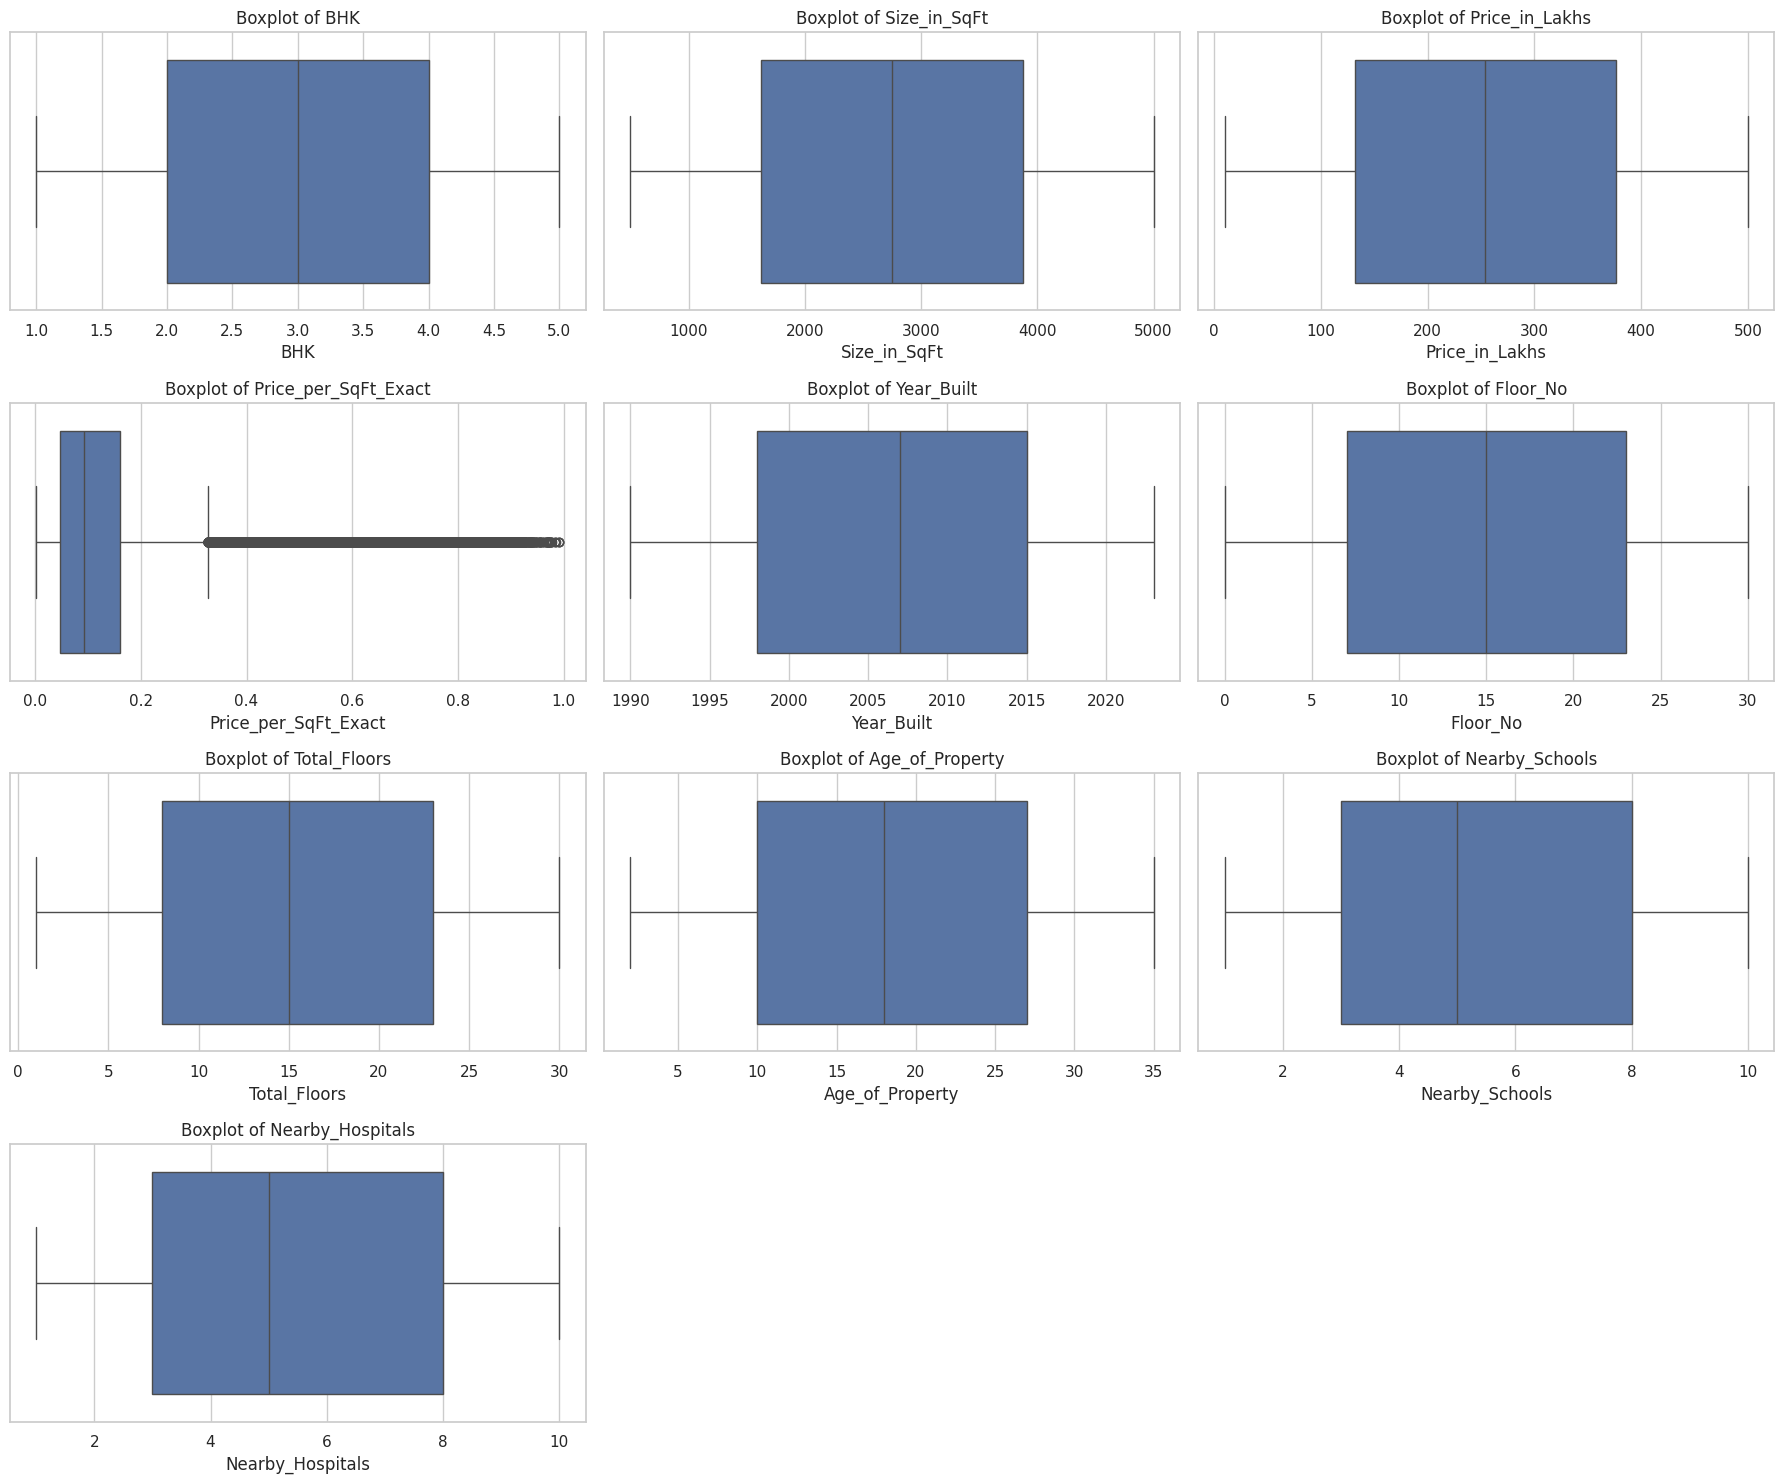

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    'BHK',
    'Size_in_SqFt',
    'Price_in_Lakhs',
    'Price_per_SqFt_Exact',
    'Year_Built',
    'Floor_No',
    'Total_Floors',
    'Age_of_Property',
    'Nearby_Schools',
    'Nearby_Hospitals'
]

plt.figure(figsize=(18, 15))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 3, i)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

### Observations

BHK: Values range from 1 to 5, with no visually apparent outliers.

Size_in_SqFt: Property sizes range from 500 to 5,000 square feet, without visually apparent outliers.

Price_in_Lakhs: Property prices range from 10 to 500 lakhs, without visually apparent outliers.

Price_per_SqFt_Exact: Several observations appear beyond the upper whisker, indicating potential high-value outliers.

Year_Built: Values range from 1990 to 2023, without visually apparent outliers.

Floor_No: Values range from 0 to 30, including valid ground-floor properties.

Total_Floors: Values range from 1 to 30, without visually apparent outliers.

Age_of_Property: Values range from 2 to 35 years, without visually apparent outliers.

Nearby_Schools: Values range from 1 to 10, without visually apparent outliers.

Nearby_Hospitals: Values range from 1 to 10, without visually apparent outliers.

The boxplot analysis indicates that most numerical features have no visually apparent outliers. However, Price_per_SqFt_Exact contains several potential high-value outliers that require further statistical investigation using the Interquartile Range (IQR) method.

Potential outliers will not be removed automatically. Their validity will be examined before deciding whether any treatment is necessary.

## Investigate Price_per_SqFt_Exact

In [ ]:
# Calculate IQR for Price_per_SqFt_Exact
Q1 = df['Price_per_SqFt_Exact'].quantile(0.25)
Q3 = df['Price_per_SqFt_Exact'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Price_per_SqFt_Exact'] < lower_bound) |
    (df['Price_per_SqFt_Exact'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nTotal potential outliers:", len(outliers))
print("Percentage of dataset:",
      round(len(outliers) / len(df) * 100, 2), "%")

print("\nHighest price per square foot records:")

display(
    df.nlargest(
        15, 'Price_per_SqFt_Exact'
    )[
        [
            'ID',
            'State',
            'City',
            'Property_Type',
            'BHK',
            'Size_in_SqFt',
            'Price_in_Lakhs',
            'Price_per_SqFt_Exact'
        ]
    ]
)

Q1: 0.04802839710440703
Q3: 0.1598738851727982
IQR: 0.11184548806839117
Lower Bound: -0.11973983499817972
Upper Bound: 0.32764211727538495

Total potential outliers: 19723
Percentage of dataset: 7.89 %

Highest price per square foot records:


,ID,State,City,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_Exact
26780,26781,Maharashtra,Nagpur,Independent House,2,500,495.91,0.991820
152905,152906,Karnataka,Mysore,Independent House,3,504,499.40,0.990873
59050,59051,Rajasthan,Jaipur,Apartment,4,503,498.12,0.990298
90192,90193,Andhra Pradesh,Vijayawada,Independent House,1,507,499.32,0.984852
162739,162740,Assam,Silchar,Villa,4,505,497.07,0.984297
121347,121348,Chhattisgarh,Raipur,Independent House,1,501,493.09,0.984212
147871,147872,Telangana,Hyderabad,Apartment,4,506,494.70,0.977668
53970,53971,Telangana,Warangal,Apartment,4,503,491.25,0.976640
148754,148755,Jharkhand,Ranchi,Apartment,3,502,490.06,0.976215
92665,92666,Delhi,Dwarka,Villa,2,501,489.06,0.976168


### Statistical Outlier Detection Using the IQR Method

The Interquartile Range (IQR) method was applied to `Price_per_SqFt_Exact` to identify potential extreme observations.

The IQR was calculated using the first quartile (Q1) and third quartile (Q3).

**Results:**

- Q1: 0.04803
- Q3: 0.15987
- IQR: 0.11185
- Lower Bound: -0.11974
- Upper Bound: 0.32764
- Total Potential Outliers: 19,723
- Percentage of Dataset: 7.89%

### Observations

The analysis identified 19,723 records above the upper IQR boundary. No lower-side outliers were identified because the lower boundary is negative while all calculated price-per-square-foot values are positive.

The highest-value records show property prices close to ₹500 lakhs and property sizes around 500 square feet, resulting in unusually high price-per-square-foot values.


The identified observations are classified as potential statistical outliers, not confirmed data errors. They will be retained temporarily while further investigation is conducted.

No automatic deletion or outlier capping will be performed at this stage.

## Potential Outliers by Property Type and State


In [ ]:
# Investigate outliers by property type
print("Outliers by Property Type:")
display(outliers['Property_Type'].value_counts())

# Investigate outliers by state
print("\nTop 10 States with Potential Outliers:")
display(outliers['State'].value_counts().head(10))

# Compare outlier and non-outlier prices
df['Is_Outlier'] = (
    df['Price_per_SqFt_Exact'] > upper_bound
)

print("\nOutlier vs Non-Outlier Summary:")
display(
    df.groupby('Is_Outlier')[
        [
            'Size_in_SqFt',
            'Price_in_Lakhs',
            'Price_per_SqFt_Exact'
        ]
    ].mean().round(3)
)

Outliers by Property Type:


,count
Property_Type,
Independent House,6622
Villa,6584
Apartment,6517



Top 10 States with Potential Outliers:


,count
State,
Tamil Nadu,1026
Karnataka,1009
Assam,1006
Odisha,1006
Gujarat,1005
West Bengal,1005
Delhi,999
Andhra Pradesh,997
Chhattisgarh,994



Outlier vs Non-Outlier Summary:


,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_Exact
Is_Outlier,,,
False,2913.324,243.191,0.100
True,840.729,387.645,0.485


### Investigation of Potential Outliers by Property Type and State

Further analysis was performed to understand the distribution of the 19,723 potential outliers identified using the IQR method.

### 1. Distribution by Property Type

| Property Type | Outlier Count |
|---|---:|
| Independent House | 6,622 |
| Villa | 6,584 |
| Apartment | 6,517 |

The outliers are distributed relatively evenly across all three property types.

### 2. Distribution by State

The top 10 states have approximately 989–1,026 potential outliers each. West Bengal accounts for 1,005 records.

This indicates that the identified observations are not concentrated in just one state.

### 3. Comparison of Outliers and Non-Outliers

| Feature | Non-Outliers | Potential Outliers |
|---|---:|---:|
| Average Size (SqFt) | 2,913.324 | 840.729 |
| Average Price (Lakhs) | 243.191 | 387.645 |
| Average Price per SqFt (Lakhs) | 0.100 | 0.485 |

The potential outlier group has a considerably smaller average property size and a higher average property price, resulting in a higher price per square foot.


The potential outliers are distributed relatively evenly across property types and states. Their higher price-per-square-foot values are associated with smaller average property sizes and higher average property prices.

These observations are not sufficient to establish that the records are incorrect.

Therefore, all potential outliers will be retained temporarily. No automatic deletion or capping will be performed.

## City-Level Investigation and Inspection of Extreme Property Values

In [ ]:
# Top 15 cities with potential outliers
print("Top 15 Cities with Potential Outliers:")

display(
    outliers['City']
    .value_counts()
    .head(15)
)

# Inspect highest-value outlier records
print("\nHighest 20 Price-per-SqFt Records:")

display(
    outliers.nlargest(20, 'Price_per_SqFt_Exact')[
        [
            'ID',
            'State',
            'City',
            'Locality',
            'Property_Type',
            'BHK',
            'Size_in_SqFt',
            'Price_in_Lakhs',
            'Price_per_SqFt_Exact'
        ]
    ]
)

Top 15 Cities with Potential Outliers:


,count
City,
Surat,530
Durgapur,524
Chennai,522
Kochi,521
Silchar,520
Haridwar,518
Bhubaneswar,515
Gaya,513
Indore,512



Highest 20 Price-per-SqFt Records:


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt_Exact
26780,26781,Maharashtra,Nagpur,Locality_384,Independent House,2,500,495.91,0.991820
152905,152906,Karnataka,Mysore,Locality_368,Independent House,3,504,499.40,0.990873
59050,59051,Rajasthan,Jaipur,Locality_10,Apartment,4,503,498.12,0.990298
90192,90193,Andhra Pradesh,Vijayawada,Locality_429,Independent House,1,507,499.32,0.984852
162739,162740,Assam,Silchar,Locality_195,Villa,4,505,497.07,0.984297
121347,121348,Chhattisgarh,Raipur,Locality_111,Independent House,1,501,493.09,0.984212
147871,147872,Telangana,Hyderabad,Locality_486,Apartment,4,506,494.70,0.977668
53970,53971,Telangana,Warangal,Locality_357,Apartment,4,503,491.25,0.976640
148754,148755,Jharkhand,Ranchi,Locality_115,Apartment,3,502,490.06,0.976215
92665,92666,Delhi,Dwarka,Locality_108,Villa,2,501,489.06,0.976168


### City-Level Investigation and Inspection of Extreme Property Values

Further investigation was conducted to understand the geographical distribution and characteristics of potential outliers in `Price_per_SqFt_Exact`.

### 1. Distribution by City

The top 15 cities with the highest numbers of potential outliers include Surat (530), Durgapur (524), Chennai (522), Kochi (521), and Silchar (520).

The observations are distributed across multiple cities, with relatively similar counts among the leading cities.

### 2. Inspection of Highest-Value Records

The 20 highest price-per-square-foot records were examined.

The following characteristics were observed:

- Property sizes are approximately 500–515 square feet.
- Property prices are approximately ₹486–500 lakhs.
- Calculated price per square foot ranges approximately from 0.97 to 0.99 lakhs.

These records have unusually high price-per-square-foot values compared with the overall dataset distribution.


The city-level distribution does not indicate concentration in a single city. The highest-value records show a repeated combination of relatively small property sizes and high total prices.

Although these observations are statistically unusual, their accuracy cannot be independently confirmed from the available dataset.

Therefore, potential outliers will be retained without automatic deletion or capping at this stage.

##  Data Preprocessing


In [ ]:
# Final dataset consistency check

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate IDs:")
print(df['ID'].duplicated().sum())

print("\nData Types:")
display(df.dtypes)

print("\nNumerical Summary:")
display(df.describe().T)

Dataset Shape: (250000, 25)

Missing Values:
0

Duplicate Rows:
0

Duplicate IDs:
0

Data Types:


,0
ID,int64
State,object
City,object
Locality,object
Property_Type,object
BHK,int64
Size_in_SqFt,int64
Price_in_Lakhs,float64
Price_per_SqFt,float64
Year_Built,int64



Numerical Summary:


,count,mean,std,min,25%,50%,75%,max
ID,250000.0,125000.500000,72168.927986,1.000000,62500.750000,125000.500000,187500.250000,250000.00000
BHK,250000.0,2.999396,1.415521,1.000000,2.000000,3.000000,4.000000,5.00000
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.000000,1623.000000,2747.000000,3874.000000,5000.00000
Price_in_Lakhs,250000.0,254.586854,141.349921,10.000000,132.550000,253.870000,376.880000,500.00000
Price_per_SqFt,250000.0,0.130597,0.130747,0.000000,0.050000,0.090000,0.160000,0.99000
Year_Built,250000.0,2006.520012,9.808575,1990.000000,1998.000000,2007.000000,2015.000000,2023.00000
Floor_No,250000.0,14.966800,8.948047,0.000000,7.000000,15.000000,23.000000,30.00000
Total_Floors,250000.0,15.503004,8.671618,1.000000,8.000000,15.000000,23.000000,30.00000
Age_of_Property,250000.0,18.479988,9.808575,2.000000,10.000000,18.000000,27.000000,35.00000
Nearby_Schools,250000.0,5.499860,2.878639,1.000000,3.000000,5.000000,8.000000,10.00000


In [ ]:
# Impute: median for numeric, mode for categorical
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

for c in num_cols:
    df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

df.isna().sum().sum()

np.int64(0)

##  Feature engineering

In [ ]:
# Identify categorical and numerical columns

categorical_cols = df.select_dtypes(
    include=['object']
).columns.tolist()

numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical Columns:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical Columns:", len(numerical_cols))
print(numerical_cols)


# Check unique categories in each categorical column

print("\nUnique Values in Categorical Features:")

for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values")


# Check logical consistency of floor information

invalid_floor = df[
    df['Floor_No'] > df['Total_Floors']
]

print("\nProperties where Floor_No > Total_Floors:",
      len(invalid_floor))


# Check consistency of property age

age_mismatch = (
    df['Age_of_Property'] != (2025 - df['Year_Built'])
)

print("Age calculation mismatches:", age_mismatch.sum())

Categorical Columns: 12
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']

Numerical Columns: 12
['ID', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Price_per_SqFt_Exact']

Unique Values in Categorical Features:
State: 20 unique values
City: 42 unique values
Locality: 500 unique values
Property_Type: 3 unique values
Furnished_Status: 3 unique values
Public_Transport_Accessibility: 3 unique values
Parking_Space: 2 unique values
Security: 2 unique values
Amenities: 325 unique values
Facing: 4 unique values
Owner_Type: 3 unique values
Availability_Status: 2 unique values

Properties where Floor_No > Total_Floors: 116304
Age calculation mismatches: 0


## Categorical Feature Analysis and Logical Consistency Checks


This stage examines categorical feature cardinality and checks logical consistency between numerical features before applying encoding and preprocessing techniques.

### 1. Categorical Feature Cardinality

The dataset contains 12 categorical features with different numbers of unique categories.

- `State`: 20 unique values.
- `City`: 42 unique values.
- `Locality`: 500 unique values.
- `Amenities`: 325 unique values.
- Other categorical features contain between 2 and 4 unique values.

High-cardinality features such as `Locality` and `Amenities` require further investigation before selecting an encoding strategy.

### 2. Numerical Feature Consistency

The age calculation check identified zero mismatches between `Age_of_Property` and `2025 - Year_Built`.

However, 116,304 records have `Floor_No` greater than `Total_Floors`, indicating a potential logical inconsistency.


Categorical feature encoding strategies will be selected after examining category distributions. The floor-related inconsistency and high-cardinality features will be investigated before preprocessing.

 ## Floor Number and Total Floors Inconsistency


In [ ]:
# Investigate floor inconsistencies

invalid_floor = df[
    df['Floor_No'] > df['Total_Floors']
].copy()

print("Total inconsistent records:", len(invalid_floor))
print(
    "Percentage:",
    round(len(invalid_floor) / len(df) * 100, 2),
    "%"
)

print("\nFirst 20 inconsistent records:")

display(
    invalid_floor[
        [
            'ID',
            'Property_Type',
            'Floor_No',
            'Total_Floors',
            'Availability_Status'
        ]
    ].head(20)
)

print("\nFloor number distribution:")
display(df['Floor_No'].value_counts().sort_index())

print("\nTotal floors distribution:")
display(df['Total_Floors'].value_counts().sort_index())

print("\nFloor consistency by property type:")
display(
    df.assign(
        Invalid_Floor=df['Floor_No'] > df['Total_Floors']
    ).groupby('Property_Type')['Invalid_Floor'].agg(
        ['sum', 'count', 'mean']
    )
)

Total inconsistent records: 116304
Percentage: 46.52 %

First 20 inconsistent records:


,ID,Property_Type,Floor_No,Total_Floors,Availability_Status
0,1,Apartment,22,1,Ready_to_Move
1,2,Independent House,21,20,Under_Construction
4,5,Villa,3,2,Ready_to_Move
5,6,Apartment,27,1,Ready_to_Move
6,7,Independent House,16,5,Under_Construction
7,8,Independent House,24,4,Under_Construction
8,9,Villa,23,16,Under_Construction
12,13,Independent House,9,1,Ready_to_Move
13,14,Independent House,13,4,Under_Construction
14,15,Apartment,26,18,Ready_to_Move



Floor number distribution:


,count
Floor_No,
0,8203
1,8076
2,8125
3,8073
4,7949
5,8174
6,8166
7,8106
8,8149



Total floors distribution:


,count
Total_Floors,
1,8347
2,8380
3,8439
4,8297
5,8501
6,8327
7,8216
8,8301
9,8416



Floor consistency by property type:


,sum,count,mean
Property_Type,,,
Apartment,38639,82956,0.465777
Independent House,38655,83300,0.464046
Villa,39010,83744,0.465824


### Investigation of Floor Number and Total Floors Inconsistency

A logical consistency check was performed between `Floor_No` and `Total_Floors`.

The expected condition is:

`Floor_No` should be less than or equal to `Total_Floors`.

### Investigation Results

- Total inconsistent records: 116,304
- Percentage of dataset: 46.52%
- Apartment inconsistencies: 38,639
- Independent House inconsistencies: 38,655
- Villa inconsistencies: 39,010

#### Observations

1. A substantial proportion of records have `Floor_No` greater than `Total_Floors`.
2. The issue occurs across all three property types.
3. The inconsistency percentages are approximately 46% for each property type.
4. Both columns contain values ranging from 0–30 and 1–30, respectively.


The floor-related inconsistency requires further investigation because it affects a significant portion of the dataset.

No values will be modified or removed until the underlying data-generation pattern is better understood. The two features will be evaluated before final feature selection and preprocessing.

## Investigation of the Amenities Feature

In [ ]:
print("Total unique Amenities:", df['Amenities'].nunique())

print("\nMost frequent Amenities combinations:")

display(
    df['Amenities'].value_counts().head(30)
)

print("\nSample Amenities values:")

display(
    df[['ID', 'Amenities']].sample(
        20, random_state=42
    )
)

Total unique Amenities: 325

Most frequent Amenities combinations:


,count
Amenities,
Pool,10218
Clubhouse,10010
Garden,10006
Gym,9938
Playground,9934
"Pool, Playground",2545
"Gym, Pool",2534
"Garden, Clubhouse",2524
"Gym, Playground",2524



Sample Amenities values:


,ID,Amenities
38683,38684,"Playground, Pool"
64939,64940,"Gym, Clubhouse, Pool, Garden"
3954,3955,"Gym, Pool, Playground, Clubhouse, Garden"
120374,120375,"Pool, Gym"
172861,172862,Pool
149303,149304,"Clubhouse, Gym"
111626,111627,"Playground, Pool, Gym, Clubhouse, Garden"
164553,164554,"Pool, Clubhouse, Playground, Gym, Garden"
55779,55780,"Garden, Playground, Gym, Clubhouse, Pool"
141990,141991,"Garden, Playground, Gym, Pool"


### Investigation of the Amenities Feature

The `Amenities` column contains 325 unique categorical combinations.

Further inspection of the most frequent values and sample records identified five individual amenities:

- Pool
- Gym
- Garden
- Clubhouse
- Playground

### Observations

1. Individual amenities appear separately as well as in combinations.
2. The order of amenities varies between records. For example, `Gym, Pool` and `Pool, Gym` represent the same combination.
3. Different combinations of the five amenities create a high number of unique categorical values.
4. Direct One-Hot Encoding of all 325 combinations may unnecessarily increase the feature dimensions.


The `Amenities` column will be transformed into five individual binary features. Each feature will indicate whether a particular amenity is available for a property.

This approach preserves the individual amenity information while avoiding unnecessary categorical combinations.

## Amenities Transformation

In [ ]:
# Extract individual amenities

amenity_list = [
    'Pool',
    'Gym',
    'Garden',
    'Clubhouse',
    'Playground'
]

for amenity in amenity_list:
    df[f'Amenity_{amenity}'] = (
        df['Amenities']
        .str.split(',')
        .apply(lambda x: amenity in [item.strip() for item in x])
        .astype(int)
    )

# Verify the new features

amenity_features = [
    f'Amenity_{amenity}' for amenity in amenity_list
]

display(df[[
    'Amenities'
] + amenity_features].head(15))

print("\nAmenity feature totals:")
display(df[amenity_features].sum())

print("\nUpdated dataset shape:", df.shape)

,Amenities,Amenity_Pool,Amenity_Gym,Amenity_Garden,Amenity_Clubhouse,Amenity_Playground
0,"Playground, Gym, Garden, Pool, Clubhouse",1,1,1,1,1
1,"Playground, Clubhouse, Pool, Gym, Garden",1,1,1,1,1
2,"Clubhouse, Pool, Playground, Gym",1,1,0,1,1
3,"Playground, Clubhouse, Gym, Pool, Garden",1,1,1,1,1
4,"Playground, Garden, Gym, Pool, Clubhouse",1,1,1,1,1
5,"Playground, Clubhouse",0,0,0,1,1
6,"Clubhouse, Garden, Playground",0,0,1,1,1
7,"Gym, Pool, Clubhouse, Playground",1,1,0,1,1
8,"Garden, Clubhouse, Playground",0,0,1,1,1
9,"Clubhouse, Playground, Garden, Gym",0,1,1,1,1



Amenity feature totals:


,0
Amenity_Pool,150096
Amenity_Gym,149960
Amenity_Garden,150177
Amenity_Clubhouse,150059
Amenity_Playground,149780



Updated dataset shape: (250000, 30)


### Feature Engineering: Amenities Transformation

The original `Amenities` column contained 325 unique combinations of five individual amenities.

To reduce categorical complexity and preserve individual amenity information, the column was transformed into five binary features:

1. `Amenity_Pool`
2. `Amenity_Gym`
3. `Amenity_Garden`
4. `Amenity_Clubhouse`
5. `Amenity_Playground`

Each feature uses binary encoding:
- 1: The property contains the respective amenity.
- 0: The property does not contain the respective amenity.

#### Results

| Feature | Properties with Amenity |
|---|---:|
| Amenity_Pool | 150,096 |
| Amenity_Gym | 149,960 |
| Amenity_Garden | 150,177 |
| Amenity_Clubhouse | 150,059 |
| Amenity_Playground | 149,780 |


The transformation successfully converts the original multi-category amenity combinations into five independent binary features.

The original `Amenities` column is retained temporarily for verification. The five engineered features will be considered for subsequent machine learning preprocessing.

## Statistical Analysis of Floor-Related Features

In [ ]:
print("Correlation between Floor_No and Total_Floors:")

display(
    df[['Floor_No', 'Total_Floors']].corr()
)

print("\nAverage floor values by property type:")

display(
    df.groupby('Property_Type')[
        ['Floor_No', 'Total_Floors']
    ].mean().round(2)
)

print("\nFloor inconsistency percentage by property type:")

display(
    df.assign(
        Invalid_Floor=df['Floor_No'] > df['Total_Floors']
    ).groupby('Property_Type')['Invalid_Floor'].mean()
    .mul(100).round(2)
)

Correlation between Floor_No and Total_Floors:


,Floor_No,Total_Floors
Floor_No,1.000000,0.001169
Total_Floors,0.001169,1.000000



Average floor values by property type:


,Floor_No,Total_Floors
Property_Type,,
Apartment,14.98,15.5
Independent House,14.96,15.5
Villa,14.96,15.5



Floor inconsistency percentage by property type:


,Invalid_Floor
Property_Type,
Apartment,46.58
Independent House,46.40
Villa,46.58


## Verification of Engineered Amenity Features

In [ ]:
# Check engineered amenity features
amenity_features = [
    'Amenity_Pool',
    'Amenity_Gym',
    'Amenity_Garden',
    'Amenity_Clubhouse',
    'Amenity_Playground'
]

print("Amenity features verification:")
display(df[amenity_features].describe().T)

# Check whether original Amenities can be removed later
print("\nOriginal Amenities unique values:",
      df['Amenities'].nunique())

# Check dataset dimensions
print("\nFinal current dataset shape:", df.shape)

# Check missing values after feature engineering
print("\nTotal missing values:", df.isnull().sum().sum())

Amenity features verification:


,count,mean,std,min,25%,50%,75%,max
Amenity_Pool,250000.0,0.600384,0.489820,0.0,0.0,1.0,1.0,1.0
Amenity_Gym,250000.0,0.599840,0.489932,0.0,0.0,1.0,1.0,1.0
Amenity_Garden,250000.0,0.600708,0.489754,0.0,0.0,1.0,1.0,1.0
Amenity_Clubhouse,250000.0,0.600236,0.489851,0.0,0.0,1.0,1.0,1.0
Amenity_Playground,250000.0,0.599120,0.490078,0.0,0.0,1.0,1.0,1.0



Original Amenities unique values: 325

Final current dataset shape: (250000, 30)

Total missing values: 0


## Target Variable Engineering

This project requires two target variables for separate machine learning tasks.

### A. Classification Target: Good_Investment

A multi-factor scoring approach will be used to classify properties.

The five criteria are:

1. **Price per SqFt:** Property price per square foot is less than or equal to the city median.
2. **Price vs City/BHK Median:** Property price is less than or equal to the median property price for the same city and BHK category.
3. **BHK:** Property has at least 3 BHK.
4. **Availability:** Property is ready to move.
5. **Infrastructure:** Infrastructure score is above the median.

Each satisfied criterion contributes one point.

The final classification label will be:
- 1: Good Investment, if the total score meets the selected threshold.
- 0: Not classified as Good Investment, otherwise.

### B. Regression Target: Future_Price_5Y

The five-year estimated property price will be calculated using compound annual appreciation:

Future Price = Current Price × (1 + r)^5

Where:
- Current Price = `Price_in_Lakhs`
- r = Annual appreciation rate for the property city
- 5 = Forecast period in years

City-specific appreciation rates must be documented and justified.

### C. Data Leakage Prevention

Features used to construct the target variables will be reviewed carefully before model training. Target-generation variables will not automatically be included as model predictors.

The five-year target is an appreciation-based scenario estimate, not an observed future market price.

In [ ]:
# Inspect infrastructure-related features

print("Public Transport Accessibility:")
display(
    df['Public_Transport_Accessibility'].value_counts()
)

print("\nNearby Schools:")
display(
    df['Nearby_Schools'].value_counts().sort_index()
)

print("\nNearby Hospitals:")
display(
    df['Nearby_Hospitals'].value_counts().sort_index()
)

Public Transport Accessibility:


,count
Public_Transport_Accessibility,
High,83705
Low,83287
Medium,83008



Nearby Schools:


,count
Nearby_Schools,
1,25360
2,24851
3,25045
4,24739
5,25023
6,24824
7,24808
8,25290
9,24823



Nearby Hospitals:


,count
Nearby_Hospitals,
1,25075
2,24960
3,24834
4,25168
5,25102
6,25082
7,24887
8,24891
9,25014


### Feature Engineering: Infrastructure Score

An infrastructure score will be created using three available features:

1. `Nearby_Schools`
2. `Nearby_Hospitals`
3. `Public_Transport_Accessibility`


The number of nearby schools and hospitals will be normalized using Min-Max scaling.

Public transport accessibility will be encoded as:
- Low = 0
- Medium = 0.5
- High = 1

The three normalized scores will receive equal weights.

**Infrastructure Score:**

Infrastructure Score = (School Score + Hospital Score + Transport Score) / 3

A higher score indicates better infrastructure based on the available dataset indicators.

The score will be used to construct the `Good_Investment` classification target.

## Verification of Infrastructure Score

In [ ]:
# Create normalized infrastructure components

df['School_Score'] = (
    (df['Nearby_Schools'] - df['Nearby_Schools'].min()) /
    (df['Nearby_Schools'].max() - df['Nearby_Schools'].min())
)

df['Hospital_Score'] = (
    (df['Nearby_Hospitals'] - df['Nearby_Hospitals'].min()) /
    (df['Nearby_Hospitals'].max() - df['Nearby_Hospitals'].min())
)

transport_mapping = {
    'Low': 0,
    'Medium': 0.5,
    'High': 1
}

df['Transport_Score'] = (
    df['Public_Transport_Accessibility'].map(transport_mapping)
)

# Calculate infrastructure score

df['Infrastructure_Score'] = (
    df['School_Score'] +
    df['Hospital_Score'] +
    df['Transport_Score']
) / 3

# Verify the result

display(
    df[
        [
            'Nearby_Schools',
            'Nearby_Hospitals',
            'Public_Transport_Accessibility',
            'Infrastructure_Score'
        ]
    ].head(10)
)

print("\nInfrastructure score statistics:")
display(df['Infrastructure_Score'].describe())

print(
    "\nMissing infrastructure scores:",
    df['Infrastructure_Score'].isnull().sum()
)

,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Infrastructure_Score
0,10,3,High,0.740741
1,8,1,Low,0.259259
2,9,8,Low,0.555556
3,5,7,High,0.703704
4,4,9,Low,0.407407
5,7,7,Low,0.444444
6,3,6,High,0.592593
7,10,10,High,1.000000
8,7,5,Low,0.370370
9,3,3,High,0.481481



Infrastructure score statistics:


,Infrastructure_Score
count,250000.000000
mean,0.500200
std,0.202939
min,0.000000
25%,0.351852
50%,0.500000
75%,0.648148
max,1.000000



Missing infrastructure scores: 0




The engineered `Infrastructure_Score` feature was evaluated using descriptive statistical analysis.

### Results

| Statistical Measure | Value |
|---|---:|
| Count | 250,000 |
| Mean | 0.500200 |
| Standard Deviation | 0.202939 |
| Minimum | 0.000000 |
| Median | 0.500000 |
| Maximum | 1.000000 |

#### Observations

1. All 250,000 records have valid infrastructure scores.
2. The score ranges from 0 to 1.
3. The average infrastructure score is approximately 0.50.
4. No missing values were introduced.
5. The feature combines nearby schools, nearby hospitals, and public transport accessibility.


The infrastructure feature engineering process was completed successfully. The `Infrastructure_Score` feature will be used during the construction of the `Good_Investment` classification target.

## Availability Status Analysis

In [ ]:
print("Availability Status Distribution:")

display(
    df['Availability_Status'].value_counts()
)

Availability Status Distribution:


,count
Availability_Status,
Under_Construction,125035
Ready_to_Move,124965




The `Availability_Status` feature was examined before constructing the `Good_Investment` classification target.

#### Results

| Availability Status | Property Count |
|---|---:|
| Ready_to_Move | 124,965 |
| Under_Construction | 125,035 |


1. The dataset contains two availability categories.
2. Approximately 49.99% of properties are ready to move.
3. Approximately 50.01% of properties are under construction.
4. No missing availability values were identified.


The `Ready_to_Move` category will contribute one point to the multi-factor classification score when constructing the `Good_Investment` target.

## Investment Score Distribution and Classification Threshold

In [ ]:
# Calculate city-wise median price per square foot
city_median_price_sqft = (
    df.groupby('City')['Price_per_SqFt_Exact']
    .transform('median')
)

# Calculate city and BHK-wise median property price
city_bhk_median_price = (
    df.groupby(['City', 'BHK'])['Price_in_Lakhs']
    .transform('median')
)

# Criterion 1: Price per SqFt <= city median
df['Score_Price_per_SqFt'] = (
    df['Price_per_SqFt_Exact'] <= city_median_price_sqft
).astype(int)

# Criterion 2: Price <= city/BHK median
df['Score_Price'] = (
    df['Price_in_Lakhs'] <= city_bhk_median_price
).astype(int)

# Criterion 3: BHK >= 3
df['Score_BHK'] = (
    df['BHK'] >= 3
).astype(int)

# Criterion 4: Ready to Move
df['Score_Availability'] = (
    df['Availability_Status'] == 'Ready_to_Move'
).astype(int)

# Criterion 5: Infrastructure above median
infrastructure_median = df['Infrastructure_Score'].median()

df['Score_Infrastructure'] = (
    df['Infrastructure_Score'] > infrastructure_median
).astype(int)

# Calculate total investment score
score_columns = [
    'Score_Price_per_SqFt',
    'Score_Price',
    'Score_BHK',
    'Score_Availability',
    'Score_Infrastructure'
]

df['Investment_Score'] = df[score_columns].sum(axis=1)

# Display results
display(
    df[
        [
            'City',
            'BHK',
            'Price_in_Lakhs',
            'Price_per_SqFt_Exact',
            'Availability_Status',
            'Infrastructure_Score',
            'Investment_Score'
        ] + score_columns
    ].head(10)
)

print("\nInvestment score distribution:")
display(df['Investment_Score'].value_counts().sort_index())

,City,BHK,Price_in_Lakhs,Price_per_SqFt_Exact,Availability_Status,Infrastructure_Score,Investment_Score,Score_Price_per_SqFt,Score_Price,Score_BHK,Score_Availability,Score_Infrastructure
0,Chennai,1,489.76,0.103325,Ready_to_Move,0.740741,2,0,0,0,1,1
1,Pune,3,195.52,0.082707,Under_Construction,0.259259,3,1,1,1,0,0
2,Ludhiana,2,183.79,0.050464,Ready_to_Move,0.555556,4,1,1,0,1,1
3,Jodhpur,2,300.29,0.109555,Ready_to_Move,0.703704,2,0,0,0,1,1
4,Jaipur,4,182.90,0.037922,Ready_to_Move,0.407407,4,1,1,1,1,0
5,Durgapur,4,135.28,0.038651,Ready_to_Move,0.444444,4,1,1,1,1,0
6,Coimbatore,3,318.12,0.065918,Under_Construction,0.592593,3,1,0,1,0,1
7,Bilaspur,5,141.39,0.033253,Under_Construction,1.000000,4,1,1,1,0,1
8,New Delhi,4,189.16,0.070635,Under_Construction,0.370370,3,1,1,1,0,0
9,Ranchi,2,187.42,0.134544,Ready_to_Move,0.481481,2,0,1,0,1,0



Investment score distribution:


,count
Investment_Score,
0,10221
1,40486
2,67841
3,70219
4,46941
5,14292




The five-factor investment scoring system was applied to all 250,000 property records.

### Investment Score Distribution

| Investment Score | Property Count |
|---|---:|
| 0 | 10,221 |
| 1 | 40,486 |
| 2 | 67,841 |
| 3 | 70,219 |
| 4 | 46,941 |
| 5 | 14,292 |

### Classification Threshold

A threshold of 3 points out of 5 was selected.

- Score greater than or equal to 3: Good Investment (1).
- Score below 3: Not Good Investment (0).

### Expected Class Distribution

- Good Investment: 131,452 (52.58%).
- Not Good Investment: 118,548 (47.42%).


The selected threshold provides a reasonably balanced target distribution, making it suitable for initial classification experiments.

The classification label represents the project's rule-based investment attractiveness assessment, not verified profitability or guaranteed investment returns.

## Classification Target Distribution Analysis

In [ ]:
# Create classification target

df['Good_Investment'] = (
    df['Investment_Score'] >= 3
).astype(int)

# Verify target distribution

print("Good Investment Target Distribution:")

display(
    df['Good_Investment'].value_counts()
    .sort_index()
)

print("\nTarget distribution in percentage:")

display(
    df['Good_Investment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nFinal dataset shape:", df.shape)

Good Investment Target Distribution:


,count
Good_Investment,
0,118548
1,131452



Target distribution in percentage:


,proportion
Good_Investment,
1,52.58
0,47.42



Final dataset shape: (250000, 41)




The `Good_Investment` target variable was successfully generated using a five-factor investment scoring methodology.

The final distribution is:

- **Good Investment (1):** 131,452 records (52.58%)
- **Not Good Investment (0):** 118,548 records (47.42%)

The final dataset contains **250,000 records and 41 columns**.

The target distribution indicates a reasonably balanced classification problem. Therefore, no immediate class-balancing technique is required. Model performance will be evaluated using accuracy, precision, recall, F1-score and a confusion matrix.

**Note:** The target is based on predefined investment criteria and represents rule-based investment attractiveness, not independently verified property profitability.

## Regression Target Creation: Future Property Price After 5 Years

**Objective:** Estimate the property price after five years using the annual appreciation-rate methodology described in the project guide.

The project guide provides the following formula:

Future Price = Current Price × (1 + r)^t

Where:
- Current Price = `Price_in_Lakhs`
- Annual Appreciation Rate (r) = 8% or 0.08
- Time Period (t) = 5 years

Since the dataset does not contain actual future property prices or city-wise appreciation rates, a fixed annual appreciation rate of 8% will be used as the baseline assumption.

**Important:** The generated target is a simulated future price, not an actual observed market price.

In [ ]:
# Annual appreciation rate and forecast period
annual_appreciation_rate = 0.08
forecast_years = 5

# Create the regression target
df['Future_Price_5Y'] = (
    df['Price_in_Lakhs'] *
    (1 + annual_appreciation_rate) ** forecast_years
)

# Display sample results
df[['Price_in_Lakhs', 'Future_Price_5Y']].head(10)

,Price_in_Lakhs,Future_Price_5Y
0,489.76,719.618119
1,195.52,287.283026
2,183.79,270.047807
3,300.29,441.224528
4,182.90,268.740105
5,135.28,198.770702
6,318.12,467.422648
7,141.39,207.748297
8,189.16,277.938099
9,187.42,275.381468


In [ ]:
# Summary statistics
print("Future Price Summary:")
display(df['Future_Price_5Y'].describe())

# Check missing values
print("Missing values:", df['Future_Price_5Y'].isnull().sum())

# Check infinite values
print("Infinite values:",
      np.isinf(df['Future_Price_5Y']).sum())

# Final dataset shape
print("Final dataset shape:", df.shape)

Future Price Summary:


,Future_Price_5Y
count,250000.000000
mean,374.071613
std,207.689408
min,14.693281
25%,194.759437
50%,373.018319
75%,553.760366
max,734.664038


Missing values: 0
Infinite values: 0
Final dataset shape: (250000, 42)


## Regression Target Validation

The `Future_Price_5Y` target variable was successfully generated using the fixed annual appreciation rate of 8% over a five-year period.

The resulting dataset contains 250,000 records and 42 columns.

Validation confirmed:
- No missing values in the regression target.
- No infinite values.
- All 250,000 records have a calculated future price.

The future price ranges from approximately 14.69 lakhs to 734.66 lakhs, with a mean of 374.07 lakhs.

The generated target is a simulated estimate based on the appreciation-rate assumption specified in the project guide. It does not represent independently observed future property prices.

## Feature Selection for Classification and Regression

Feature selection is performed to identify relevant input variables for both machine learning tasks.

This project contains two target variables:

1. `Good_Investment` – Classification target.
2. `Future_Price_5Y` – Regression target.

Separate predictor sets will be prepared for both tasks. Identifier columns, target variables, unnecessary raw columns and features that could cause target leakage will be excluded where appropriate.

The original dataset will be preserved throughout this process.

In [ ]:
# Display all dataset columns with their data types

feature_summary = pd.DataFrame({
    'Column_Name': df.columns,
    'Data_Type': df.dtypes.astype(str).values,
    'Unique_Values': df.nunique().values
})

display(feature_summary)

,Column_Name,Data_Type,Unique_Values
0,ID,int64,250000
1,State,object,20
2,City,object,42
3,Locality,object,500
4,Property_Type,object,3
5,BHK,int64,5
6,Size_in_SqFt,int64,4501
7,Price_in_Lakhs,float64,48700
8,Price_per_SqFt,float64,100
9,Year_Built,int64,34


In [ ]:
print("Dataset shape:", df.shape)

print("\nClassification target:")
print(df['Good_Investment'].value_counts())

print("\nRegression target:")
print(df['Future_Price_5Y'].describe())

print("\nTotal columns:", len(df.columns))

Dataset shape: (250000, 42)

Classification target:
Good_Investment
1    131452
0    118548
Name: count, dtype: int64

Regression target:
count    250000.000000
mean        374.071613
std         207.689408
min          14.693281
25%         194.759437
50%         373.018319
75%         553.760366
max         734.664038
Name: Future_Price_5Y, dtype: float64

Total columns: 42


In [ ]:
# Columns excluded from both models
common_exclude = [
    'ID',
    'Floor_No',
    'Total_Floors',
    'Amenities',
    'Is_Outlier'
]

# Classification-specific exclusions
classification_exclude = common_exclude + [
    'Price_in_Lakhs',
    'Price_per_SqFt',
    'Price_per_SqFt_Exact',
    'BHK',
    'Availability_Status',
    'Nearby_Schools',
    'Nearby_Hospitals',
    'Public_Transport_Accessibility',
    'School_Score',
    'Hospital_Score',
    'Transport_Score',
    'Infrastructure_Score',
    'Score_Price_per_SqFt',
    'Score_Price',
    'Score_BHK',
    'Score_Availability',
    'Score_Infrastructure',
    'Investment_Score',
    'Good_Investment',
    'Future_Price_5Y'
]

# Regression-specific exclusions
regression_exclude = common_exclude + [
    'Price_per_SqFt',
    'Price_per_SqFt_Exact',
    'Future_Price_5Y',
    'Score_Price_per_SqFt',
    'Score_Price',
    'Score_BHK',
    'Score_Availability',
    'Score_Infrastructure',
    'Investment_Score',
    'Good_Investment'
]

# Create predictor datasets
X_classification = df.drop(columns=classification_exclude)
y_classification = df['Good_Investment']

X_regression = df.drop(columns=regression_exclude)
y_regression = df['Future_Price_5Y']

# Display dimensions
print("Classification Features:", X_classification.shape)
print("Classification Target:", y_classification.shape)

print("\nRegression Features:", X_regression.shape)
print("Regression Target:", y_regression.shape)

Classification Features: (250000, 17)
Classification Target: (250000,)

Regression Features: (250000, 27)
Regression Target: (250000,)


In [ ]:
print("CLASSIFICATION FEATURES")
print(X_classification.columns.tolist())

print("\nREGRESSION FEATURES")
print(X_regression.columns.tolist())

CLASSIFICATION FEATURES
['State', 'City', 'Locality', 'Property_Type', 'Size_in_SqFt', 'Year_Built', 'Furnished_Status', 'Age_of_Property', 'Parking_Space', 'Security', 'Facing', 'Owner_Type', 'Amenity_Pool', 'Amenity_Gym', 'Amenity_Garden', 'Amenity_Clubhouse', 'Amenity_Playground']

REGRESSION FEATURES
['State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Year_Built', 'Furnished_Status', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Facing', 'Owner_Type', 'Availability_Status', 'Amenity_Pool', 'Amenity_Gym', 'Amenity_Garden', 'Amenity_Clubhouse', 'Amenity_Playground', 'School_Score', 'Hospital_Score', 'Transport_Score', 'Infrastructure_Score']


## Data Preprocessing: Numerical and Categorical Feature Identification

Before training machine learning models, numerical and categorical variables must be identified separately.

- Numerical features will be scaled using an appropriate scaling technique.
- Categorical features will be encoded into numerical representations.
- Separate preprocessing configurations will be prepared for classification and regression.

The preprocessing transformations will be fitted only on the training data to prevent data leakage.

In [ ]:
# Identify numerical and categorical features

classification_num = X_classification.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

classification_cat = X_classification.select_dtypes(
    include=['object']
).columns.tolist()

regression_num = X_regression.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

regression_cat = X_regression.select_dtypes(
    include=['object']
).columns.tolist()


# Display classification feature groups
print("CLASSIFICATION NUMERICAL FEATURES:")
print(classification_num)
print("Total:", len(classification_num))

print("\nCLASSIFICATION CATEGORICAL FEATURES:")
print(classification_cat)
print("Total:", len(classification_cat))


# Display regression feature groups
print("\nREGRESSION NUMERICAL FEATURES:")
print(regression_num)
print("Total:", len(regression_num))

print("\nREGRESSION CATEGORICAL FEATURES:")
print(regression_cat)
print("Total:", len(regression_cat))

CLASSIFICATION NUMERICAL FEATURES:
['Size_in_SqFt', 'Year_Built', 'Age_of_Property', 'Amenity_Pool', 'Amenity_Gym', 'Amenity_Garden', 'Amenity_Clubhouse', 'Amenity_Playground']
Total: 8

CLASSIFICATION CATEGORICAL FEATURES:
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Parking_Space', 'Security', 'Facing', 'Owner_Type']
Total: 9

REGRESSION NUMERICAL FEATURES:
['BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Year_Built', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Amenity_Pool', 'Amenity_Gym', 'Amenity_Garden', 'Amenity_Clubhouse', 'Amenity_Playground', 'School_Score', 'Hospital_Score', 'Transport_Score', 'Infrastructure_Score']
Total: 16

REGRESSION CATEGORICAL FEATURES:
['State', 'City', 'Locality', 'Property_Type', 'Furnished_Status', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Facing', 'Owner_Type', 'Availability_Status']
Total: 11


## Train-Test Split

The dataset is divided into training and testing subsets before preprocessing and model development.

An 80:20 split is used:
- 80% for model training.
- 20% for model testing.

For classification, stratified sampling is applied to preserve the proportion of both target classes in the training and testing datasets.

A fixed random state of 42 ensures reproducibility.

Preprocessing transformations will be fitted exclusively on the training data.

In [ ]:
from sklearn.model_selection import train_test_split

# Classification train-test split
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_classification,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)

# Regression train-test split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_regression,
    y_regression,
    test_size=0.20,
    random_state=42
)

# Display dataset shapes
print("CLASSIFICATION")
print("Training features:", X_train_cls.shape)
print("Testing features:", X_test_cls.shape)
print("Training target:", y_train_cls.shape)
print("Testing target:", y_test_cls.shape)

print("\nREGRESSION")
print("Training features:", X_train_reg.shape)
print("Testing features:", X_test_reg.shape)
print("Training target:", y_train_reg.shape)
print("Testing target:", y_test_reg.shape)

CLASSIFICATION
Training features: (200000, 17)
Testing features: (50000, 17)
Training target: (200000,)
Testing target: (50000,)

REGRESSION
Training features: (200000, 27)
Testing features: (50000, 27)
Training target: (200000,)
Testing target: (50000,)


In [ ]:
print("Original target distribution:")
print(y_classification.value_counts(normalize=True) * 100)

print("\nTraining target distribution:")
print(y_train_cls.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test_cls.value_counts(normalize=True) * 100)

Original target distribution:
Good_Investment
1    52.5808
0    47.4192
Name: proportion, dtype: float64

Training target distribution:
Good_Investment
1    52.581
0    47.419
Name: proportion, dtype: float64

Testing target distribution:
Good_Investment
1    52.58
0    47.42
Name: proportion, dtype: float64


### Train-Test Split Validation

The classification dataset was divided using stratified sampling.

The original, training and testing datasets maintain nearly identical target proportions:

- Good Investment: approximately 52.58%
- Not Good Investment: approximately 47.42%

The regression dataset was divided using a standard random 80:20 split.

Both datasets contain 200,000 training records and 50,000 testing records. The split was performed using `random_state=42` to ensure reproducibility.

## Build Preprocessing Pipelines

In [ ]:
# Remove redundant Year_Built feature

X_train_cls = X_train_cls.drop(columns=['Year_Built'])
X_test_cls = X_test_cls.drop(columns=['Year_Built'])

X_train_reg = X_train_reg.drop(columns=['Year_Built'])
X_test_reg = X_test_reg.drop(columns=['Year_Built'])

# Update numerical and categorical feature lists

classification_num = X_train_cls.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

classification_cat = X_train_cls.select_dtypes(
    include=['object']
).columns.tolist()

regression_num = X_train_reg.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

regression_cat = X_train_reg.select_dtypes(
    include=['object']
).columns.tolist()

print("Classification features:", X_train_cls.shape[1])
print("Regression features:", X_train_reg.shape[1])

print("Classification numerical:", len(classification_num))
print("Classification categorical:", len(classification_cat))

print("Regression numerical:", len(regression_num))
print("Regression categorical:", len(regression_cat))

Classification features: 16
Regression features: 26
Classification numerical: 7
Classification categorical: 9
Regression numerical: 15
Regression categorical: 11


## Data Preprocessing Using ColumnTransformer

Numerical and categorical features require different preprocessing techniques.

Numerical features will be standardized using StandardScaler, while categorical features will be converted into numerical representations using OneHotEncoder.

ColumnTransformer will combine both transformations into a single preprocessing pipeline.

The encoders and scalers will be fitted only on the training data to prevent data leakage.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Classification preprocessing
classification_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), classification_num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), classification_cat)
    ]
)

# Regression preprocessing
regression_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), regression_num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), regression_cat)
    ]
)

print("Classification preprocessor created successfully.")
print("Regression preprocessor created successfully.")

Classification preprocessor created successfully.
Regression preprocessor created successfully.


In [ ]:
# Classification preprocessing
X_train_cls_processed = classification_preprocessor.fit_transform(X_train_cls)
X_test_cls_processed = classification_preprocessor.transform(X_test_cls)

# Regression preprocessing
X_train_reg_processed = regression_preprocessor.fit_transform(X_train_reg)
X_test_reg_processed = regression_preprocessor.transform(X_test_reg)

print("Classification training shape:", X_train_cls_processed.shape)
print("Classification testing shape:", X_test_cls_processed.shape)

print("\nRegression training shape:", X_train_reg_processed.shape)
print("Regression testing shape:", X_test_reg_processed.shape)

Classification training shape: (200000, 586)
Classification testing shape: (50000, 586)

Regression training shape: (200000, 599)
Regression testing shape: (50000, 599)


In [ ]:
print("Classification matrix type:",
      type(X_train_cls_processed))

print("Regression matrix type:",
      type(X_train_reg_processed))

print("\nClassification format:",
      X_train_cls_processed.format
      if hasattr(X_train_cls_processed, 'format')
      else "Not sparse")

print("Regression format:",
      X_train_reg_processed.format
      if hasattr(X_train_reg_processed, 'format')
      else "Not sparse")

Classification matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Regression matrix type: <class 'scipy.sparse._csr.csr_matrix'>

Classification format: csr
Regression format: csr


### Preprocessing Results

The classification and regression preprocessing pipelines were successfully executed using ColumnTransformer.

StandardScaler was applied to numerical features, and OneHotEncoder was applied to categorical features.

The transformed datasets contain:

**Classification**
- Training: 200,000 records and 586 transformed features.
- Testing: 50,000 records and 586 transformed features.

**Regression**
- Training: 200,000 records and 599 transformed features.
- Testing: 50,000 records and 599 transformed features.

The same transformations fitted on training data were applied to testing data, preventing preprocessing data leakage.

The transformed feature matrices are ready for model development.

In [ ]:
import numpy as np
from scipy import sparse

def validate_matrix(matrix, name):
    print(f"\n{name}")

    values = matrix.data if sparse.issparse(matrix) else np.asarray(matrix)

    print("Shape:", matrix.shape)
    print("Missing values:", np.isnan(values).sum())
    print("Infinite values:", np.isinf(values).sum())


validate_matrix(X_train_cls_processed, "CLASSIFICATION TRAINING")
validate_matrix(X_test_cls_processed, "CLASSIFICATION TESTING")

validate_matrix(X_train_reg_processed, "REGRESSION TRAINING")
validate_matrix(X_test_reg_processed, "REGRESSION TESTING")


CLASSIFICATION TRAINING
Shape: (200000, 586)
Missing values: 0
Infinite values: 0

CLASSIFICATION TESTING
Shape: (50000, 586)
Missing values: 0
Infinite values: 0

REGRESSION TRAINING
Shape: (200000, 599)
Missing values: 0
Infinite values: 0

REGRESSION TESTING
Shape: (50000, 599)
Missing values: 0
Infinite values: 0


##  Exploratory Data Analysis (20 questions)
###  Price & Size Analysis (Q1-5)

### Q1 & Q2: distributions of price and size

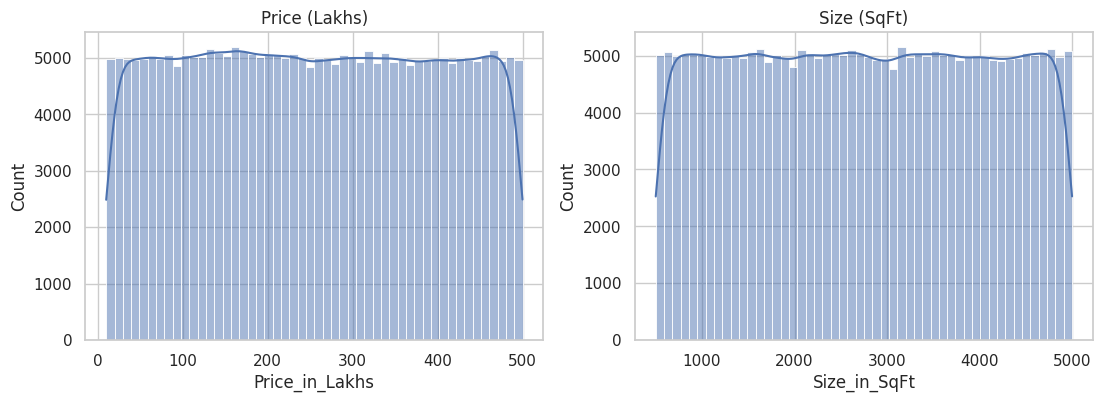

In [ ]:
# Q1 & Q2: distributions of price and size
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['Price_in_Lakhs'], bins=50, kde=True, ax=ax[0]); ax[0].set_title('Price (Lakhs)')
sns.histplot(df['Size_in_SqFt'], bins=50, kde=True, ax=ax[1]); ax[1].set_title('Size (SqFt)')
plt.show()

### Insights

- Property prices range approximately from ₹10 lakh to ₹500 lakh, covering a wide range of investment budgets.
- Property sizes range approximately from 500 to 5,000 square feet, representing different space requirements.
- Both histograms show relatively uniform distributions, with property counts remaining broadly consistent across most intervals.
- Neither variable shows a strong concentration around a particular price or size range.
- The unusually uniform patterns may indicate that the dataset is synthetically generated; this should be considered when interpreting the analysis.

### Business Impact

- **Market Segmentation:** Real estate businesses can categorize properties into budget, mid-range, and premium segments based on price.
- **Customer Targeting:** Property sizes help identify suitable options for customers with different space requirements.
- **Investment Planning:** Investors can explore properties across different price brackets according to their available budgets.
- **Pricing Strategy:** Understanding price and size distributions provides a foundation for analysing property valuation and price per square foot.
- **Model Development:** The broad coverage of prices and sizes can support machine learning analysis across different property categories, subject to dataset quality.

### Q3: Price per SqFt by Property Type

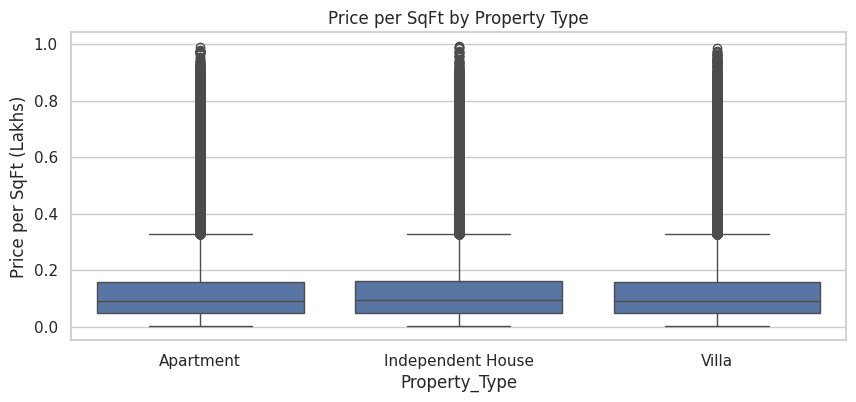

In [ ]:
# Q3: Price per SqFt by Property Type
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='Property_Type', y='Price_per_SqFt_Exact')
plt.title('Price per SqFt by Property Type')
plt.ylabel('Price per SqFt (Lakhs)')
plt.show()

### Insights

- The median price per square foot is nearly identical across Apartments, Independent Houses, and Villas.
- All three property types show a similar interquartile range, indicating comparable price distributions for the middle 50% of properties.
- Numerous upper outliers are visible across all three categories, with some properties reaching approximately 1 lakh per square foot.
- The distributions suggest that property type alone does not create a substantial difference in price per square foot.
- There is considerable variation in property valuation within each property category.

### Business Impact

- **Property Valuation:** Real estate businesses can use price per square foot as a common benchmark to compare different property types.
- **Pricing Strategy:** Similar median values suggest that location, amenities, and property characteristics should also be considered when determining prices.
- **Investment Decisions:** Investors should investigate unusually expensive properties before making investment decisions.
- **Market Segmentation:** Businesses can develop more accurate pricing strategies by combining property type with other relevant factors.
- **Competitive Analysis:** Comparing properties using price per square foot can help buyers and sellers evaluate whether a property is competitively priced.

### Q4: size vs price

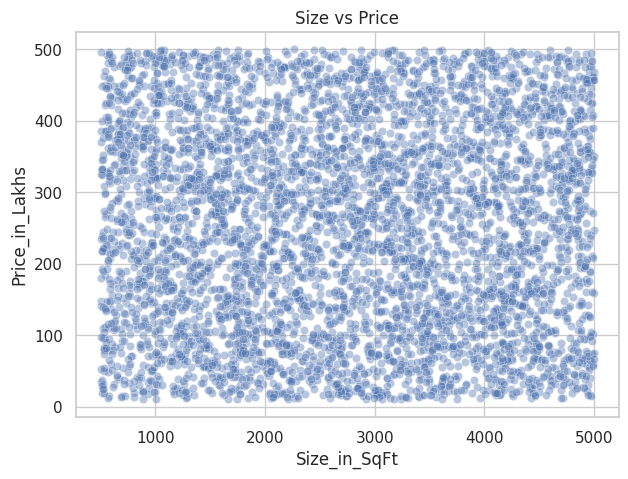

In [ ]:
# Q4: size vs price
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df.sample(min(5000, len(df)), random_state=1), x='Size_in_SqFt', y='Price_in_Lakhs', alpha=0.4)
plt.title('Size vs Price'); plt.show()

### Insights

- Property sizes range approximately from 500 to 5,000 square feet, while property prices range from around ₹10 lakh to ₹500 lakh.
- The scatter plot does not show a clear positive or negative linear relationship between property size and price.
- Properties with similar sizes have considerably different prices.
- Larger properties are not consistently more expensive than smaller properties.
- This indicates that property size alone may not sufficiently explain variations in property prices.
- Other factors, such as location, property type, amenities, and neighbourhood infrastructure, may influence property valuation.

### Business Impact

- **Property Pricing:** Real estate businesses should consider multiple property characteristics rather than relying only on size when determining prices.
- **Customer Recommendations:** Buyers can compare properties of similar sizes based on location, amenities, and budget.
- **Investment Decisions:** Investors should evaluate additional factors before selecting properties for investment.
- **Market Analysis:** Businesses can investigate how location and property features influence prices across different size categories.
- **Predictive Modelling:** Machine learning models should incorporate multiple relevant features to improve property price estimation.

### Q5: Outlier Detection

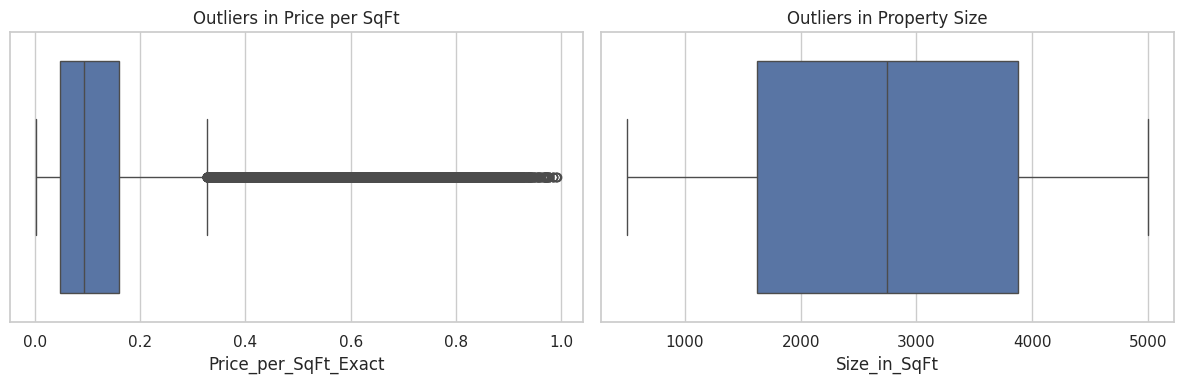

In [ ]:
# Q5: Outlier Detection
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df['Price_per_SqFt_Exact'], ax=ax[0])
ax[0].set_title('Outliers in Price per SqFt')

sns.boxplot(x=df['Size_in_SqFt'], ax=ax[1])
ax[1].set_title('Outliers in Property Size')

plt.tight_layout()
plt.show()

### Insights

- The boxplot of price per square foot shows a large number of upper outliers beyond the upper whisker.
- These outliers indicate properties with considerably higher prices per square foot compared with most properties.
- The distribution is positively skewed, with extreme values extending towards approximately 1 lakh per square foot.
- The property-size boxplot does not show prominent outliers based on the IQR method.
- Property sizes range approximately from 500 to 5,000 square feet, with a median around 2,750 square feet.
- Price per square foot has greater extreme-value variation than property size.

### Business Impact

- **Data Quality Management:** Identifying extreme price values helps businesses investigate potential data-entry errors and unusual property valuations.
- **Investment Risk Assessment:** Investors should carefully evaluate properties with exceptionally high prices per square foot before making investment decisions.
- **Pricing Strategy:** Real estate businesses can analyse premium-priced properties separately to develop appropriate pricing strategies.
- **Model Performance:** Extreme price-per-square-foot values may influence statistical analysis and machine learning models, so suitable outlier-handling techniques should be evaluated.
- **Market Segmentation:** Businesses can distinguish premium properties from standard-market properties for more effective customer targeting.

### Location-based Analysis (Q6-10)

### Q6. Average price per square foot by state

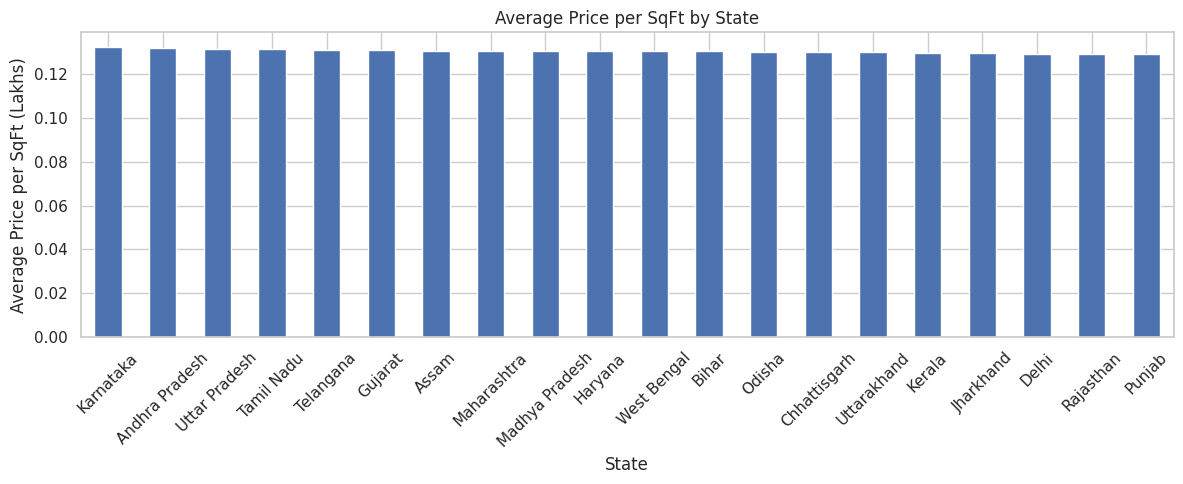

In [ ]:
state_ppsf = (
    df.groupby('State')['Price_per_SqFt_Exact']
    .mean()
    .sort_values(ascending=False)
)

state_ppsf.plot(
    kind='bar',
    figsize=(12, 5),
    title='Average Price per SqFt by State'
)

plt.xlabel('State')
plt.ylabel('Average Price per SqFt (Lakhs)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insights

- The average price per square foot is relatively similar across all 20 states.
- Most states show an average price per square foot between approximately 0.128 and 0.132 lakh.
- Karnataka appears to have the highest average price per square foot, while Punjab is among the lowest.
- The difference between the highest and lowest state averages is relatively small.
- The chart indicates limited variation in average property prices per square foot across states in this dataset.

### Business Impact

- **Market Comparison:** Real estate businesses can compare property valuation patterns across different states.
- **Investment Planning:** Investors can explore multiple states without relying solely on state-level average price differences.
- **Pricing Strategy:** Businesses should consider city and locality-level factors because state-level averages show limited variation.
- **Market Expansion:** Real estate companies can use state-level comparisons as an initial step when evaluating potential markets.

### Q7. Average property price by city

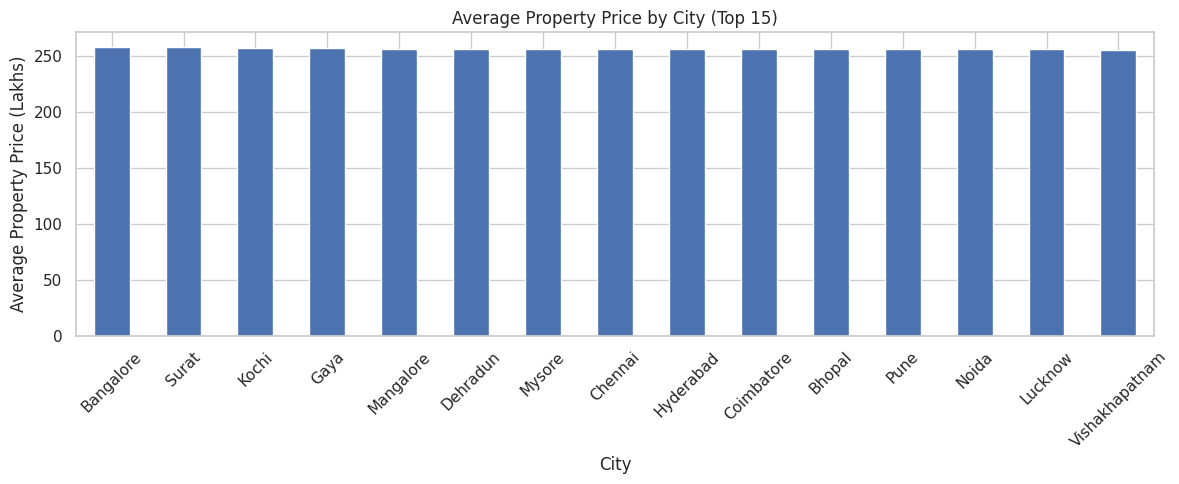

In [ ]:
city_price = (
    df.groupby('City')['Price_in_Lakhs']
    .mean()
    .sort_values(ascending=False)
)

city_price.head(15).plot(
    kind='bar',
    figsize=(12, 5),
    title='Average Property Price by City (Top 15)'
)

plt.xlabel('City')
plt.ylabel('Average Property Price (Lakhs)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insights

- Bangalore has the highest average property price among the 15 cities shown, at approximately ₹257 lakh.
- Surat, Kochi, and Gaya also show relatively high average property prices.
- The average property prices across the top 15 cities are relatively close, ranging approximately from ₹254 lakh to ₹257 lakh.
- The small differences indicate that the selected cities have broadly similar average property price levels.
- City-level average prices provide a useful overview, but they do not reflect variations between individual localities or property types.

### Business Impact

- **Market Selection:** Real estate businesses can compare cities to identify potential markets for investment and expansion.
- **Investment Planning:** Buyers and investors can use average city prices to make initial budget comparisons.
- **Pricing Strategy:** Businesses should combine city-level averages with locality-level analysis before setting property prices.
- **Customer Targeting:** Real estate companies can recommend suitable cities based on customers' investment budgets.
- **Business Expansion:** Cities with competitive average prices can be considered for further market research.

### Q8. Median property age by locality

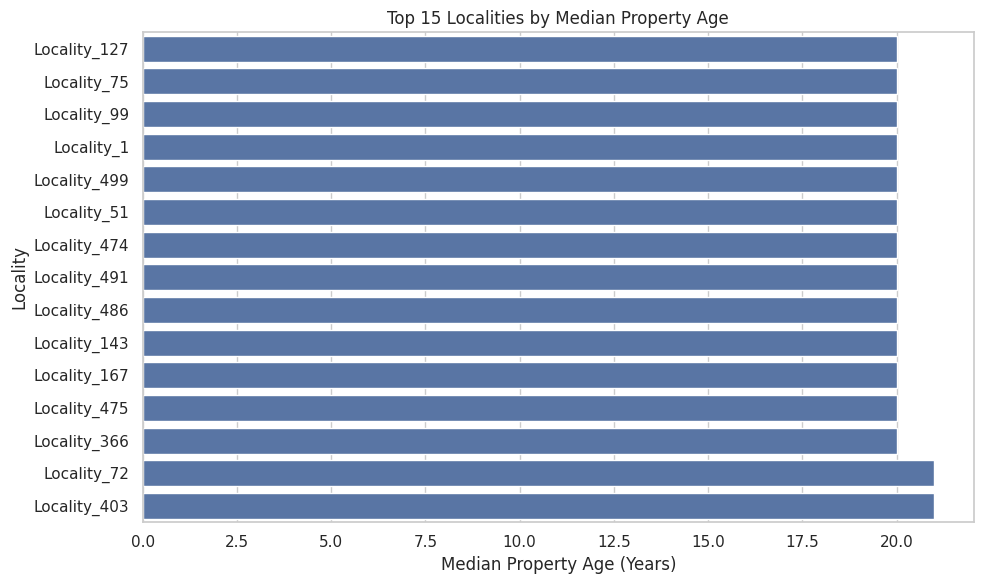

In [ ]:


locality_age = (
    df.groupby('Locality')['Age_of_Property']
    .median()
    .sort_values(ascending=False)
    .head(15)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=locality_age.values,
    y=locality_age.index
)

plt.title('Top 15 Localities by Median Property Age')
plt.xlabel('Median Property Age (Years)')
plt.ylabel('Locality')

plt.tight_layout()
plt.show()

### Insights

- The top 15 localities have median property ages ranging from 20 to 21 years.
- Locality_72 and Locality_403 have the highest median property age of 21 years.
- The remaining 13 localities have a median property age of approximately 20 years.
- The small difference in median age indicates that these localities have relatively similar property-age profiles.
- The results suggest that the selected localities mainly contain properties with comparable construction-age characteristics.

### Business Impact

- **Renovation Planning:** Older properties may require renovation, maintenance, or infrastructure improvements.
- **Investment Evaluation:** Investors can consider property age when estimating potential maintenance and renovation expenses.
- **Property Marketing:** Real estate businesses can identify opportunities to promote renovated or relatively newer properties.
- **Maintenance Management:** Property managers can prioritize property inspections and maintenance based on building age.
- **Investment Strategy:** Property age can be combined with location, price, and amenities to evaluate investment opportunities.

### Q9. BHK distribution across cities

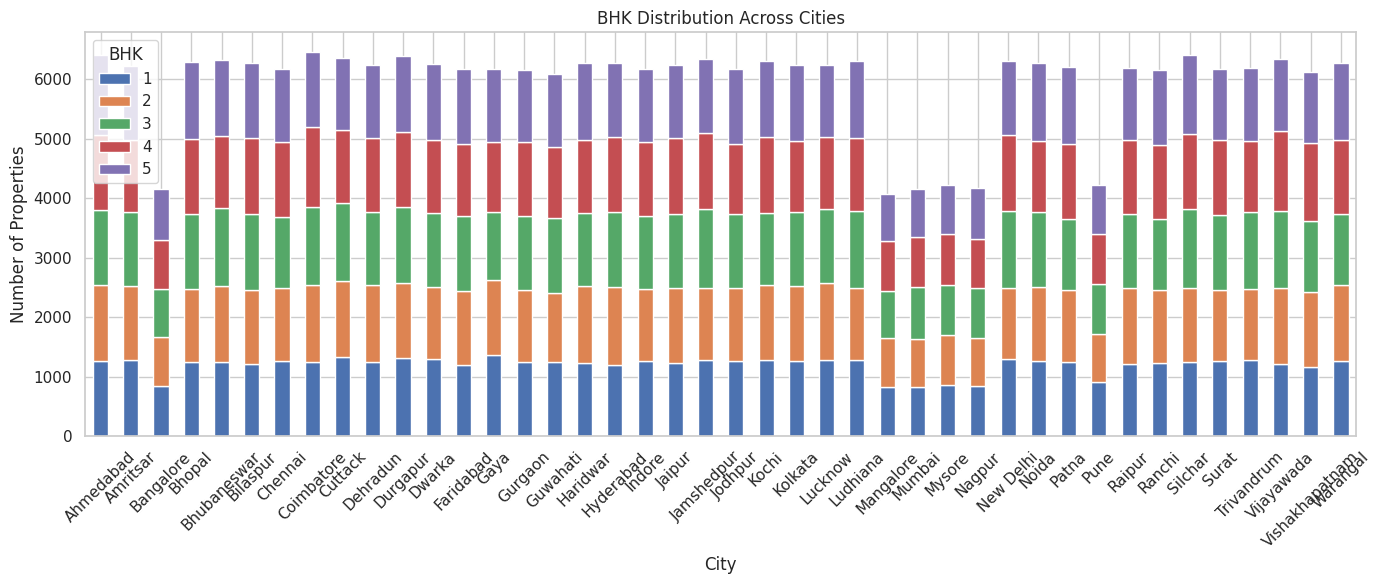

In [ ]:
bhk_city = pd.crosstab(df['City'], df['BHK'])

bhk_city.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 6),
    title='BHK Distribution Across Cities'
)

plt.xlabel('City')
plt.ylabel('Number of Properties')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insights

- The chart shows the distribution of 1 BHK, 2 BHK, 3 BHK, 4 BHK, and 5 BHK properties across different cities.
- Most cities have a relatively balanced distribution across the five BHK categories.
- The 2 BHK, 3 BHK, and 4 BHK categories contribute a substantial share of the properties in most cities.
- Total property counts vary across cities. Ahmedabad, Amritsar, and several other cities have higher counts, while Bangalore, Ludhiana, Mumbai, and Mysore show comparatively lower counts.
- All five BHK categories are represented across the cities, although their individual counts differ.

### Business Impact

- **Customer Segmentation:** Real estate businesses can target customers based on their preferred number of bedrooms.
- **Demand Analysis:** BHK distribution helps businesses understand the availability of different property configurations across cities.
- **Property Development:** Developers can use this information when planning residential projects with different apartment sizes.
- **Marketing Strategy:** Businesses can create targeted marketing campaigns for customers looking for specific BHK configurations.
- **Inventory Management:** Real estate companies can evaluate property availability across different BHK categories and cities.

### Q10. Price per square foot trend for the top five localities

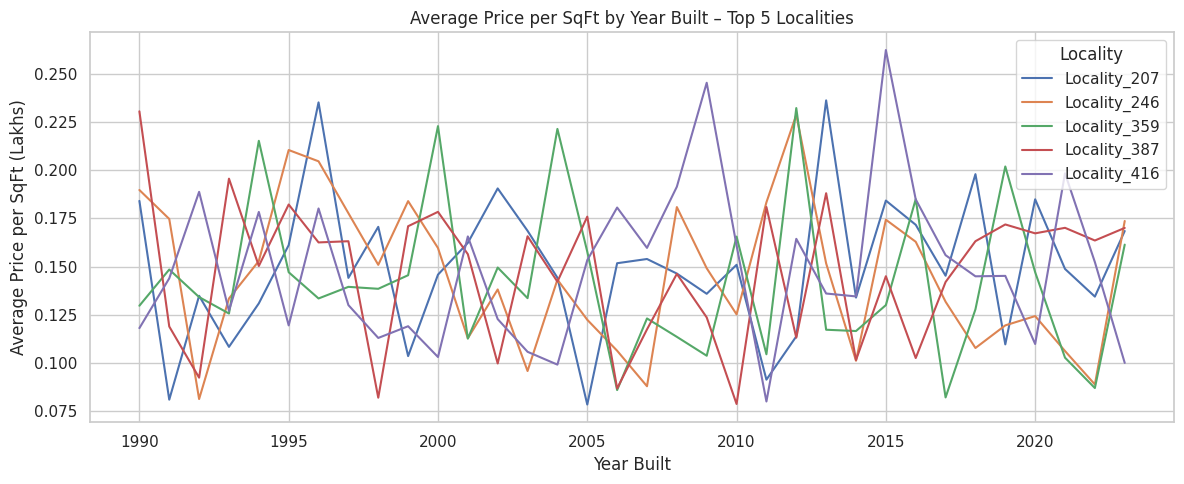

In [ ]:
top5 = (
    df.groupby('Locality')['Price_per_SqFt_Exact']
    .mean()
    .nlargest(5)
    .index
)

trend = (
    df[df['Locality'].isin(top5)]
    .groupby(['Year_Built', 'Locality'])['Price_per_SqFt_Exact']
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=trend,
    x='Year_Built',
    y='Price_per_SqFt_Exact',
    hue='Locality'
)

plt.title('Average Price per SqFt by Year Built – Top 5 Localities')
plt.xlabel('Year Built')
plt.ylabel('Average Price per SqFt (Lakhs)')
plt.tight_layout()
plt.show()

### Insights

- The chart compares the average price per square foot across the five highest-priced localities, based on their overall average price per square foot.
- Locality_416 reaches the highest observed value, approximately 0.26 lakh per square foot, around the year 2015.
- The price per square foot fluctuates considerably across different construction years in all five localities.
- No consistent upward or downward pattern is visible across the five localities.
- The variation indicates differences in property valuation among properties built in different years.
- These values represent average prices grouped by construction year, not historical market-price changes over time.

### Business Impact

- **Locality Comparison:** Investors can compare property valuations across high-priced localities before selecting an investment location.
- **Property Valuation:** Businesses can examine construction-year differences when evaluating property prices.
- **Investment Research:** Significant fluctuations can help identify localities and property groups that require further investigation.
- **Pricing Strategy:** Real estate companies can use construction year and locality together when developing property pricing strategies.
- **Risk Assessment:** Investors should avoid assuming that a high average price per square foot guarantees future appreciation.

##  Feature Relationships & Correlation (Q11-15)

### Q11. Correlation heatmap

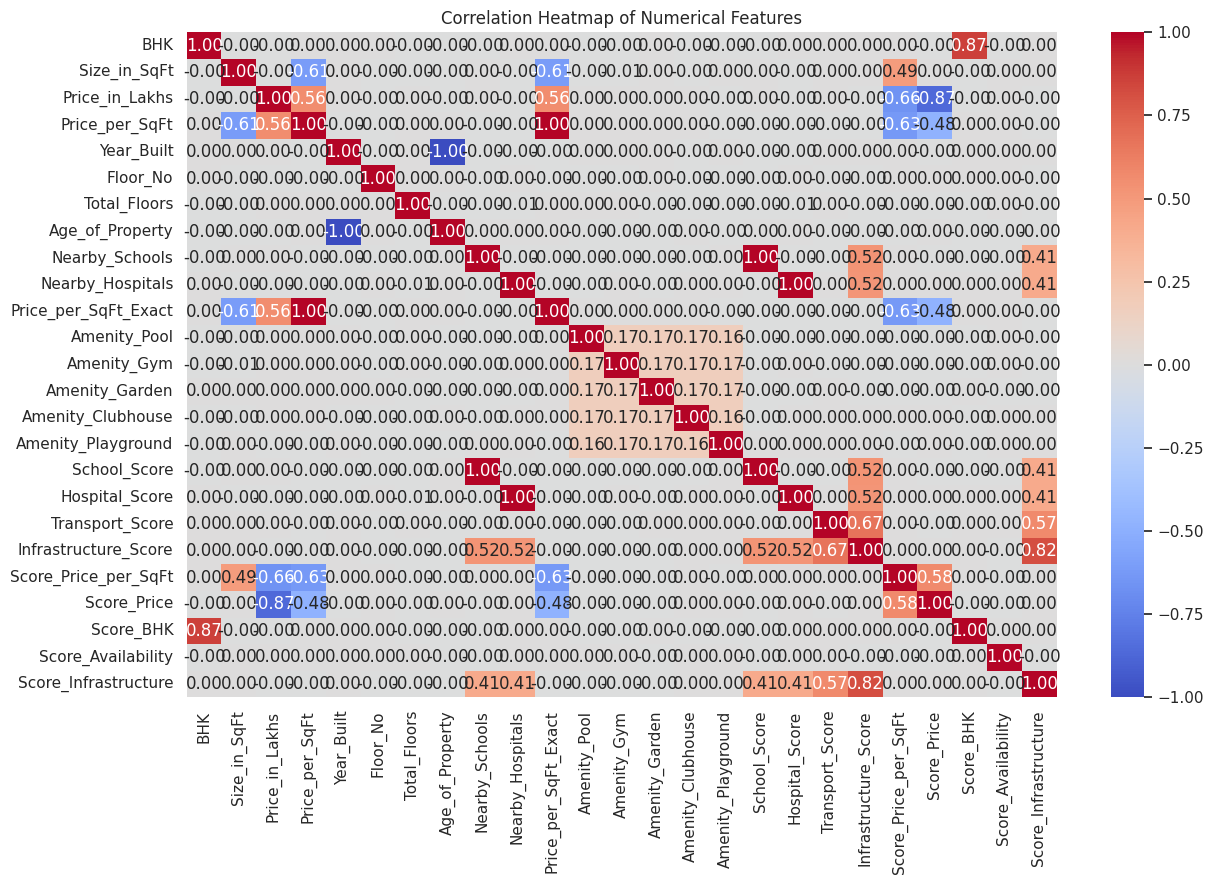

In [ ]:


numeric_df = df.select_dtypes(include=np.number).drop(
    columns=[
        'ID',
        'Good_Investment',
        'Investment_Score',
        'Future_Price_5Y'
    ],
    errors='ignore'
)

plt.figure(figsize=(13, 9))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

### Insights

- `Price_in_Lakhs` shows a moderate positive correlation (approximately 0.56) with `Price_per_SqFt_Exact`.
- `Size_in_SqFt` shows a negative correlation with price per square foot, indicating that larger properties tend to have lower price-per-square-foot values in this dataset.
- `Year_Built` and `Age_of_Property` have a perfect negative correlation (-1.00), because property age is derived directly from the construction year.
- `Nearby_Schools` and `School_Score`, as well as `Nearby_Hospitals` and `Hospital_Score`, show perfect positive correlations because the scores are derived from the original counts.
- `Infrastructure_Score` has a strong positive correlation with `Score_Infrastructure` (approximately 0.82).
- Most other numerical feature pairs show weak or negligible linear correlations.
- Some strong correlations are expected because several features are mathematically derived from other columns.

### Business Impact

- **Property Valuation:** Businesses can examine relationships between property price, size, and price per square foot to understand valuation patterns.
- **Feature Selection:** Correlation analysis helps identify redundant features that may not need to be included together in machine learning models.
- **Model Reliability:** Removing duplicate or highly correlated derived features can simplify model development and interpretation.
- **Investment Analysis:** Businesses can investigate how infrastructure-related variables are associated with property valuation.
- **Decision Making:** Correlation analysis provides an initial understanding of relationships between property characteristics, but correlation alone does not establish causation.

### Q12. Nearby schools vs price per square foot

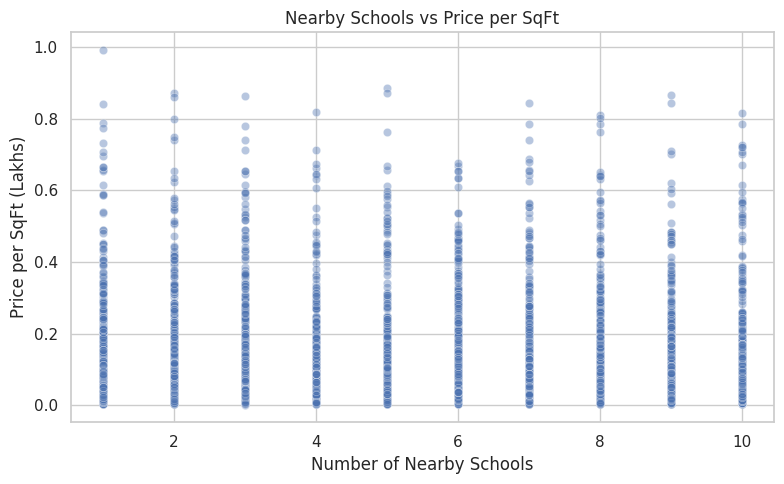

In [ ]:
# Q12: Nearby Schools vs Price per SqFt

sample_df = df.sample(min(5000, len(df)), random_state=1)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=sample_df,
    x='Nearby_Schools',
    y='Price_per_SqFt_Exact',
    alpha=0.4
)

plt.title('Nearby Schools vs Price per SqFt')
plt.xlabel('Number of Nearby Schools')
plt.ylabel('Price per SqFt (Lakhs)')

plt.tight_layout()
plt.show()

### Insights

- The scatter plot shows property prices per square foot across locations with 1 to 10 nearby schools.
- Properties with different numbers of nearby schools show a wide variation in price per square foot.
- No clear positive or negative linear relationship is visible between the number of nearby schools and property price per square foot.
- Higher-priced properties appear across different school-count categories.
- The number of nearby schools alone does not appear to explain property price differences in this dataset.

### Business Impact

- **Property Evaluation:** Buyers can consider nearby schools as one factor when comparing residential properties.
- **Customer Targeting:** Real estate businesses can highlight school accessibility when marketing properties to families.
- **Investment Analysis:** Investors should evaluate school availability alongside location, transport, hospitals, and other property characteristics.
- **Property Development:** Developers can consider educational infrastructure when selecting locations for residential projects.
- **Pricing Strategy:** Businesses should not use the number of nearby schools alone to determine property prices.

### Q13. Nearby hospitals vs price per square foot

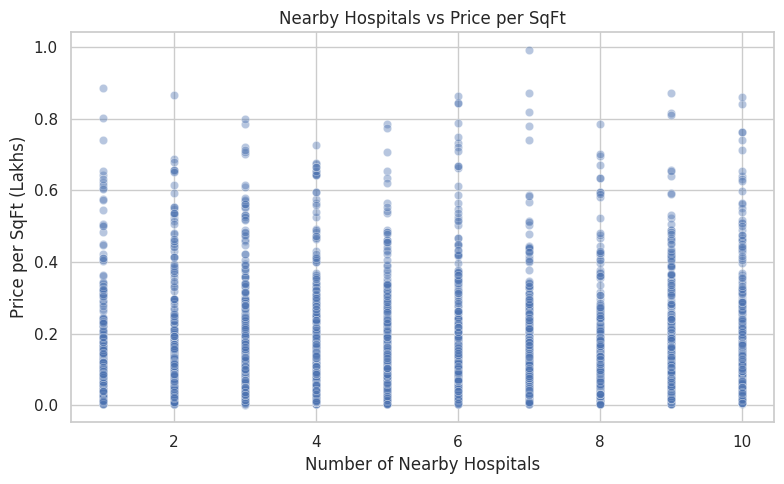

In [ ]:


plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=sample_df,
    x='Nearby_Hospitals',
    y='Price_per_SqFt_Exact',
    alpha=0.4
)

plt.title('Nearby Hospitals vs Price per SqFt')
plt.xlabel('Number of Nearby Hospitals')
plt.ylabel('Price per SqFt (Lakhs)')

plt.tight_layout()
plt.show()

### Insights

- The scatter plot shows property prices per square foot across locations with 1 to 10 nearby hospitals.
- Property prices vary considerably within every hospital-count category.
- No clear positive or negative linear relationship is visible between the number of nearby hospitals and property price per square foot.
- Higher-priced properties are present across different levels of hospital availability.
- The number of nearby hospitals alone does not appear to explain property price differences in this dataset.

### Business Impact

- **Property Evaluation:** Buyers can consider nearby hospitals as an important accessibility factor when comparing residential properties.
- **Customer Targeting:** Real estate businesses can highlight healthcare accessibility when marketing properties to families and other buyers.
- **Investment Analysis:** Investors should evaluate hospital availability alongside location, schools, transport, and other property characteristics.
- **Property Development:** Developers can consider access to healthcare facilities when planning residential projects.
- **Pricing Strategy:** Businesses should not rely solely on the number of nearby hospitals when determining property prices.

### Q14. Property price by furnished status

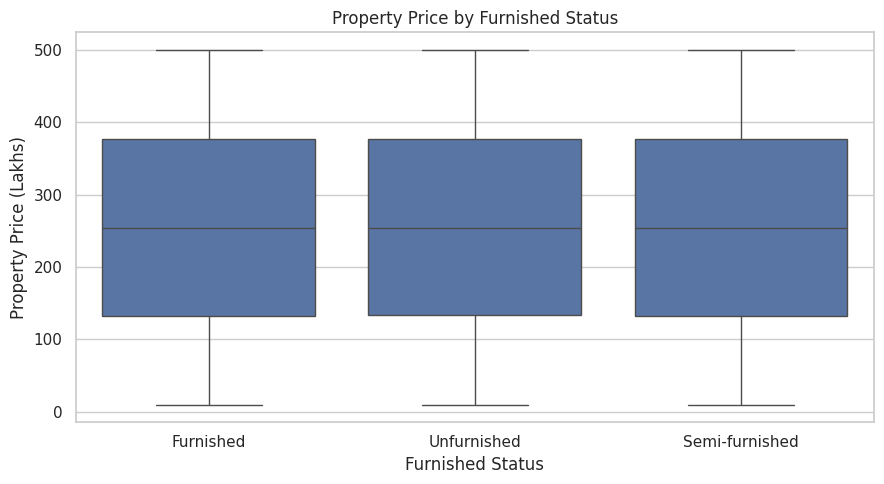

In [ ]:
# Q14: Property Price by Furnished Status

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Furnished_Status',
    y='Price_in_Lakhs'
)

plt.title('Property Price by Furnished Status')
plt.xlabel('Furnished Status')
plt.ylabel('Property Price (Lakhs)')

plt.tight_layout()
plt.show()

### Insights

- The boxplot compares property prices across Furnished, Unfurnished, and Semi-furnished categories.
- All three categories show nearly identical median property prices.
- The interquartile ranges are also very similar across the three furnished-status categories.
- Property prices vary widely within each category, ranging approximately from ₹10 lakh to ₹500 lakh.
- Furnished status alone does not show a substantial difference in property prices in this dataset.

### Business Impact

- **Property Marketing:** Real estate businesses can highlight furnishing options to attract customers with different preferences.
- **Customer Segmentation:** Buyers can compare furnished, unfurnished, and semi-furnished properties according to their requirements.
- **Pricing Strategy:** Businesses should consider location, size, property type, and amenities alongside furnishing status when setting prices.
- **Investment Planning:** Investors should not assume that furnished properties automatically have higher market value.
- **Property Management:** Developers and property owners can evaluate furnishing costs against potential customer demand before investing in upgrades.

### Q15. Price per square foot by facing

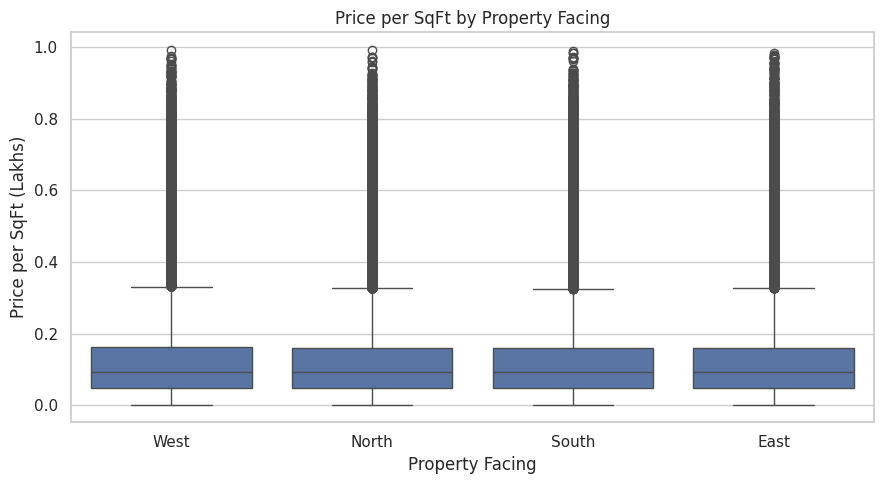

In [ ]:


plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Facing',
    y='Price_per_SqFt_Exact'
)

plt.title('Price per SqFt by Property Facing')
plt.xlabel('Property Facing')
plt.ylabel('Price per SqFt (Lakhs)')

plt.tight_layout()
plt.show()

### Insights

- The boxplot compares price per square foot across West, North, South, and East-facing properties.
- All four facing categories show nearly identical median price per square foot.
- The interquartile ranges are also very similar across the four categories.
- Numerous upper outliers are present in every facing category, indicating properties with considerably higher prices per square foot.
- No substantial difference in price per square foot is visible based on property facing alone.

### Business Impact

- **Property Valuation:** Real estate businesses can compare property prices across different facing directions.
- **Customer Preferences:** Buyers can explore properties according to their preferred facing direction.
- **Pricing Strategy:** Businesses should consider location, amenities, and property characteristics rather than relying only on facing direction.
- **Property Marketing:** Developers can highlight facing direction as an additional property feature when targeting customers.
- **Investment Decisions:** Investors should evaluate facing direction alongside other important factors before selecting a property.


## Investment / Amenities / Ownership (Q16-20)

### Q16 & Q17. Owner type and availability counts

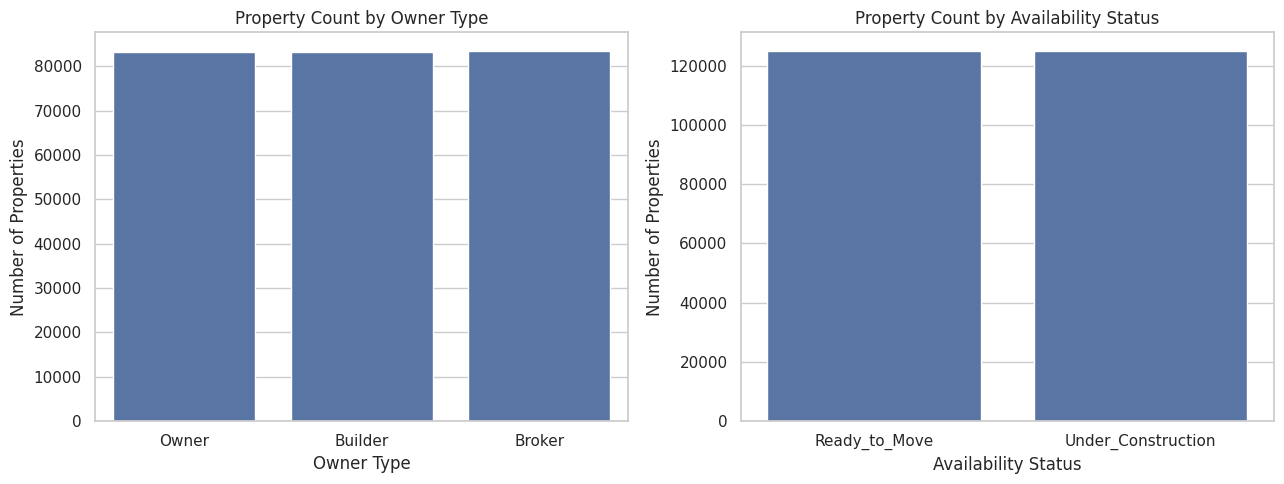

In [ ]:


fig, ax = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, x='Owner_Type', ax=ax[0])
ax[0].set_title('Property Count by Owner Type')
ax[0].set_xlabel('Owner Type')
ax[0].set_ylabel('Number of Properties')

sns.countplot(data=df, x='Availability_Status', ax=ax[1])
ax[1].set_title('Property Count by Availability Status')
ax[1].set_xlabel('Availability Status')
ax[1].set_ylabel('Number of Properties')

plt.tight_layout()
plt.show()

### Insights

- The first chart shows three ownership categories: Owner, Builder, and Broker.
- All three ownership categories have nearly equal property counts, with approximately 83,000 properties each.
- The second chart shows two availability categories: Ready_to_Move and Under_Construction.
- Both availability categories have almost equal representation, with approximately 125,000 properties each.
- The dataset shows a balanced distribution across ownership types and property availability statuses.
- No major imbalance is observed in either category.

### Business Impact

- **Market Segmentation:** Real estate businesses can analyse properties based on ownership type and availability status.
- **Customer Targeting:** Buyers can be targeted according to their preference for ready-to-move or under-construction properties.
- **Sales Strategy:** Builders and brokers can develop different marketing strategies based on property ownership and availability.
- **Inventory Management:** Businesses can monitor ready-to-move and under-construction property inventory.
- **Business Planning:** The balanced distribution provides opportunities to serve customers interested in both immediate possession and future residential projects.

### Q18. Parking space vs property price

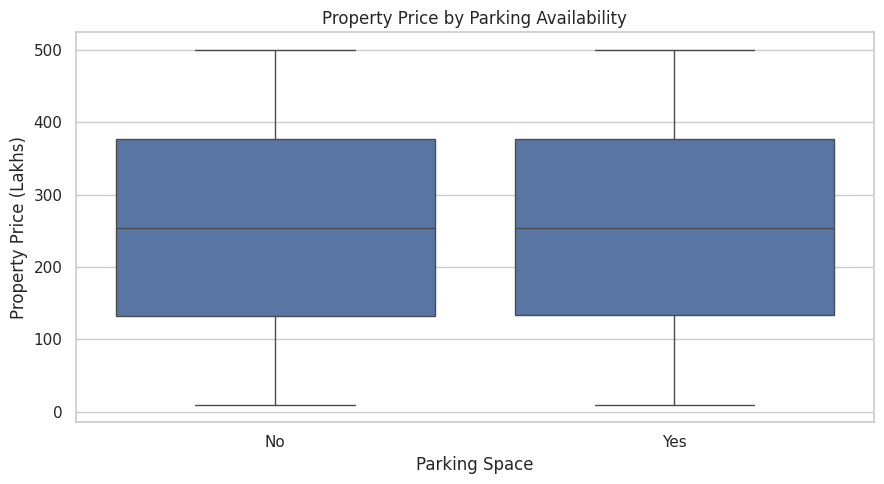

In [ ]:
# Q18: Parking Space vs Property Price

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Parking_Space',
    y='Price_in_Lakhs'
)

plt.title('Property Price by Parking Availability')
plt.xlabel('Parking Space')
plt.ylabel('Property Price (Lakhs)')

plt.tight_layout()
plt.show()

### Insights

- The boxplot compares property prices between properties with and without parking facilities.
- Both categories show nearly identical median property prices.
- The interquartile ranges are also very similar.
- Property prices vary widely in both categories, ranging approximately from ₹10 lakh to ₹500 lakh.
- Parking availability alone does not show a substantial difference in property prices in this dataset.

### Business Impact

- **Customer Preferences:** Real estate businesses can highlight parking availability when targeting customers who own vehicles.
- **Property Marketing:** Properties with parking facilities can be promoted as an additional convenience.
- **Pricing Strategy:** Businesses should consider location, size, and other property features rather than assuming parking automatically increases property value.
- **Property Development:** Developers can evaluate parking requirements when planning residential projects.
- **Investment Evaluation:** Investors should assess parking availability alongside other important property characteristics.

### Q19. Amenities vs price per square foot

In [ ]:
# Create total amenity count

amenity_columns = [
    'Amenity_Pool',
    'Amenity_Gym',
    'Amenity_Garden',
    'Amenity_Clubhouse',
    'Amenity_Playground'
]

df['Amenity_Count'] = df[amenity_columns].sum(axis=1)

display(df['Amenity_Count'].value_counts().sort_index())

,count
Amenity_Count,
1,50106
2,49806
3,49862
4,50362
5,49864


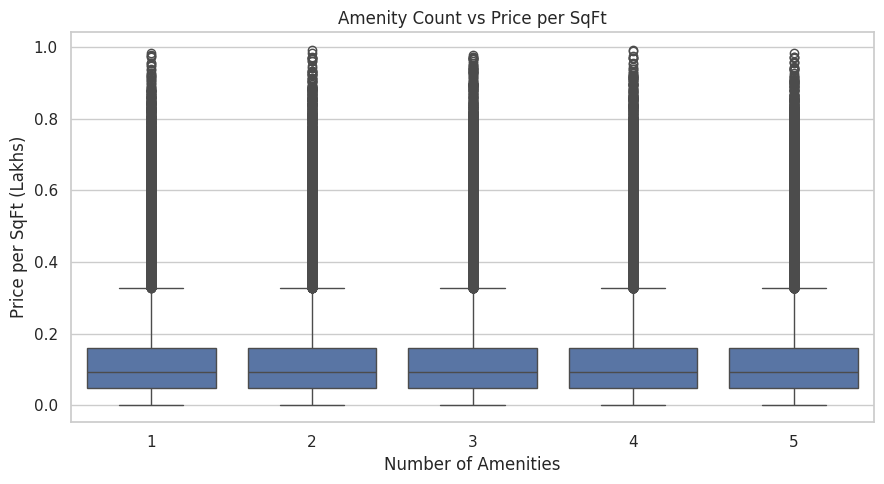

In [ ]:
# Q19: Amenity Count vs Price per SqFt

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Amenity_Count',
    y='Price_per_SqFt_Exact'
)

plt.title('Amenity Count vs Price per SqFt')
plt.xlabel('Number of Amenities')
plt.ylabel('Price per SqFt (Lakhs)')

plt.tight_layout()
plt.show()

### Insights

- The boxplot compares price per square foot across properties having 1 to 5 amenities.
- All five categories show nearly identical median price per square foot.
- The interquartile ranges are also very similar across amenity-count categories.
- Numerous upper outliers are visible in every category, indicating properties with considerably higher prices per square foot.
- Increasing the number of amenities does not show a clear increase in price per square foot in this dataset.
- The total number of amenities alone does not appear to explain significant differences in property valuation.

### Business Impact

- **Property Development:** Developers can evaluate which amenities are most relevant to potential buyers.
- **Customer Targeting:** Real estate businesses can promote available amenities according to customer preferences.
- **Investment Planning:** Investors should consider the quality and type of amenities rather than focusing only on their total count.
- **Pricing Strategy:** Businesses should evaluate amenities alongside location, property type, and other characteristics when determining prices.
- **Resource Allocation:** Developers can assess the potential value of adding amenities before investing in additional facilities.

### Q20. Public transport accessibility vs price and investment potential

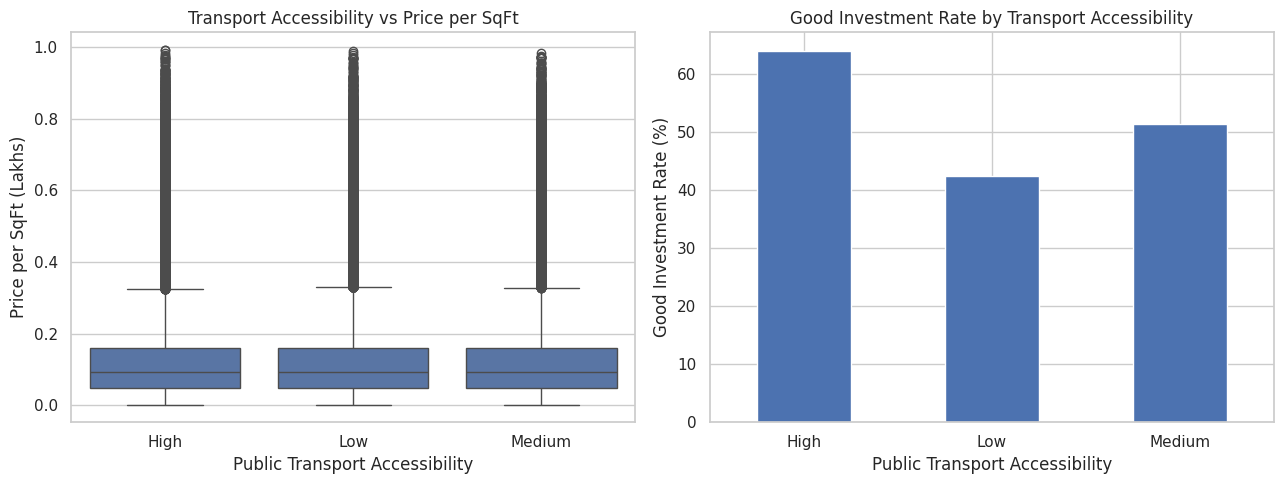

In [ ]:
# Q20: Public Transport Accessibility Analysis

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Transport accessibility vs price per sqft
sns.boxplot(
    data=df,
    x='Public_Transport_Accessibility',
    y='Price_per_SqFt_Exact',
    ax=ax[0]
)

ax[0].set_title('Transport Accessibility vs Price per SqFt')
ax[0].set_xlabel('Public Transport Accessibility')
ax[0].set_ylabel('Price per SqFt (Lakhs)')

# Good investment percentage by transport accessibility
investment_rate = (
    df.groupby('Public_Transport_Accessibility')['Good_Investment']
    .mean() * 100
)

investment_rate.plot(
    kind='bar',
    ax=ax[1]
)

ax[1].set_title('Good Investment Rate by Transport Accessibility')
ax[1].set_xlabel('Public Transport Accessibility')
ax[1].set_ylabel('Good Investment Rate (%)')
ax[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Insights

- The first chart compares price per square foot across High, Medium, and Low public transport accessibility categories.
- All three categories show nearly identical median prices per square foot.
- The price distributions and interquartile ranges are also very similar.
- The second chart shows differences in the Good Investment rate across transport accessibility categories.
- High accessibility has the highest Good Investment rate at approximately 64%.
- Medium accessibility shows approximately 51%, while Low accessibility has approximately 42%.
- The results indicate that the rule-based investment classification is associated with transport accessibility.

### Business Impact

- **Location Selection:** Investors can consider public transport accessibility when evaluating residential locations.
- **Customer Targeting:** Real estate businesses can highlight transport connectivity when marketing properties.
- **Property Development:** Developers can consider access to public transportation when selecting locations for residential projects.
- **Investment Analysis:** Transport accessibility can be included as one factor in a broader property evaluation framework.
- **Business Planning:** Real estate companies can use accessibility information to compare locations and identify potential customer segments.

**Important:** The Good Investment target was partly created using Infrastructure_Score, which itself includes Transport_Score. Therefore, the higher investment rate for High accessibility is partly built into the target definition. It should not be interpreted as independent proof that better transport causes higher investment profitability.

## Extra EDA 1: Infrastructure Score vs Property Price

**Objective:** Analyse the relationship between neighbourhood infrastructure quality and property price per square foot.

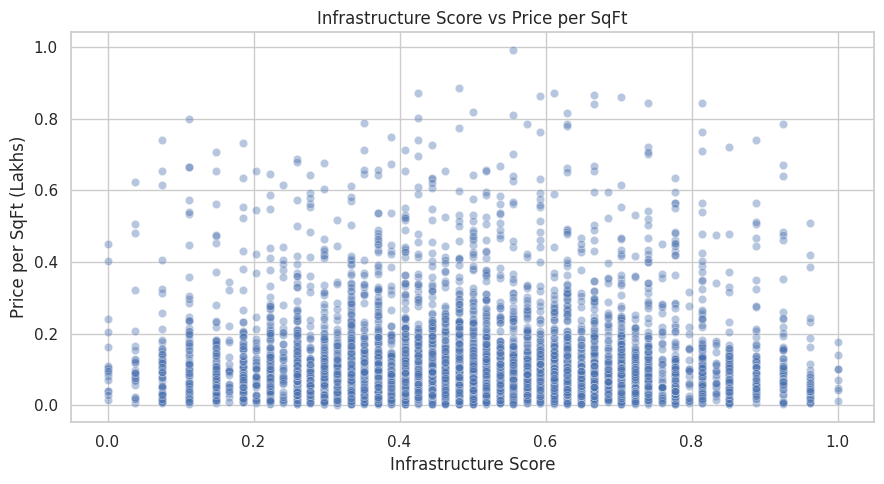

In [ ]:
# Infrastructure Score vs Price per SqFt

sample_df = df.sample(min(5000, len(df)), random_state=1)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=sample_df,
    x='Infrastructure_Score',
    y='Price_per_SqFt_Exact',
    alpha=0.4
)

plt.title('Infrastructure Score vs Price per SqFt')
plt.xlabel('Infrastructure Score')
plt.ylabel('Price per SqFt (Lakhs)')

plt.tight_layout()
plt.show()

### Insights

- The scatter plot shows the relationship between Infrastructure_Score and property price per square foot.
- Infrastructure scores range from 0 to 1, while property prices per square foot show considerable variation.
- Most properties are concentrated in the lower price-per-square-foot range across different infrastructure scores.
- No clear positive or negative linear relationship is visible between infrastructure score and property price per square foot.
- Properties with high infrastructure scores do not consistently have higher prices per square foot.
- Infrastructure score alone does not appear to explain property valuation differences in this dataset.

### Business Impact

- **Location Evaluation:** Investors can consider infrastructure quality when comparing residential locations.
- **Property Valuation:** Businesses should evaluate infrastructure alongside location, size, amenities, and property type.
- **Investment Planning:** Investors should not assume that better infrastructure automatically guarantees higher property prices.
- **Property Development:** Developers can use infrastructure information when assessing potential residential project locations.
- **Predictive Modelling:** Infrastructure score can be evaluated as one of several features for property valuation and investment classification.

## Extra EDA 2: Average Price per SqFt by City and Property Type

**Objective:** Compare property price variations across different cities and property types using a heatmap.

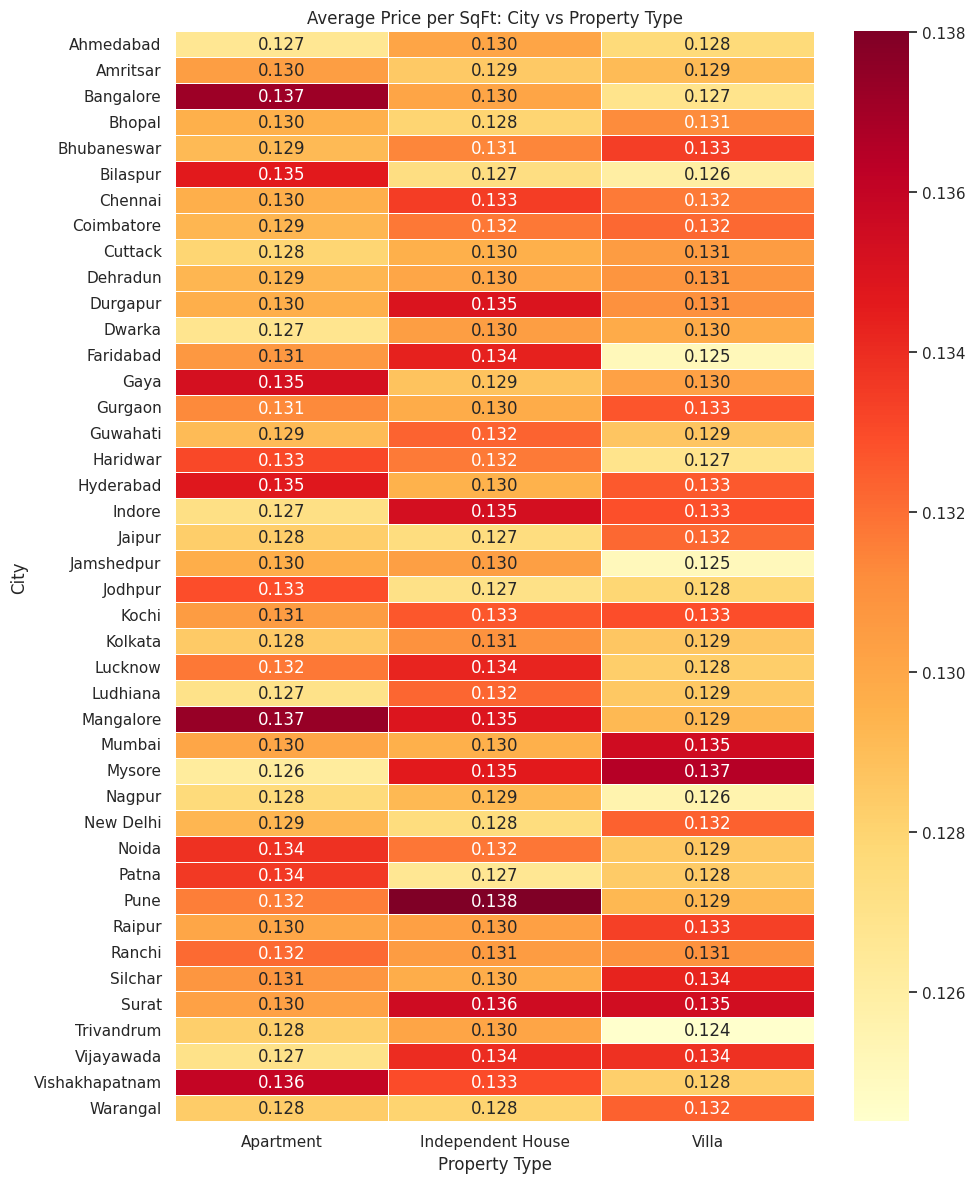

In [ ]:
# City-wise Property Price Heatmap

heat = df.pivot_table(
    index='City',
    columns='Property_Type',
    values='Price_per_SqFt_Exact',
    aggfunc='mean'
)

plt.figure(figsize=(10, 12))

sns.heatmap(
    heat,
    annot=True,
    fmt='.3f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Average Price per SqFt: City vs Property Type')
plt.xlabel('Property Type')
plt.ylabel('City')

plt.tight_layout()
plt.show()

### Insights

- The heatmap compares average price per square foot across 42 cities and three property types.
- Average prices per square foot vary approximately between 0.124 and 0.138 lakh across the city and property-type combinations.
- Bangalore and Mangalore show relatively high apartment prices per square foot, approximately 0.137 lakh.
- Pune has the highest displayed average for Independent Houses, approximately 0.138 lakh.
- Mysore has a relatively high average price for Villas, approximately 0.137 lakh.
- Trivandrum shows the lowest displayed average for Villas, approximately 0.124 lakh.
- Price differences can be observed across both cities and property types, although the overall variation is relatively small.

### Business Impact

- **Market Comparison:** Real estate businesses can compare property valuations across cities and property categories.
- **Investment Selection:** Investors can identify city and property-type combinations for further market research.
- **Pricing Strategy:** Businesses can use city-wise and property-type averages as initial pricing benchmarks.
- **Market Expansion:** Developers can compare different cities before selecting locations for residential projects.
- **Customer Recommendations:** Real estate companies can recommend suitable property types and cities based on customer budgets and preferences.
- **Competitive Analysis:** Businesses can evaluate how property valuations differ across regional markets.

## Extra EDA 3: Crime Rate vs Investment Classification

**Observation:**

The available dataset does not contain a crime-rate column or any direct crime-related indicator. Therefore, the relationship between neighbourhood crime rates and property investment classification cannot be analysed using the current dataset.

**Limitation:**

Crime rate is an important factor in real estate investment decisions, but additional verified crime statistics would be required to perform this analysis.

## MLflow Tracking Configuration

MLflow is configured to track machine learning experiments for the Real Estate Investment Advisor project.

**Experiment Name:** Real_Estate_Investment_Advisor

**Tracking Backend:** Local file-based storage in Google Drive

In [ ]:
# MLflow Setup using SQLite Database

import mlflow
import os

# Define database location in Google Drive
MLFLOW_DB = os.path.join(BASE_DIR, "mlflow.db")

# Configure SQLite tracking backend
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

# Create or select project experiment
mlflow.set_experiment("Real_Estate_Investment_Advisor")

print("MLflow Version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", mlflow.get_experiment_by_name(
    "Real_Estate_Investment_Advisor"
).name)

print("MLflow SQLite setup completed successfully!")

2026/10/31 06:43:02 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/31 06:43:02 INFO mlflow.store.db.utils: Updating database tables
2026/10/31 06:43:08 INFO mlflow.tracking.fluent: Experiment with name 'Real_Estate_Investment_Advisor' does not exist. Creating a new experiment.


MLflow Version: 3.17.2
Tracking URI: sqlite:////content/drive/MyDrive/RealEstateInvestmentAdvisor/mlflow.db
Experiment: Real_Estate_Investment_Advisor
MLflow SQLite setup completed successfully!


In [ ]:
# Verify MLflow Experiment

experiment = mlflow.get_experiment_by_name(
    "Real_Estate_Investment_Advisor"
)

print("Experiment ID:", experiment.experiment_id)
print("Experiment Name:", experiment.name)
print("Artifact Location:", experiment.artifact_location)
print("Experiment Status:", experiment.lifecycle_stage)

Experiment ID: 1
Experiment Name: Real_Estate_Investment_Advisor
Artifact Location: /content/mlruns/1
Experiment Status: active


In [ ]:
import os
from pathlib import Path
import mlflow

# Persistent artifact directory in Google Drive
ARTIFACT_DIR = os.path.join(BASE_DIR, "mlflow_artifacts")
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Use a new experiment name because the original experiment already exists
PERSISTENT_EXPERIMENT = "Real_Estate_Investment_Advisor_Persistent"

# Check whether the experiment already exists
experiment = mlflow.get_experiment_by_name(PERSISTENT_EXPERIMENT)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        name=PERSISTENT_EXPERIMENT,
        artifact_location=Path(ARTIFACT_DIR).as_uri()
    )
else:
    experiment_id = experiment.experiment_id

# Activate the persistent experiment
mlflow.set_experiment(experiment_id=experiment_id)

# Verify configuration
experiment = mlflow.get_experiment(experiment_id)

print("MLflow Tracking URI:", mlflow.get_tracking_uri())
print("Experiment ID:", experiment.experiment_id)
print("Experiment Name:", experiment.name)
print("Artifact Location:", experiment.artifact_location)
print("Artifact Directory Exists:", os.path.exists(ARTIFACT_DIR))

MLflow Tracking URI: sqlite:////content/drive/MyDrive/RealEstateInvestmentAdvisor/mlflow.db
Experiment ID: 2
Experiment Name: Real_Estate_Investment_Advisor_Persistent
Artifact Location: file:///content/drive/MyDrive/RealEstateInvestmentAdvisor/mlflow_artifacts
Artifact Directory Exists: True


In [ ]:
import os
import tempfile
import mlflow

# Create a temporary test file
with tempfile.NamedTemporaryFile(
    mode="w",
    suffix=".txt",
    delete=False
) as temp_file:
    temp_file.write("MLflow persistent artifact test successful.")
    test_file_path = temp_file.name

# Test parameters, metrics, and artifact logging
with mlflow.start_run(run_name="MLflow_Setup_Verification") as run:

    mlflow.log_param("setup_test", "passed")
    mlflow.log_metric("verification_metric", 1.0)

    mlflow.log_artifact(
        test_file_path,
        artifact_path="setup_verification"
    )

    print("Run ID:", run.info.run_id)
    print("Artifact URI:", run.info.artifact_uri)

# Verify the artifact was logged
artifacts = mlflow.artifacts.list_artifacts(
    run_id=run.info.run_id,
    artifact_path="setup_verification"
)

print("\nLogged artifacts:")
for artifact in artifacts:
    print(artifact.path)

# Clean up temporary local file
os.remove(test_file_path)

Run ID: 4efe3ee7c2634b3d888e655de48ca843
Artifact URI: file:///content/drive/MyDrive/RealEstateInvestmentAdvisor/mlflow_artifacts/4efe3ee7c2634b3d888e655de48ca843/artifacts

Logged artifacts:
setup_verification/tmp9c8znrnk.txt


# Machine Learning Model Development



## Classification Model

**Objective:** Develop machine learning classification models to predict whether a property represents a good investment opportunity based on its available property characteristics.

**Target Variable:** `Good_Investment`

**Models Used:**

1. Logistic Regression (Baseline Model)
2. Decision Tree Classifier
3. Random Forest Classifier
4. XGBoost Classifier

**Evaluation Metrics:**

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

**Data Preparation:**

The dataset was already divided into training and testing sets using an 80:20 split. Numerical features were standardized using `StandardScaler`, while categorical features were encoded using `OneHotEncoder`. The preprocessing transformations were fitted on the training dataset and applied to the testing dataset.

**Model Experimentation and Tracking:**

All four classification models were trained and evaluated using the same preprocessed training and testing datasets to ensure a consistent performance comparison. MLflow was used to track model parameters, evaluation metrics, experiment runs, and trained model artifacts.

## 1.Logistic Regression

In [ ]:
# Import required libraries
import mlflow
import mlflow.sklearn

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Activate the persistent MLflow experiment
mlflow.set_experiment("Real_Estate_Investment_Advisor_Persistent")

# Create Logistic Regression baseline model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train and evaluate the model
with mlflow.start_run(run_name="Logistic_Regression_Baseline"):

    # Model training
    logistic_model.fit(
        X_train_cls_processed,
        y_train_cls
    )

    # Predictions
    y_pred_lr = logistic_model.predict(
        X_test_cls_processed
    )

    # Evaluation metrics
    accuracy = accuracy_score(y_test_cls, y_pred_lr)
    precision = precision_score(y_test_cls, y_pred_lr, zero_division=0)
    recall = recall_score(y_test_cls, y_pred_lr, zero_division=0)
    f1 = f1_score(y_test_cls, y_pred_lr, zero_division=0)

    # Log parameters
    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("random_state", 42)

    # Log evaluation metrics
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    # Log trained model
    mlflow.sklearn.log_model(
        sk_model=logistic_model,
        name="logistic_regression_baseline"
    )

    # Display results
    print("LOGISTIC REGRESSION - BASELINE MODEL")
    print("-------------------------------------")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-Score : {f1:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_cls, y_pred_lr))

    print("\nClassification Report:")
    print(classification_report(y_test_cls, y_pred_lr))

LOGISTIC REGRESSION - BASELINE MODEL
-------------------------------------
Accuracy : 0.5815
Precision: 0.5922
Recall   : 0.6557
F1-Score : 0.6223

Confusion Matrix:
[[11838 11872]
 [ 9051 17239]]

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.50      0.53     23710
           1       0.59      0.66      0.62     26290

    accuracy                           0.58     50000
   macro avg       0.58      0.58      0.58     50000
weighted avg       0.58      0.58      0.58     50000



### Insights

The Logistic Regression baseline model achieved an accuracy of **58.15%**, precision of **59.22%**, recall of **65.57%**, and an F1-score of **62.23%** on the test dataset containing 50,000 records.

The model correctly classified 11,838 properties as not good investments and 17,239 properties as good investments. However, it produced 11,872 false-positive predictions and 9,051 false-negative predictions.

For class 1 (Good Investment), the model achieved a recall of 65.57%, indicating that it identified approximately two-thirds of the actual good-investment properties. In comparison, class 0 (Not Good Investment) had a recall of 49.95%, showing weaker identification of properties belonging to this category.

Overall, the model demonstrates moderate classification performance and provides a baseline for comparison with other machine learning algorithms.

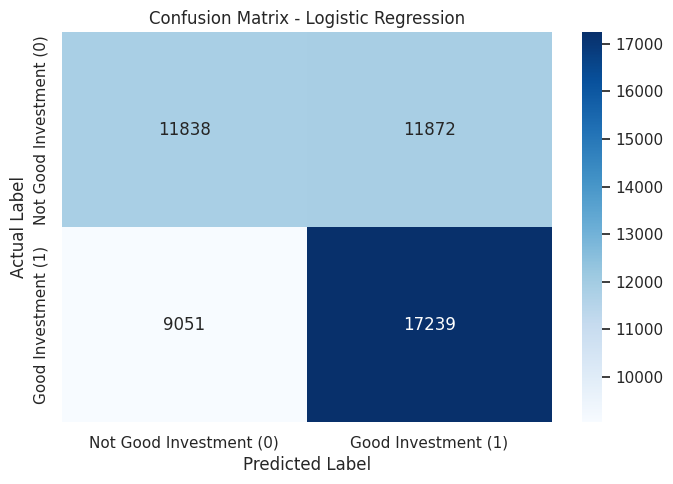

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test_cls, y_pred_lr)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Good Investment (0)', 'Good Investment (1)'],
    yticklabels=['Not Good Investment (0)', 'Good Investment (1)']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

### Insights

The confusion matrix illustrates the prediction performance of the Logistic Regression baseline model. Out of 50,000 test records, the model correctly classified 11,838 properties as not good investments and 17,239 properties as good investments.

However, it incorrectly classified 11,872 properties as good investments and 9,051 properties as not good investments. The model demonstrates a higher ability to identify good-investment properties than to identify properties that are not good investments. These results indicate moderate classification performance.

## 2. Decision Tree Classifier

In [ ]:
import mlflow
import mlflow.sklearn

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Activate persistent experiment
mlflow.set_experiment(
    "Real_Estate_Investment_Advisor_Persistent"
)

# Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

# Train, evaluate and log
with mlflow.start_run(
    run_name="Decision_Tree_Classifier_Final"
) as run:

    # Train model
    decision_tree_model.fit(
        X_train_cls_processed,
        y_train_cls
    )

    # Generate predictions
    y_pred_dt = decision_tree_model.predict(
        X_test_cls_processed
    )

    # Calculate evaluation metrics
    accuracy_dt = accuracy_score(y_test_cls, y_pred_dt)
    precision_dt = precision_score(y_test_cls, y_pred_dt, zero_division=0)
    recall_dt = recall_score(y_test_cls, y_pred_dt, zero_division=0)
    f1_dt = f1_score(y_test_cls, y_pred_dt, zero_division=0)

    # Log parameters
    mlflow.log_params({
        "model": "Decision Tree Classifier",
        "max_depth": 10,
        "min_samples_split": 20,
        "min_samples_leaf": 10,
        "random_state": 42
    })

    # Log metrics
    mlflow.log_metrics({
        "accuracy": accuracy_dt,
        "precision": precision_dt,
        "recall": recall_dt,
        "f1_score": f1_dt
    })

    # Save model using pickle serialization
    mlflow.sklearn.log_model(
        sk_model=decision_tree_model,
        name="decision_tree_classifier",
        serialization_format="pickle"
    )

    print("DECISION TREE CLASSIFIER - FINAL MODEL")
    print("---------------------------------------")
    print(f"Run ID    : {run.info.run_id}")
    print(f"Accuracy  : {accuracy_dt:.4f}")
    print(f"Precision : {precision_dt:.4f}")
    print(f"Recall    : {recall_dt:.4f}")
    print(f"F1-Score  : {f1_dt:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_cls, y_pred_dt))

    print("\nClassification Report:")
    print(classification_report(y_test_cls, y_pred_dt))

    print("\nMLflow model logging completed.")

2026/10/31 08:03:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


DECISION TREE CLASSIFIER - FINAL MODEL
---------------------------------------
Run ID    : a33f695dfe554178991cedc8f4bec1e0
Accuracy  : 0.5811
Precision : 0.5893
Recall    : 0.6709
F1-Score  : 0.6275

Confusion Matrix:
[[11418 12292]
 [ 8651 17639]]

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.48      0.52     23710
           1       0.59      0.67      0.63     26290

    accuracy                           0.58     50000
   macro avg       0.58      0.58      0.57     50000
weighted avg       0.58      0.58      0.58     50000


MLflow model logging completed.


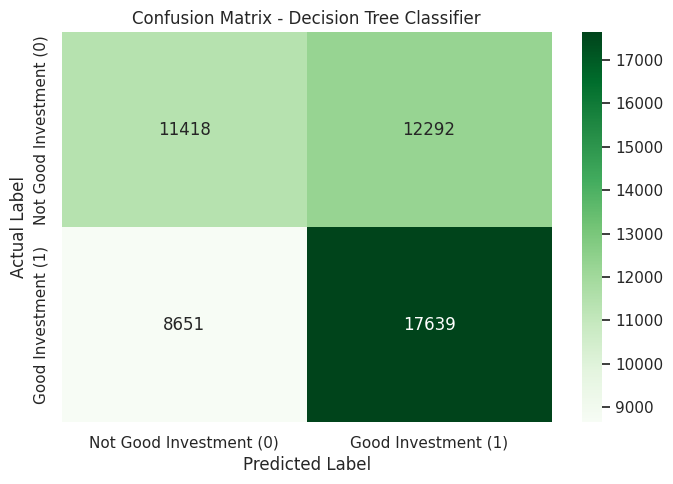

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm_dt = confusion_matrix(y_test_cls, y_pred_dt)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=[
        'Not Good Investment (0)',
        'Good Investment (1)'
    ],
    yticklabels=[
        'Not Good Investment (0)',
        'Good Investment (1)'
    ]
)

plt.title('Confusion Matrix - Decision Tree Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

### Insights

The confusion matrix illustrates the classification performance of the Decision Tree model on the test dataset containing 50,000 records.

The model correctly classified 11,418 properties as not good investments and 17,639 properties as good investments. However, it produced 12,292 false-positive predictions and 8,651 false-negative predictions.

The model achieved a recall of 67.09% for the Good Investment class, indicating that it identified approximately two-thirds of the actual good-investment properties. The relatively high number of false-positive predictions indicates that the model also incorrectly classified many properties as good investments.

Overall, the Decision Tree model achieved 58.11% accuracy and an F1-score of 62.75%, showing moderate classification performance.

## 3. Random Forest Classifier

In [ ]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Activate persistent MLflow experiment
mlflow.set_experiment(
    "Real_Estate_Investment_Advisor_Persistent"
)

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Train, evaluate and log the model
with mlflow.start_run(
    run_name="Random_Forest_Classifier"
) as run:

    # Model training
    random_forest_model.fit(
        X_train_cls_processed,
        y_train_cls
    )

    # Generate predictions
    y_pred_rf = random_forest_model.predict(
        X_test_cls_processed
    )

    # Calculate evaluation metrics
    accuracy_rf = accuracy_score(y_test_cls, y_pred_rf)
    precision_rf = precision_score(
        y_test_cls, y_pred_rf, zero_division=0
    )
    recall_rf = recall_score(
        y_test_cls, y_pred_rf, zero_division=0
    )
    f1_rf = f1_score(
        y_test_cls, y_pred_rf, zero_division=0
    )

    # Log model parameters
    mlflow.log_params({
        "model": "Random Forest Classifier",
        "n_estimators": 100,
        "max_depth": 10,
        "min_samples_split": 20,
        "min_samples_leaf": 10,
        "random_state": 42
    })

    # Log evaluation metrics
    mlflow.log_metrics({
        "accuracy": accuracy_rf,
        "precision": precision_rf,
        "recall": recall_rf,
        "f1_score": f1_rf
    })

    # Log model using pickle serialization
    mlflow.sklearn.log_model(
        sk_model=random_forest_model,
        name="random_forest_classifier",
        serialization_format="pickle"
    )

    # Display results
    print("RANDOM FOREST CLASSIFIER")
    print("------------------------")
    print("Run ID:", run.info.run_id)
    print(f"Accuracy : {accuracy_rf:.4f}")
    print(f"Precision: {precision_rf:.4f}")
    print(f"Recall   : {recall_rf:.4f}")
    print(f"F1-Score : {f1_rf:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_cls, y_pred_rf))

    print("\nClassification Report:")
    print(classification_report(y_test_cls, y_pred_rf))

    print("\nRandom Forest model logged successfully!")

2026/10/31 08:08:28 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RANDOM FOREST CLASSIFIER
------------------------
Run ID: 7099ed8709674e1cb69eed5e03bb7da8
Accuracy : 0.5463
Precision: 0.5415
Recall   : 0.8944
F1-Score : 0.6746

Confusion Matrix:
[[ 3802 19908]
 [ 2776 23514]]

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.16      0.25     23710
           1       0.54      0.89      0.67     26290

    accuracy                           0.55     50000
   macro avg       0.56      0.53      0.46     50000
weighted avg       0.56      0.55      0.47     50000


Random Forest model logged successfully!


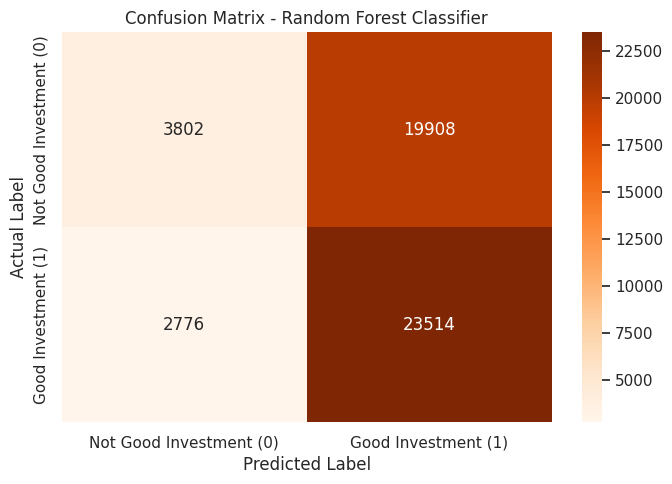

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm_rf = confusion_matrix(y_test_cls, y_pred_rf)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=[
        'Not Good Investment (0)',
        'Good Investment (1)'
    ],
    yticklabels=[
        'Not Good Investment (0)',
        'Good Investment (1)'
    ]
)

plt.title('Confusion Matrix - Random Forest Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

### Insights

The confusion matrix illustrates the classification performance of the Random Forest model on the test dataset containing 50,000 records.

The model correctly classified 3,802 properties as not good investments and 23,514 properties as good investments. However, it produced 19,908 false-positive predictions and 2,776 false-negative predictions.

The model achieved a recall of **89.44%** for the Good Investment class, indicating that it successfully identified most of the actual good-investment properties. However, the high number of false-positive predictions indicates that it frequently misclassified properties that were not good investments.

Overall, the Random Forest model achieved an accuracy of **54.63%** and an F1-score of **67.46%**. Although it demonstrated the highest recall and F1-score among the three classification models, its ability to correctly identify properties that are not good investments remains limited.

## 4. XGBoost Classifier

In [ ]:
!pip install xgboost

In [ ]:
import xgboost as xgb
import mlflow
import mlflow.sklearn

from xgboost import XGBClassifier

print("XGBoost Version:", xgb.__version__)

XGBoost Version: 3.4.1


In [ ]:
# Activate persistent MLflow experiment
mlflow.set_experiment(
    "Real_Estate_Investment_Advisor_Persistent"
)

# Create XGBoost classifier
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train, evaluate and log the model
with mlflow.start_run(
    run_name="XGBoost_Classifier"
) as run:

    # Train model
    xgb_model.fit(
        X_train_cls_processed,
        y_train_cls
    )

    # Generate predictions
    y_pred_xgb = xgb_model.predict(
        X_test_cls_processed
    )

    # Calculate evaluation metrics
    accuracy_xgb = accuracy_score(y_test_cls, y_pred_xgb)
    precision_xgb = precision_score(
        y_test_cls, y_pred_xgb, zero_division=0
    )
    recall_xgb = recall_score(
        y_test_cls, y_pred_xgb, zero_division=0
    )
    f1_xgb = f1_score(
        y_test_cls, y_pred_xgb, zero_division=0
    )

    # Log parameters
    mlflow.log_params({
        "model": "XGBoost Classifier",
        "n_estimators": 100,
        "max_depth": 6,
        "learning_rate": 0.1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "random_state": 42
    })

    # Log metrics
    mlflow.log_metrics({
        "accuracy": accuracy_xgb,
        "precision": precision_xgb,
        "recall": recall_xgb,
        "f1_score": f1_xgb
    })

    # Log model using pickle serialization
    mlflow.sklearn.log_model(
        sk_model=xgb_model,
        name="xgboost_classifier",
        serialization_format="pickle"
    )

    # Display results
    print("XGBOOST CLASSIFIER")
    print("------------------")
    print("Run ID:", run.info.run_id)
    print(f"Accuracy : {accuracy_xgb:.4f}")
    print(f"Precision: {precision_xgb:.4f}")
    print(f"Recall   : {recall_xgb:.4f}")
    print(f"F1-Score : {f1_xgb:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_cls, y_pred_xgb))

    print("\nClassification Report:")
    print(classification_report(y_test_cls, y_pred_xgb))

    print("\nXGBoost model logged successfully!")

2026/10/31 08:14:39 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBOOST CLASSIFIER
------------------
Run ID: 8d5079c7dc4c40bc81a59e9a1e57142a
Accuracy : 0.5801
Precision: 0.5903
Recall   : 0.6583
F1-Score : 0.6224

Confusion Matrix:
[[11697 12013]
 [ 8983 17307]]

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.49      0.53     23710
           1       0.59      0.66      0.62     26290

    accuracy                           0.58     50000
   macro avg       0.58      0.58      0.57     50000
weighted avg       0.58      0.58      0.58     50000


XGBoost model logged successfully!


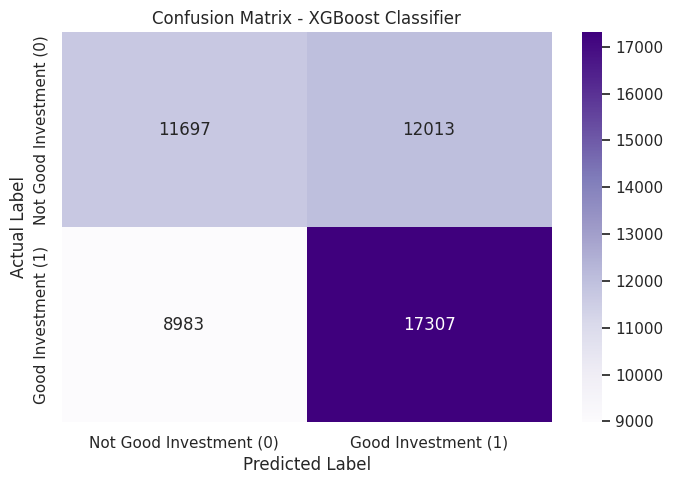

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm_xgb = confusion_matrix(y_test_cls, y_pred_xgb)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=[
        'Not Good Investment (0)',
        'Good Investment (1)'
    ],
    yticklabels=[
        'Not Good Investment (0)',
        'Good Investment (1)'
    ]
)

plt.title('Confusion Matrix - XGBoost Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

### Insights

The confusion matrix illustrates the classification performance of the XGBoost model on the test dataset containing 50,000 records.

The model correctly classified 11,697 properties as not good investments and 17,307 properties as good investments. However, it produced 12,013 false-positive predictions and 8,983 false-negative predictions.

The model achieved a recall of **65.83%** for the Good Investment class, indicating that it identified approximately two-thirds of the actual good-investment properties. Its precision of **59.03%** indicates that some properties predicted as good investments were incorrectly classified.

Overall, the XGBoost model achieved an accuracy of **58.01%** and an F1-score of **62.24%**. Its performance is comparable to Logistic Regression and Decision Tree, but it has not demonstrated a significant improvement over these baseline models.

### Prepare model comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.5815,0.5922,0.6557,0.6223
1,Decision Tree,0.5811,0.5893,0.6709,0.6275
2,Random Forest,0.5463,0.5415,0.8944,0.6746
3,XGBoost,0.5801,0.5903,0.6583,0.6224


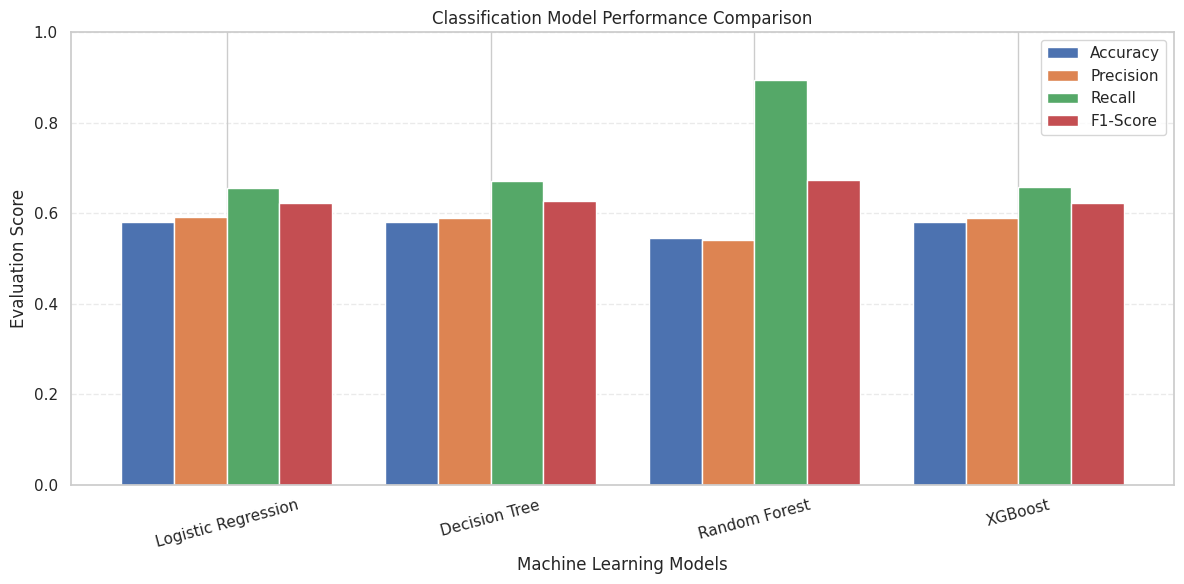

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Prepare model comparison data
comparison_data = {
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        accuracy, accuracy_dt, accuracy_rf, accuracy_xgb
    ],
    'Precision': [
        precision, precision_dt, precision_rf, precision_xgb
    ],
    'Recall': [
        recall, recall_dt, recall_rf, recall_xgb
    ],
    'F1-Score': [
        f1, f1_dt, f1_rf, f1_xgb
    ]
}

comparison_df = pd.DataFrame(comparison_data)

# Display comparison table
display(comparison_df.round(4))

# Plot grouped bar chart
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

x = np.arange(len(comparison_df['Model']))
width = 0.2

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        comparison_df[metric],
        width,
        label=metric
    )

plt.title('Classification Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Evaluation Score')
plt.xticks(x, comparison_df['Model'], rotation=15)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Insights

The performance comparison of four classification algorithms—Logistic Regression, Decision Tree, Random Forest, and XGBoost—shows differences in their predictive capabilities.

Logistic Regression achieved the highest accuracy of **58.15%**, while Random Forest achieved the highest recall of **89.44%** and the highest F1-score of **67.46%**. Decision Tree achieved an accuracy of **58.11%** and an F1-score of **62.75%**, whereas XGBoost achieved an accuracy of **58.01%** and an F1-score of **62.24%**.

Although Random Forest demonstrated better recall and F1-score, its precision of 54.15% and accuracy of 54.63% were comparatively lower. This indicates that it identified more good-investment properties but also generated a larger number of false-positive predictions.

Overall, Random Forest provides the best balance between precision and recall according to the F1-score, while Logistic Regression performs slightly better in terms of overall accuracy. Further evaluation and hyperparameter tuning may help improve classification performance.

## Regression Model

**Objective:** Develop machine learning regression models to predict the estimated property price after five years based on available property characteristics.

**Target Variable:** `Future_Price_5Y`

**Models Used:**

1. Linear Regression (Baseline Model)
2. Additional regression algorithms will be evaluated and compared during model development.

**Evaluation Metrics:**

- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- R² Score

**Data Preparation:**

The dataset has already been divided into training and testing sets using an 80:20 split. Numerical features were standardized using `StandardScaler`, while categorical features were encoded using `OneHotEncoder`. The preprocessing transformations were fitted on the training dataset and applied to the testing dataset.

**Model Experimentation and Tracking:**

The regression models will be trained and evaluated using the prepared training and testing datasets. MLflow will be used to track model parameters, evaluation metrics, experiment runs and trained model artifacts.

In [ ]:
print("Regression Training Data:", X_train_reg_processed.shape)
print("Regression Testing Data:", X_test_reg_processed.shape)

print("Training Target:", y_train_reg.shape)
print("Testing Target:", y_test_reg.shape)

print("\nTraining Target Summary:")
print(y_train_reg.describe())

print("\nTesting Target Summary:")
print(y_test_reg.describe())

Regression Training Data: (200000, 599)
Regression Testing Data: (50000, 599)
Training Target: (200000,)
Testing Target: (50000,)

Training Target Summary:
count    200000.000000
mean        374.024685
std         207.746929
min          14.693281
25%         194.627197
50%         373.422384
75%         553.584046
max         734.664038
Name: Future_Price_5Y, dtype: float64

Testing Target Summary:
count    50000.000000
mean       374.259324
std        207.461134
min         14.722667
25%        195.303088
50%        371.482871
75%        554.528090
max        734.605265
Name: Future_Price_5Y, dtype: float64


## 1. Linear Regression – Baseline Model

In [ ]:
# Import required libraries
import numpy as np
import mlflow
import mlflow.sklearn

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Activate persistent MLflow experiment
mlflow.set_experiment(
    "Real_Estate_Investment_Advisor_Persistent"
)

# Create Linear Regression model
linear_model = LinearRegression()

# Train, evaluate and log model
with mlflow.start_run(
    run_name="Linear_Regression_Baseline"
) as run:

    # Train model
    linear_model.fit(
        X_train_reg_processed,
        y_train_reg
    )

    # Generate predictions
    y_pred_lr_reg = linear_model.predict(
        X_test_reg_processed
    )

    # Calculate evaluation metrics
    rmse_lr = np.sqrt(
        mean_squared_error(y_test_reg, y_pred_lr_reg)
    )

    mae_lr = mean_absolute_error(
        y_test_reg, y_pred_lr_reg
    )

    r2_lr = r2_score(
        y_test_reg, y_pred_lr_reg
    )

    # Log model parameters
    mlflow.log_param(
        "model", "Linear Regression"
    )

    # Log evaluation metrics
    mlflow.log_metrics({
        "RMSE": rmse_lr,
        "MAE": mae_lr,
        "R2_Score": r2_lr
    })

    # Log trained model
    mlflow.sklearn.log_model(
        sk_model=linear_model,
        name="linear_regression_baseline",
        serialization_format="pickle"
    )

    # Display results
    print("LINEAR REGRESSION - BASELINE MODEL")
    print("----------------------------------")
    print("Run ID:", run.info.run_id)
    print(f"RMSE   : {rmse_lr:.4f}")
    print(f"MAE    : {mae_lr:.4f}")
    print(f"R2 Score: {r2_lr:.4f}")

    print("\nLinear Regression model logged successfully!")

2026/10/31 09:15:42 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LINEAR REGRESSION - BASELINE MODEL
----------------------------------
Run ID: 7bc933044958433d813936151d3b6108
RMSE   : 0.0009
MAE    : 0.0006
R2 Score: 1.0000

Linear Regression model logged successfully!


### Insights

The Linear Regression baseline model achieved an **RMSE of 0.0009**, **MAE of 0.0006**, and an **R² score of 1.0000** on the test dataset.

The extremely low RMSE and MAE values indicate that the predicted five-year property prices are very close to the actual target values. The R² score of 1.0000 indicates that the model explains almost all the variation in the target variable.

These results demonstrate that Linear Regression successfully learned the relationship between the input features and the target variable, `Future_Price_5Y`.

However, the target variable was generated using a fixed annual appreciation assumption of 8%, and `Price_in_Lakhs` is included among the input features. Therefore, the near-perfect performance is expected because the model is learning an existing mathematical relationship rather than forecasting independently observed future market prices. The results should be interpreted as the model's ability to reproduce the simulated five-year price calculation.

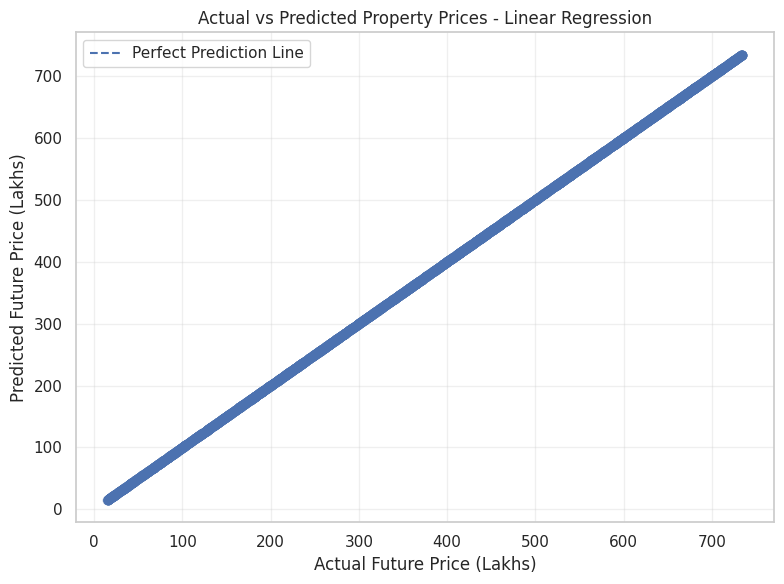

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Sample 5,000 records for clearer visualization
np.random.seed(42)

sample_indices = np.random.choice(
    len(y_test_reg),
    size=5000,
    replace=False
)

actual_values = np.asarray(y_test_reg)[sample_indices]
predicted_values = y_pred_lr_reg[sample_indices]

# Create scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(
    actual_values,
    predicted_values,
    alpha=0.5
)

# Reference line: perfect predictions
min_value = min(actual_values.min(), predicted_values.min())
max_value = max(actual_values.max(), predicted_values.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction Line'
)

plt.title('Actual vs Predicted Property Prices - Linear Regression')
plt.xlabel('Actual Future Price (Lakhs)')
plt.ylabel('Predicted Future Price (Lakhs)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Insights

The Actual vs Predicted Property Prices visualization demonstrates a very close alignment between the actual and predicted five-year property prices generated by the Linear Regression model.

Most data points overlap the perfect prediction line, indicating that the model produces predictions that are extremely close to the actual target values across the observed price range.

This visual result is consistent with the evaluation metrics, which include an RMSE of 0.0009, an MAE of 0.0006, and an R² score of 1.0000.

However, this near-perfect prediction performance is largely due to the simulated target variable, which was calculated using an assumed annual appreciation rate of 8%. Since the current property price is also included as an input feature, the model has learned the mathematical relationship used to generate the target rather than an independently observed future market trend.

## 2. Decision Tree Regressor

In [ ]:
# Import Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

# Activate persistent MLflow experiment
mlflow.set_experiment(
    "Real_Estate_Investment_Advisor_Persistent"
)

# Create Decision Tree Regressor
decision_tree_reg = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42
)

# Train, evaluate and log model
with mlflow.start_run(
    run_name="Decision_Tree_Regressor"
) as run:

    # Train model
    decision_tree_reg.fit(
        X_train_reg_processed,
        y_train_reg
    )

    # Generate predictions
    y_pred_dt_reg = decision_tree_reg.predict(
        X_test_reg_processed
    )

    # Calculate evaluation metrics
    rmse_dt = np.sqrt(
        mean_squared_error(y_test_reg, y_pred_dt_reg)
    )

    mae_dt = mean_absolute_error(
        y_test_reg, y_pred_dt_reg
    )

    r2_dt = r2_score(
        y_test_reg, y_pred_dt_reg
    )

    # Log parameters
    mlflow.log_params({
        "model": "Decision Tree Regressor",
        "max_depth": 10,
        "min_samples_split": 20,
        "min_samples_leaf": 10,
        "random_state": 42
    })

    # Log metrics
    mlflow.log_metrics({
        "RMSE": rmse_dt,
        "MAE": mae_dt,
        "R2_Score": r2_dt
    })

    # Log model using pickle serialization
    mlflow.sklearn.log_model(
        sk_model=decision_tree_reg,
        name="decision_tree_regressor",
        serialization_format="pickle"
    )

    # Display results
    print("DECISION TREE REGRESSOR")
    print("-----------------------")
    print("Run ID:", run.info.run_id)
    print(f"RMSE    : {rmse_dt:.4f}")
    print(f"MAE     : {mae_dt:.4f}")
    print(f"R2 Score: {r2_dt:.4f}")

    print("\nDecision Tree Regressor logged successfully!")

2026/10/31 09:28:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


DECISION TREE REGRESSOR
-----------------------
Run ID: 4566fdf8a5764e088c1c276e26e8327d
RMSE    : 0.2037
MAE     : 0.1759
R2 Score: 1.0000

Decision Tree Regressor logged successfully!


### Insights

The Decision Tree Regressor achieved an **RMSE of 0.2037**, **MAE of 0.1759**, and an **R² score of 1.0000** on the test dataset.

The relatively low RMSE and MAE values indicate that the model's predicted five-year property prices are close to the actual target values. The R² score of 1.0000 indicates that the model explains almost all the variation in the target variable, although the displayed value is rounded to four decimal places.

Compared with the Linear Regression baseline, the Decision Tree Regressor produced slightly higher prediction errors. Therefore, Linear Regression currently demonstrates better performance in terms of RMSE and MAE.

However, the target variable was generated using an assumed annual appreciation rate of 8%, and the current property price is included among the input features. Consequently, these results measure the model's ability to reproduce the simulated price calculation rather than predict independently observed future market prices.

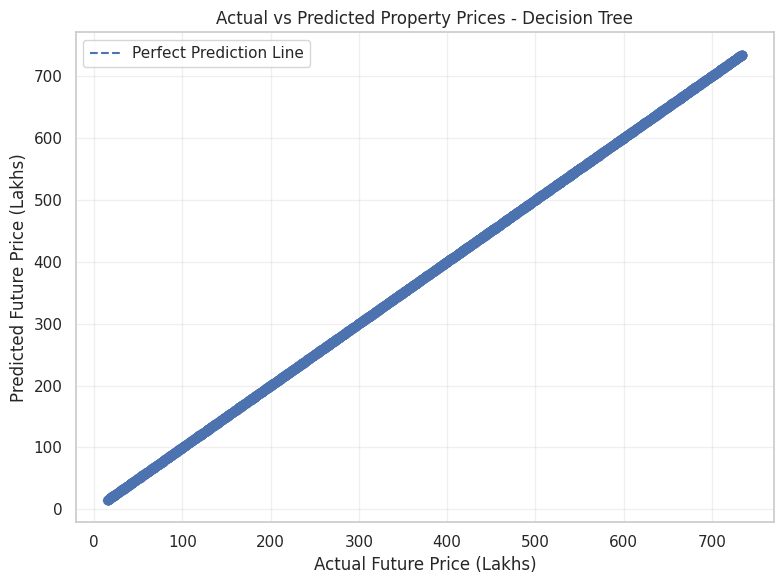

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

sample_indices = np.random.choice(
    len(y_test_reg),
    size=5000,
    replace=False
)

actual_values = np.asarray(y_test_reg)[sample_indices]
predicted_values = y_pred_dt_reg[sample_indices]

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_values,
    predicted_values,
    alpha=0.5
)

min_value = min(actual_values.min(), predicted_values.min())
max_value = max(actual_values.max(), predicted_values.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction Line'
)

plt.title('Actual vs Predicted Property Prices - Decision Tree')
plt.xlabel('Actual Future Price (Lakhs)')
plt.ylabel('Predicted Future Price (Lakhs)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Insights

The Actual vs Predicted Property Prices visualization shows a very close alignment between the actual and predicted five-year property prices generated by the Decision Tree Regressor.

The plotted points are concentrated along the perfect prediction line, indicating that the model produces predictions close to the actual target values across the observed price range.

This visual observation is consistent with the evaluation metrics: RMSE of 0.2037, MAE of 0.1759, and an R² score of 1.0000.

Compared with the Linear Regression baseline, the Decision Tree Regressor has slightly higher RMSE and MAE values, indicating marginally greater prediction errors.

However, the target variable was generated using an assumed annual appreciation rate of 8%. Since the current property price is included as an input feature, the model is learning the simulated mathematical relationship rather than forecasting independently observed future market prices.

## 3. Random Forest Regressor

In [ ]:
# Import required libraries
import numpy as np
import mlflow
import mlflow.sklearn

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Activate persistent MLflow experiment
mlflow.set_experiment(
    "Real_Estate_Investment_Advisor_Persistent"
)

# Create Random Forest Regressor
random_forest_reg = RandomForestRegressor(
    n_estimators=30,
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

# Train, evaluate and log model
with mlflow.start_run(
    run_name="Random_Forest_Regressor_Retry"
) as run:

    # Train model
    print("Training Random Forest Regressor...")

    random_forest_reg.fit(
        X_train_reg_processed,
        y_train_reg
    )

    print("Model training completed!")

    # Generate predictions
    y_pred_rf_reg = random_forest_reg.predict(
        X_test_reg_processed
    )

    # Calculate evaluation metrics
    rmse_rf = np.sqrt(
        mean_squared_error(
            y_test_reg,
            y_pred_rf_reg
        )
    )

    mae_rf = mean_absolute_error(
        y_test_reg,
        y_pred_rf_reg
    )

    r2_rf = r2_score(
        y_test_reg,
        y_pred_rf_reg
    )

    # Log model parameters
    mlflow.log_params({
        "model": "Random Forest Regressor",
        "n_estimators": 30,
        "max_depth": 8,
        "min_samples_split": 20,
        "min_samples_leaf": 10,
        "random_state": 42
    })

    # Log evaluation metrics
    mlflow.log_metrics({
        "RMSE": rmse_rf,
        "MAE": mae_rf,
        "R2_Score": r2_rf
    })

    # Log trained model
    mlflow.sklearn.log_model(
        sk_model=random_forest_reg,
        name="random_forest_regressor",
        serialization_format="pickle"
    )

    # Display results
    print("\nRANDOM FOREST REGRESSOR")
    print("-----------------------")
    print("Run ID:", run.info.run_id)

    print(f"RMSE    : {rmse_rf:.4f}")
    print(f"MAE     : {mae_rf:.4f}")
    print(f"R2 Score: {r2_rf:.4f}")

    print("\nRandom Forest Regressor logged successfully!")

Training Random Forest Regressor...
Model training completed!


2026/10/31 09:53:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



RANDOM FOREST REGRESSOR
-----------------------
Run ID: 82ffee7420294334a30bc942bfbd439b
RMSE    : 0.4538
MAE     : 0.3898
R2 Score: 1.0000

Random Forest Regressor logged successfully!


### Insights

The Random Forest Regressor achieved an **RMSE of 0.4538**, **MAE of 0.3898**, and an **R² score of 1.0000** on the test dataset.

The RMSE and MAE values indicate that the model produces relatively small prediction errors when estimating the five-year property prices. The R² score of 1.0000 indicates an almost perfect fit to the target variable, rounded to four decimal places.

Compared with the Linear Regression and Decision Tree Regression models, Random Forest produced higher RMSE and MAE values, indicating comparatively larger prediction errors.

The model uses 30 decision trees with a maximum depth of 8 to reduce computational requirements during training.

However, the target variable was generated using an assumed annual appreciation rate of 8%, and the current property price is included among the input features. Therefore, these results reflect the model's ability to reproduce the simulated price calculation rather than forecast independently observed future property prices.

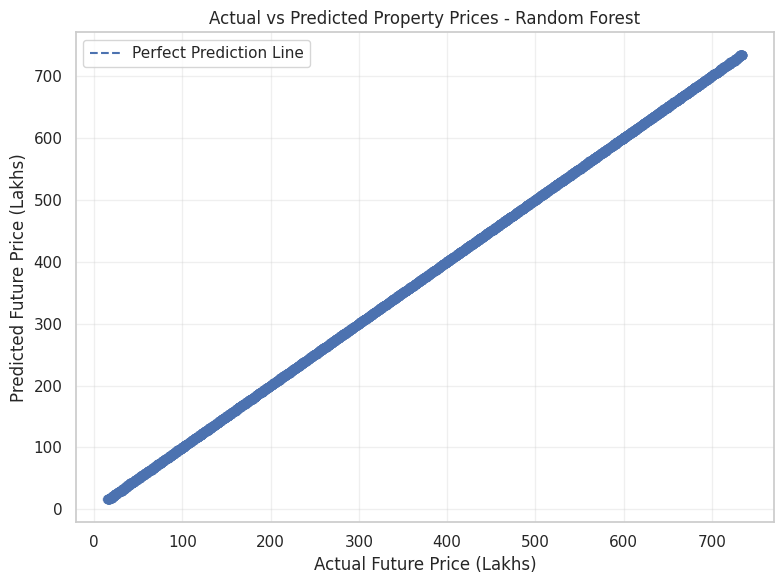

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

sample_indices = np.random.choice(
    len(y_test_reg),
    size=5000,
    replace=False
)

actual_values = np.asarray(y_test_reg)[sample_indices]
predicted_values = y_pred_rf_reg[sample_indices]

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_values,
    predicted_values,
    alpha=0.5
)

min_value = min(actual_values.min(), predicted_values.min())
max_value = max(actual_values.max(), predicted_values.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction Line'
)

plt.title('Actual vs Predicted Property Prices - Random Forest')
plt.xlabel('Actual Future Price (Lakhs)')
plt.ylabel('Predicted Future Price (Lakhs)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Insights

The Actual vs Predicted Property Prices visualization shows a close alignment between the actual and predicted five-year property prices generated by the Random Forest Regressor.

Most plotted points are concentrated around the perfect prediction line, indicating that the model produces predictions close to the actual target values across the observed price range.

This visual observation is consistent with the evaluation metrics: RMSE of 0.4538, MAE of 0.3898, and an R² score of 1.0000.

Compared with Linear Regression and Decision Tree Regression, Random Forest produced higher RMSE and MAE values, indicating comparatively larger prediction errors.

However, the target variable was generated using an assumed annual appreciation rate of 8%. Since the current property price is included as an input feature, the model is learning the simulated mathematical relationship rather than forecasting independently observed future market prices.

## 4. XGBoost Regressor

In [ ]:
# Import XGBoost libraries
import xgboost as xgb
from xgboost import XGBRegressor

import mlflow
import mlflow.sklearn
import numpy as np

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("XGBoost Version:", xgb.__version__)
print("XGBRegressor imported successfully!")

XGBoost Version: 3.4.1
XGBRegressor imported successfully!


In [ ]:
# Activate persistent MLflow experiment
mlflow.set_experiment(
    "Real_Estate_Investment_Advisor_Persistent"
)

# Create XGBoost Regressor
xgb_reg_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train, evaluate and log model
with mlflow.start_run(
    run_name="XGBoost_Regressor"
) as run:

    # Train model
    print("Training XGBoost Regressor...")

    xgb_reg_model.fit(
        X_train_reg_processed,
        y_train_reg
    )

    print("Model training completed!")

    # Generate predictions
    y_pred_xgb_reg = xgb_reg_model.predict(
        X_test_reg_processed
    )

    # Calculate evaluation metrics
    rmse_xgb = np.sqrt(
        mean_squared_error(
            y_test_reg,
            y_pred_xgb_reg
        )
    )

    mae_xgb = mean_absolute_error(
        y_test_reg,
        y_pred_xgb_reg
    )

    r2_xgb = r2_score(
        y_test_reg,
        y_pred_xgb_reg
    )

    # Log model parameters
    mlflow.log_params({
        "model": "XGBoost Regressor",
        "n_estimators": 100,
        "max_depth": 6,
        "learning_rate": 0.1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "objective": "reg:squarederror",
        "random_state": 42
    })

    # Log evaluation metrics
    mlflow.log_metrics({
        "RMSE": rmse_xgb,
        "MAE": mae_xgb,
        "R2_Score": r2_xgb
    })

    # Log trained model
    mlflow.sklearn.log_model(
        sk_model=xgb_reg_model,
        name="xgboost_regressor",
        serialization_format="pickle"
    )

    # Display results
    print("\nXGBOOST REGRESSOR")
    print("-----------------")
    print("Run ID:", run.info.run_id)

    print(f"RMSE    : {rmse_xgb:.4f}")
    print(f"MAE     : {mae_xgb:.4f}")
    print(f"R2 Score: {r2_xgb:.4f}")

    print("\nXGBoost Regressor logged successfully!")

Training XGBoost Regressor...
Model training completed!


2026/10/31 09:59:19 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



XGBOOST REGRESSOR
-----------------
Run ID: 6cf632336cfc43f4b638aad577414a7d
RMSE    : 0.9910
MAE     : 0.7360
R2 Score: 1.0000

XGBoost Regressor logged successfully!


### Insights

The XGBoost Regressor achieved an **RMSE of 0.9910**, **MAE of 0.7360**, and an **R² score of 1.0000** on the test dataset.

The evaluation results indicate that the model produces predictions relatively close to the actual five-year property prices. The R² score of 1.0000 indicates an almost perfect fit to the target variable when rounded to four decimal places.

Compared with Linear Regression, Decision Tree Regressor, and Random Forest Regressor, XGBoost produced higher RMSE and MAE values, indicating comparatively larger prediction errors among the four regression models evaluated so far.

However, the target variable was generated using an assumed annual appreciation rate of 8%, and the current property price is included among the input features. Therefore, these results reflect the model's ability to reproduce the simulated price calculation rather than forecast independently observed future property prices.

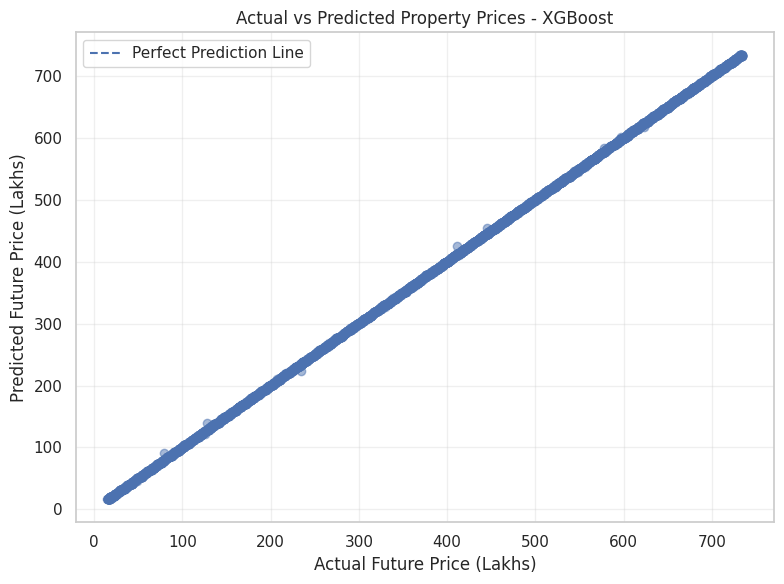

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

sample_indices = np.random.choice(
    len(y_test_reg),
    size=5000,
    replace=False
)

actual_values = np.asarray(y_test_reg)[sample_indices]
predicted_values = y_pred_xgb_reg[sample_indices]

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_values,
    predicted_values,
    alpha=0.5
)

min_value = min(actual_values.min(), predicted_values.min())
max_value = max(actual_values.max(), predicted_values.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Perfect Prediction Line'
)

plt.title('Actual vs Predicted Property Prices - XGBoost')
plt.xlabel('Actual Future Price (Lakhs)')
plt.ylabel('Predicted Future Price (Lakhs)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Insights

The Actual vs Predicted Property Prices visualization demonstrates a close alignment between the actual and predicted five-year property prices generated by the XGBoost Regressor.

Most plotted points are concentrated around the perfect prediction line, indicating that the model produces predictions close to the actual target values across the observed price range. A few minor deviations from the reference line are also visible.

This visual observation is consistent with the evaluation metrics: RMSE of 0.9910, MAE of 0.7360, and an R² score of 1.0000.

Compared with the other regression models evaluated so far, XGBoost produced higher RMSE and MAE values, indicating comparatively larger prediction errors.

However, the target variable was generated using an assumed annual appreciation rate of 8%. Since the current property price is included as an input feature, the model is learning the simulated mathematical relationship rather than forecasting independently observed future property prices.

## Regression model comparison

REGRESSION MODEL PERFORMANCE COMPARISON
----------------------------------------


,Model,RMSE,MAE,R2 Score
0,Linear Regression,0.000868,0.000635,1.000000
1,Decision Tree,0.203705,0.175894,0.999999
2,Random Forest,0.453775,0.389777,0.999995
3,XGBoost,0.990959,0.735999,0.999977


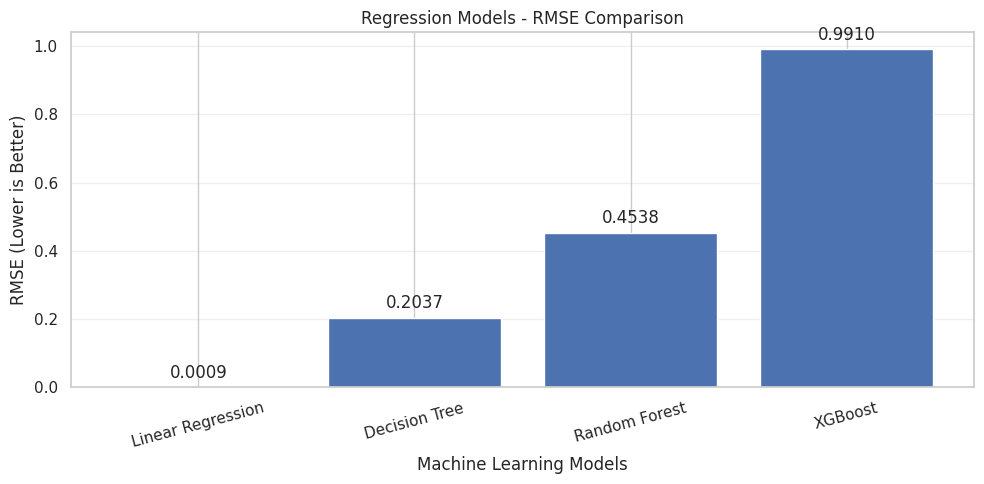

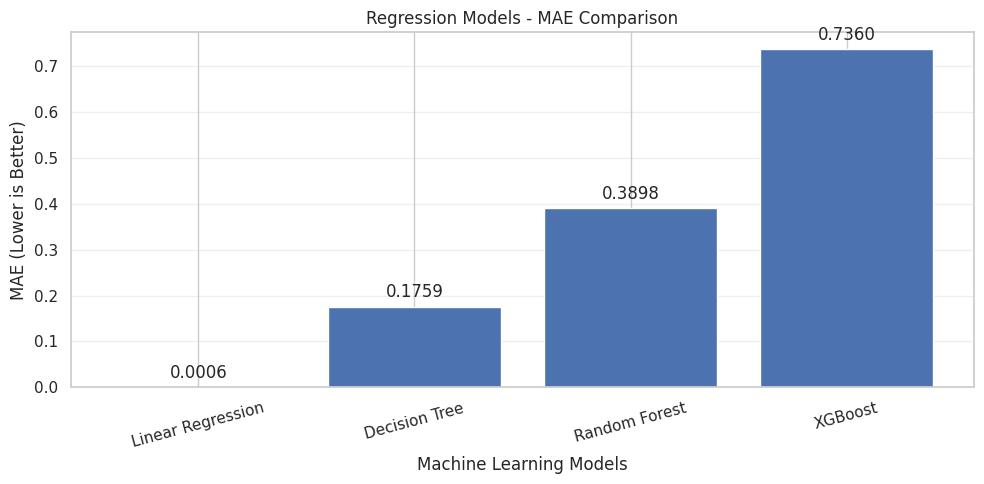

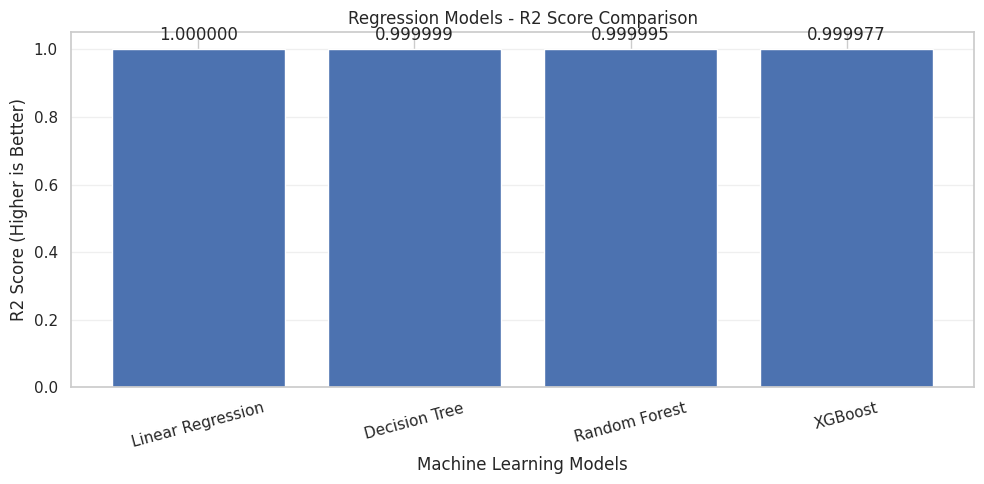

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Create regression model comparison table
regression_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],
    'RMSE': [
        rmse_lr,
        rmse_dt,
        rmse_rf,
        rmse_xgb
    ],
    'MAE': [
        mae_lr,
        mae_dt,
        mae_rf,
        mae_xgb
    ],
    'R2 Score': [
        r2_lr,
        r2_dt,
        r2_rf,
        r2_xgb
    ]
})

# Display comparison table
print("REGRESSION MODEL PERFORMANCE COMPARISON")
print("----------------------------------------")
display(regression_comparison.round(6))


# -----------------------------------------
# 1. RMSE COMPARISON
# -----------------------------------------

plt.figure(figsize=(10, 5))

bars = plt.bar(
    regression_comparison['Model'],
    regression_comparison['RMSE']
)

plt.title('Regression Models - RMSE Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('RMSE (Lower is Better)')
plt.xticks(rotation=15)

plt.bar_label(bars, fmt='%.4f', padding=4)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# 2. MAE COMPARISON
# -----------------------------------------

plt.figure(figsize=(10, 5))

bars = plt.bar(
    regression_comparison['Model'],
    regression_comparison['MAE']
)

plt.title('Regression Models - MAE Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('MAE (Lower is Better)')
plt.xticks(rotation=15)

plt.bar_label(bars, fmt='%.4f', padding=4)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------
# 3. R2 SCORE COMPARISON
# -----------------------------------------

plt.figure(figsize=(10, 5))

bars = plt.bar(
    regression_comparison['Model'],
    regression_comparison['R2 Score']
)

plt.title('Regression Models - R2 Score Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('R2 Score (Higher is Better)')
plt.xticks(rotation=15)

plt.bar_label(bars, fmt='%.6f', padding=4)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Insights

The performance comparison of four regression algorithms—Linear Regression, Decision Tree Regressor, Random Forest Regressor, and XGBoost Regressor—shows differences in their prediction errors.

Linear Regression achieved the lowest RMSE of **0.0009** and MAE of **0.0006**, along with the highest R² score of **1.000000**. Decision Tree achieved an RMSE of 0.2037, MAE of 0.1759, and R² score of 0.999999.

Random Forest produced an RMSE of 0.4538, MAE of 0.3898, and R² score of 0.999995. XGBoost recorded the highest RMSE of 0.9910 and MAE of 0.7360, with an R² score of 0.999977.

Based on these evaluation metrics, Linear Regression performed best among the four models, producing the lowest prediction errors and highest R² score. Decision Tree ranked second, followed by Random Forest and XGBoost.

All four models achieved R² scores very close to 1.0. However, this exceptionally high performance is largely explained by the target variable being generated using a fixed annual appreciation assumption of 8%, while the current property price is included among the input features. Therefore, the comparison evaluates how accurately the models reproduce the simulated five-year price calculation rather than their ability to forecast independently observed future property prices.

## MLflow Experiment Tracking Verification

In [ ]:
import mlflow
import pandas as pd

# Connect to persistent MLflow database
mlflow.set_tracking_uri(
    f"sqlite:///{MLFLOW_DB}"
)

# Select the persistent experiment
experiment = mlflow.get_experiment_by_name(
    "Real_Estate_Investment_Advisor_Persistent"
)

# Retrieve all experiment runs
runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    output_format="pandas"
)

# Display relevant columns
columns_to_display = [
    "run_id",
    "status",
    "tags.mlflow.runName",
    "metrics.accuracy",
    "metrics.precision",
    "metrics.recall",
    "metrics.f1_score",
    "metrics.RMSE",
    "metrics.MAE",
    "metrics.R2_Score"
]

# Keep only columns available in the results
available_columns = [
    col for col in columns_to_display
    if col in runs_df.columns
]

print("MLFLOW EXPERIMENT TRACKING REPORT")
print("---------------------------------")
print("Experiment Name:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Total Runs:", len(runs_df))

display(
    runs_df[available_columns].round(6)
)

MLFLOW EXPERIMENT TRACKING REPORT
---------------------------------
Experiment Name: Real_Estate_Investment_Advisor_Persistent
Experiment ID: 2
Total Runs: 10


,run_id,status,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.RMSE,metrics.MAE,metrics.R2_Score
0,6cf632336cfc43f4b638aad577414a7d,FINISHED,XGBoost_Regressor,NaN,NaN,NaN,NaN,0.990959,0.735999,0.999977
1,82ffee7420294334a30bc942bfbd439b,FINISHED,Random_Forest_Regressor_Retry,NaN,NaN,NaN,NaN,0.453775,0.389777,0.999995
2,d74e156832c5441b96a69589880563ee,FAILED,Random_Forest_Regressor,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4566fdf8a5764e088c1c276e26e8327d,FINISHED,Decision_Tree_Regressor,NaN,NaN,NaN,NaN,0.203705,0.175894,0.999999
4,7bc933044958433d813936151d3b6108,FINISHED,Linear_Regression_Baseline,NaN,NaN,NaN,NaN,0.000868,0.000635,1.000000
5,8d5079c7dc4c40bc81a59e9a1e57142a,FINISHED,XGBoost_Classifier,0.58008,0.590280,0.658311,0.622442,NaN,NaN,NaN
6,7099ed8709674e1cb69eed5e03bb7da8,FINISHED,Random_Forest_Classifier,0.54632,0.541523,0.894409,0.674604,NaN,NaN,NaN
7,a33f695dfe554178991cedc8f4bec1e0,FINISHED,Decision_Tree_Classifier_Final,0.58114,0.589322,0.670940,0.627488,NaN,NaN,NaN
8,0e887e6ad2de441e8932119b66c3206f,FINISHED,Logistic_Regression_Baseline,0.58154,0.592182,0.655725,0.622335,NaN,NaN,NaN
9,4efe3ee7c2634b3d888e655de48ca843,FINISHED,MLflow_Setup_Verification,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Insights

The MLflow experiment tracking report confirms that all four classification models and all four regression models were successfully trained, evaluated, and logged in the persistent experiment.

A total of 10 experiment runs were recorded, including eight successful model runs, one failed Random Forest Regressor attempt, and one MLflow setup verification run.

For classification, Random Forest achieved the highest F1-score of 67.46%, while Logistic Regression achieved the highest accuracy of 58.15%.

For regression, Linear Regression achieved the lowest RMSE and MAE values and the highest R² score, making it the best-performing model among the four evaluated algorithms for the simulated target.

The experiment tracking results demonstrate that MLflow successfully records model runs, evaluation metrics, and model artifacts for both classification and regression tasks.

##  Save Version 1 Models & Register in MLflow

In [ ]:
import mlflow
import pandas as pd
from mlflow.tracking import MlflowClient

# -----------------------------------------
# 1. CONNECT TO PERSISTENT MLFLOW DATABASE
# -----------------------------------------

mlflow.set_tracking_uri(
    f"sqlite:///{MLFLOW_DB}"
)

client = MlflowClient()

# Select persistent experiment
experiment_name = "Real_Estate_Investment_Advisor_Persistent"

mlflow.set_experiment(experiment_name)

# -----------------------------------------
# 2. SELECT BEST PERFORMING MODELS
# -----------------------------------------

# Logistic Regression - Highest classification accuracy
classification_run_id = "0e887e6ad2de441e8932119b66c3206f"

# Linear Regression - Lowest regression RMSE and MAE
regression_run_id = "7bc933044958433d813936151d3b6108"

# Registered model names
classification_model_name = (
    "Real_Estate_Good_Investment_Classifier"
)

regression_model_name = (
    "Real_Estate_Future_Price_Regressor"
)

# -----------------------------------------
# 3. DEFINE REGISTRATION FUNCTION
# -----------------------------------------

def register_selected_model(run_id, registered_name):

    # Search for logged models from the selected run
    logged_models = mlflow.search_logged_models(
        filter_string=f"source_run_id = '{run_id}'"
    )

    # Check whether model exists
    if logged_models.empty:
        raise ValueError(
            f"No logged model found for run ID: {run_id}"
        )

    # Retrieve first matching model
    logged_model = logged_models.iloc[0]

    # Extract model ID
    model_id = logged_model["model_id"]

    # Create model URI
    model_uri = f"models:/{model_id}"

    # Register model
    registered_model = mlflow.register_model(
        model_uri=model_uri,
        name=registered_name
    )

    # Display registration information
    print("Registered Model:", registered_name)
    print("Model ID:", model_id)
    print("Model Version:", registered_model.version)
    print("Status:", registered_model.status)

    print("-" * 60)


# -----------------------------------------
# 4. REGISTER CLASSIFICATION MODEL
# -----------------------------------------

print("\nREGISTERING CLASSIFICATION MODEL")
print("=" * 60)

register_selected_model(
    classification_run_id,
    classification_model_name
)


# -----------------------------------------
# 5. REGISTER REGRESSION MODEL
# -----------------------------------------

print("\nREGISTERING REGRESSION MODEL")
print("=" * 60)

register_selected_model(
    regression_run_id,
    regression_model_name
)

print("\nMODEL REGISTRATION PROCESS COMPLETED!")


REGISTERING CLASSIFICATION MODEL
Registered Model: Real_Estate_Good_Investment_Classifier
Model ID: m-3ccfb8eec48748459958b47612a5fa60
Model Version: 1
Status: READY
------------------------------------------------------------

REGISTERING REGRESSION MODEL
Registered Model: Real_Estate_Future_Price_Regressor
Model ID: m-d0aa70a34d1445f5a5263972716ec88e
Model Version: 1
Status: READY
------------------------------------------------------------

MODEL REGISTRATION PROCESS COMPLETED!


Successfully registered model 'Real_Estate_Good_Investment_Classifier'.
Created version '1' of model 'Real_Estate_Good_Investment_Classifier'.
Successfully registered model 'Real_Estate_Future_Price_Regressor'.
Created version '1' of model 'Real_Estate_Future_Price_Regressor'.


### Insights

The two selected machine learning models were successfully registered in the MLflow Model Registry.

Logistic Regression was registered as the primary classification model for predicting whether a property represents a good investment opportunity. Linear Regression was registered as the primary regression model for estimating property prices after five years.

Both models were registered with Version 1 and achieved the READY status, confirming that the registration process was completed successfully.

The registered models are now organized and available for subsequent model retrieval and integration into the Streamlit application.

## Updated Classification Model & Save As Version 2

In [ ]:
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"

df = pd.read_csv(
    BASE_DIR + "/cleaned_real_estate_dataset.csv"
)

print("Dataset shape:", df.shape)
print(df["Good_Investment"].value_counts())

Dataset shape: (250000, 43)
Good_Investment
1    131452
0    118548
Name: count, dtype: int64


In [ ]:

import os
import joblib
import mlflow
import mlflow.sklearn
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. Project paths
# --------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"
MODEL_DIR = os.path.join(BASE_DIR, "models")
MLFLOW_DB = os.path.join(BASE_DIR, "mlflow.db")

os.makedirs(MODEL_DIR, exist_ok=True)

mlflow.set_tracking_uri("sqlite:///" + MLFLOW_DB)

experiment = mlflow.get_experiment_by_name(
    "Real_Estate_Investment_Advisor_Persistent"
)

if experiment is None:
    raise ValueError("MLflow experiment not found.")

mlflow.set_experiment("Real_Estate_Investment_Advisor_Persistent")

# --------------------------------------------------
# 2. Classification features
# --------------------------------------------------

classification_features = [
    "State",
    "City",
    "Locality",
    "Property_Type",
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt_Exact",
    "Furnished_Status",
    "Age_of_Property",
    "Parking_Space",
    "Security",
    "Facing",
    "Owner_Type",
    "Availability_Status",
    "Amenity_Pool",
    "Amenity_Gym",
    "Amenity_Garden",
    "Amenity_Clubhouse",
    "Amenity_Playground",
    "Infrastructure_Score"
]

target = "Good_Investment"

# --------------------------------------------------
# 3. Validate data
# --------------------------------------------------

required_columns = classification_features + [target]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in dataset: {missing_columns}"
    )

classification_df = df[required_columns].copy()

classification_df = classification_df.dropna(
    subset=required_columns
)

X = classification_df[classification_features]
y = classification_df[target].astype(int)

print("Dataset shape:", classification_df.shape)
print("\nTarget distribution:")
print(y.value_counts())

# --------------------------------------------------
# 4. Numerical and categorical features
# --------------------------------------------------

numerical_features = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt_Exact",
    "Age_of_Property",
    "Amenity_Pool",
    "Amenity_Gym",
    "Amenity_Garden",
    "Amenity_Clubhouse",
    "Amenity_Playground",
    "Infrastructure_Score"
]

categorical_features = [
    "State",
    "City",
    "Locality",
    "Property_Type",
    "Furnished_Status",
    "Parking_Space",
    "Security",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

# --------------------------------------------------
# 5. Train-test split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# --------------------------------------------------
# 6. Preprocessing
# --------------------------------------------------

classification_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

X_train_processed = classification_preprocessor.fit_transform(
    X_train
)

X_test_processed = classification_preprocessor.transform(
    X_test
)

print("\nProcessed training:", X_train_processed.shape)
print("Processed testing:", X_test_processed.shape)

# --------------------------------------------------
# 7. Train Logistic Regression
# --------------------------------------------------

classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

classifier.fit(X_train_processed, y_train)

# --------------------------------------------------
# 8. Evaluation
# --------------------------------------------------

y_pred = classifier.predict(X_test_processed)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

cm = confusion_matrix(y_test, y_pred)

print("\nUPDATED CLASSIFICATION RESULTS")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# --------------------------------------------------
# 9. Save updated artifacts
# --------------------------------------------------

joblib.dump(
    classification_preprocessor,
    os.path.join(
        MODEL_DIR,
        "classification_preprocessor.pkl"
    )
)

joblib.dump(
    classifier,
    os.path.join(
        MODEL_DIR,
        "good_investment_classifier.pkl"
    )
)

# --------------------------------------------------
# 10. Log the new model in MLflow
# --------------------------------------------------

with mlflow.start_run(
    run_name="Updated_Logistic_Regression_Classifier"
) as run:

    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("feature_count", len(classification_features))

    mlflow.log_metrics({
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

    mlflow.log_text(
        "\n".join(classification_features),
        "classification_features.txt"
    )

    mlflow.sklearn.log_model(
        classifier,
        name="updated_logistic_regression_classifier"
    )

    new_run_id = run.info.run_id

print("\nUpdated classifier saved successfully.")
print("New MLflow run ID:", new_run_id)


Dataset shape: (250000, 22)

Target distribution:
Good_Investment
1    131452
0    118548
Name: count, dtype: int64

Training shape: (200000, 21)
Testing shape: (50000, 21)

Processed training: (200000, 592)
Processed testing: (50000, 592)

UPDATED CLASSIFICATION RESULTS
Accuracy: 0.88742
Precision: 0.8913216409712489
Recall: 0.895017116774439
F1 Score: 0.8931655563779917

Confusion Matrix:
[[20841  2869]
 [ 2760 23530]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88     23710
           1       0.89      0.90      0.89     26290

    accuracy                           0.89     50000
   macro avg       0.89      0.89      0.89     50000
weighted avg       0.89      0.89      0.89     50000


Updated classifier saved successfully.
New MLflow run ID: e86544b581014cc4a234146fff313868



## Updated Classification Model – Logistic Regression

### Model Training and Evaluation

An updated Logistic Regression classification model was developed using 21 selected input features to improve the prediction of property investment potential.

The dataset contained 250,000 records and was divided into training and testing sets using an 80:20 split. Stratified sampling was applied to maintain the target class distribution.

### Dataset and Preprocessing Summary

| Description | Result |
|---|---:|
| Total Dataset Records | 250,000 |
| Total Input Features | 21 |
| Good Investment (1) | 131,452 |
| Not a Good Investment (0) | 118,548 |
| Training Records | 200,000 |
| Testing Records | 50,000 |
| Processed Training Features | 592 |
| Processed Testing Features | 592 |

### Model Performance

The updated Logistic Regression model achieved the following evaluation results on the test dataset:

| Evaluation Metric | Score |
|---|---:|
| Accuracy | 88.74% |
| Precision | 89.13% |
| Recall | 89.50% |
| F1-Score | 89.32% |

### Confusion Matrix

| Actual / Predicted | Not Good (0) | Good (1) |
|---|---:|---:|
| Not Good (0) | 20,841 | 2,869 |
| Good (1) | 2,760 | 23,530 |

- **True Negatives:** 20,841
- **False Positives:** 2,869
- **False Negatives:** 2,760
- **True Positives:** 23,530

### Classification Report

| Class | Precision | Recall | F1-Score | Support |
|---|---:|---:|---:|---:|
| Not a Good Investment (0) | 0.88 | 0.88 | 0.88 | 23,710 |
| Good Investment (1) | 0.89 | 0.90 | 0.89 | 26,290 |
| Macro Average | 0.89 | 0.89 | 0.89 | 50,000 |
| Weighted Average | 0.89 | 0.89 | 0.89 | 50,000 |

### Insights

- The updated Logistic Regression model achieved **88.74% accuracy** on 50,000 test records.
- The model achieved an F1-score of **89.32%**, indicating a balanced classification performance across both classes.
- Recall for the Good Investment class reached approximately **89.50%**, meaning the model correctly identified most properties labeled as good investments.
- The confusion matrix shows 23,530 correctly identified Good Investment properties and 20,841 correctly identified Not a Good Investment properties.
- Compared with the original Logistic Regression model, which achieved approximately 58.15% accuracy, the updated model showed a substantial improvement.
- The improvement is associated with the inclusion of additional features aligned with the rule-based target-generation criteria.

### MLflow Experiment Tracking

The updated classifier was logged successfully using MLflow.

- **Algorithm:** Logistic Regression
- **Experiment Run ID:** `e86544b581014cc4a234146fff313868`
- **Model Status:** Saved successfully
- **Registered Model:** `Real_Estate_Good_Investment_Classifier`
- **Registered Model Version:** 2
- **Model Stage:** READY


The updated Logistic Regression classifier demonstrated improved performance compared with the original classification model and was selected for integration into the Streamlit application.




In [ ]:
import mlflow

# Find the model logged by the new training run
logged_models = mlflow.search_logged_models(
    filter_string="source_run_id = 'e86544b581014cc4a234146fff313868'"
)

if logged_models.empty:
    raise ValueError("No logged model found for this training run.")

model_id = logged_models.iloc[0]["model_id"]

# Register as a new version
registered_model = mlflow.register_model(
    model_uri=f"models:/{model_id}",
    name="Real_Estate_Good_Investment_Classifier"
)

print("New classifier registered successfully!")
print("Model version:", registered_model.version)
print("Status:", registered_model.status)

New classifier registered successfully!
Model version: 2
Status: READY


Registered model 'Real_Estate_Good_Investment_Classifier' already exists. Creating a new version of this model...
Created version '2' of model 'Real_Estate_Good_Investment_Classifier'.


In [ ]:
import joblib
import pandas as pd

# Load the updated classifier and its matching preprocessor
classifier_path = BASE_DIR + "/models/good_investment_classifier.pkl"
preprocessor_path = BASE_DIR + "/models/classification_preprocessor.pkl"

updated_classifier = joblib.load(classifier_path)
updated_preprocessor = joblib.load(preprocessor_path)

# Use the exact 21 features used during training
classification_features = [
    "State", "City", "Locality", "Property_Type", "BHK",
    "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_Exact",
    "Furnished_Status", "Age_of_Property", "Parking_Space",
    "Security", "Facing", "Owner_Type", "Availability_Status",
    "Amenity_Pool", "Amenity_Gym", "Amenity_Garden",
    "Amenity_Clubhouse", "Amenity_Playground", "Infrastructure_Score"
]

# Select one positive and one negative example
positive = df[df["Good_Investment"] == 1].sample(1, random_state=42)
negative = df[df["Good_Investment"] == 0].sample(1, random_state=42)

test_data = pd.concat([positive, negative])

# Prepare features and generate predictions
X_test_sample = test_data[classification_features]
X_test_processed = updated_preprocessor.transform(X_test_sample)

predictions = updated_classifier.predict(X_test_processed)
probabilities = updated_classifier.predict_proba(X_test_processed)

# Display results
results = pd.DataFrame({
    "Actual Label": test_data["Good_Investment"].values,
    "Predicted Label": predictions,
    "Confidence (%)": probabilities.max(axis=1) * 100
})

results["Actual Label"] = results["Actual Label"].map({
    0: "Not a Good Investment",
    1: "Good Investment"
})

results["Predicted Label"] = results["Predicted Label"].map({
    0: "Not a Good Investment",
    1: "Good Investment"
})

print("UPDATED CLASSIFIER TEST RESULTS")
display(results.round(2))

print("Classifier loaded successfully.")
print("Preprocessor loaded successfully.")

UPDATED CLASSIFIER TEST RESULTS


,Actual Label,Predicted Label,Confidence (%)
0,Good Investment,Good Investment,94.69
1,Not a Good Investment,Not a Good Investment,99.99


Classifier loaded successfully.
Preprocessor loaded successfully.


## Export the cleaned dataset

In [ ]:
# Export cleaned and feature-engineered dataset

import os

OUTPUT_PATH = os.path.join(
    BASE_DIR,
    "cleaned_real_estate_dataset.csv"
)

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Dataset exported successfully!")
print("File location:", OUTPUT_PATH)
print("Dataset shape:", df.shape)
print("File exists:", os.path.exists(OUTPUT_PATH))

Dataset exported successfully!
File location: /content/drive/MyDrive/RealEstateInvestmentAdvisor/cleaned_real_estate_dataset.csv
Dataset shape: (250000, 43)
File exists: True


## Organize the Python scripts

In [ ]:
import os

# Define project directories
BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"

FOLDERS = [
    "data",
    "src",
    "models",
    "reports",
    "app"
]

# Create folders
for folder in FOLDERS:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("Project folders created successfully!")

# Display folder structure
for folder in FOLDERS:
    print(os.path.join(BASE_DIR, folder))

Project folders created successfully!
/content/drive/MyDrive/RealEstateInvestmentAdvisor/data
/content/drive/MyDrive/RealEstateInvestmentAdvisor/src
/content/drive/MyDrive/RealEstateInvestmentAdvisor/models
/content/drive/MyDrive/RealEstateInvestmentAdvisor/reports
/content/drive/MyDrive/RealEstateInvestmentAdvisor/app


## Data_preprocessing.py

In [ ]:

%%writefile /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/data_preprocessing.py

import os
import pandas as pd

# --------------------------------------------------
# 1. Project configuration
# --------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"

DATA_PATH = os.path.join(
    BASE_DIR, "cleaned_real_estate_dataset.csv"
)

REPORT_DIR = os.path.join(BASE_DIR, "reports")

os.makedirs(REPORT_DIR, exist_ok=True)


# --------------------------------------------------
# 2. Load processed dataset
# --------------------------------------------------

def load_dataset():
    """Load the feature-engineered real estate dataset."""

    if not os.path.exists(DATA_PATH):
        raise FileNotFoundError(
            f"Dataset not found: {DATA_PATH}"
        )

    df = pd.read_csv(DATA_PATH)

    print("Dataset loaded successfully.")
    print("Dataset shape:", df.shape)

    return df


# --------------------------------------------------
# 3. Validate required columns
# --------------------------------------------------

def validate_dataset(df):

    required_columns = [
        "ID",
        "City",
        "Property_Type",
        "Price_in_Lakhs",
        "Size_in_SqFt",
        "Good_Investment",
        "Future_Price_5Y"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Required columns missing: {missing_columns}"
        )

    print("\nRequired columns validation: PASSED")


# --------------------------------------------------
# 4. Generate data-quality report
# --------------------------------------------------

def generate_report(df):

    report = {
        "Total Rows": len(df),
        "Total Columns": len(df.columns),
        "Missing Values": int(df.isnull().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum()),
        "Duplicate IDs": int(df["ID"].duplicated().sum()),
        "Classification Target Present":
            "Good_Investment" in df.columns,
        "Regression Target Present":
            "Future_Price_5Y" in df.columns
    }

    report_df = pd.DataFrame(
        list(report.items()),
        columns=["Metric", "Value"]
    )

    report_path = os.path.join(
        REPORT_DIR, "preprocessing_report.csv"
    )

    report_df.to_csv(report_path, index=False)

    print("\nDATA QUALITY REPORT")
    print(report_df.to_string(index=False))

    print("\nReport saved at:")
    print(report_path)


# --------------------------------------------------
# 5. Target variable validation
# --------------------------------------------------

def validate_targets(df):

    print("\nCLASSIFICATION TARGET DISTRIBUTION")

    print(
        df["Good_Investment"]
        .value_counts()
        .sort_index()
    )

    print("\nREGRESSION TARGET SUMMARY")

    print(
        df["Future_Price_5Y"].describe()
    )


# --------------------------------------------------
# 6. Main execution
# --------------------------------------------------

if __name__ == "__main__":

    df = load_dataset()

    validate_dataset(df)

    generate_report(df)

    validate_targets(df)

    print("\nPreprocessing validation completed.")


Writing /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/data_preprocessing.py


In [ ]:
!python /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/data_preprocessing.py

Dataset loaded successfully.
Dataset shape: (250000, 43)

Required columns validation: PASSED

DATA QUALITY REPORT
                       Metric  Value
                   Total Rows 250000
                Total Columns     43
               Missing Values      0
               Duplicate Rows      0
                Duplicate IDs      0
Classification Target Present   True
    Regression Target Present   True

Report saved at:
/content/drive/MyDrive/RealEstateInvestmentAdvisor/reports/preprocessing_report.csv

CLASSIFICATION TARGET DISTRIBUTION
Good_Investment
0    118548
1    131452
Name: count, dtype: int64

REGRESSION TARGET SUMMARY
count    250000.000000
mean        374.071613
std         207.689408
min          14.693281
25%         194.759437
50%         373.018319
75%         553.760366
max         734.664038
Name: Future_Price_5Y, dtype: float64

Preprocessing validation completed.


## EDA_analysis.py

In [ ]:
import pandas
import matplotlib
import seaborn

print("Pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", seaborn.__version__)
print("EDA libraries are ready!")

Pandas: 2.2.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
EDA libraries are ready!


In [ ]:

%%writefile /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/eda_analysis.py

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"

DATA_PATH = os.path.join(
    BASE_DIR, "cleaned_real_estate_dataset.csv"
)

PLOT_DIR = os.path.join(
    BASE_DIR, "reports", "eda_plots"
)

os.makedirs(PLOT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")


# --------------------------------------------------
# 2. Load dataset
# --------------------------------------------------

def load_data():
    df = pd.read_csv(DATA_PATH)
    print("Dataset loaded:", df.shape)
    return df


# --------------------------------------------------
# 3. Save plot helper
# --------------------------------------------------

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOT_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()


# --------------------------------------------------
# 4. Price and size analysis
# --------------------------------------------------

def price_size_analysis(df):

    # Q1: Property price distribution
    plt.figure(figsize=(9, 5))
    sns.histplot(df["Price_in_Lakhs"], bins=40, kde=True)
    plt.title("Distribution of Property Prices")
    plt.xlabel("Price (Lakhs)")
    save_plot("01_price_distribution.png")

    # Q2: Property size distribution
    plt.figure(figsize=(9, 5))
    sns.histplot(df["Size_in_SqFt"], bins=40, kde=True)
    plt.title("Distribution of Property Sizes")
    plt.xlabel("Size (SqFt)")
    save_plot("02_size_distribution.png")

    # Q3: Price per sq ft by property type
    plt.figure(figsize=(10, 5))
    sns.boxplot(
        data=df,
        x="Property_Type",
        y="Price_per_SqFt_Exact"
    )
    plt.xticks(rotation=30)
    plt.title("Price per SqFt by Property Type")
    save_plot("03_price_by_property_type.png")

    # Q4: Size vs property price
    plt.figure(figsize=(9, 5))
    sns.scatterplot(
        data=df.sample(min(5000, len(df)), random_state=42),
        x="Size_in_SqFt",
        y="Price_in_Lakhs",
        alpha=0.4
    )
    plt.title("Property Size vs Price")
    save_plot("04_size_vs_price.png")


# --------------------------------------------------
# 5. Location-based analysis
# --------------------------------------------------

def location_analysis(df):

    # Q6: Average price per sq ft by state
    state_prices = (
        df.groupby("State")["Price_per_SqFt_Exact"]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 6))
    state_prices.plot(kind="bar")
    plt.title("Average Price per SqFt by State")
    plt.ylabel("Price per SqFt (Lakhs)")
    save_plot("05_state_price_per_sqft.png")

    # Q7: Average property price by city
    city_prices = (
        df.groupby("City")["Price_in_Lakhs"]
        .mean()
        .sort_values(ascending=False)
        .head(15)
    )

    plt.figure(figsize=(12, 6))
    city_prices.plot(kind="bar")
    plt.title("Top 15 Cities by Average Property Price")
    save_plot("06_city_average_price.png")

    # Q8: Median property age by locality
    locality_age = (
        df.groupby("Locality")["Age_of_Property"]
        .median()
        .sort_values(ascending=False)
        .head(15)
    )

    plt.figure(figsize=(12, 6))
    locality_age.plot(kind="bar")
    plt.title("Median Property Age by Locality (Top 15)")
    save_plot("07_locality_median_age.png")

    # Q9: BHK distribution across cities
    plt.figure(figsize=(12, 6))
    sns.countplot(
        data=df,
        x="City",
        hue="BHK"
    )
    plt.xticks(rotation=45)
    plt.title("BHK Distribution Across Cities")
    save_plot("08_bhk_by_city.png")


# --------------------------------------------------
# 6. Feature relationship and correlation
# --------------------------------------------------

def relationship_analysis(df):

    # Q11: Numeric correlation
    numeric_df = df.select_dtypes(include="number")

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        numeric_df.corr(),
        cmap="coolwarm",
        center=0
    )
    plt.title("Numeric Feature Correlation")
    save_plot("09_correlation_heatmap.png")

    # Q12: Nearby schools vs price per sq ft
    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=df,
        x="Nearby_Schools",
        y="Price_per_SqFt_Exact"
    )
    plt.title("Nearby Schools vs Price per SqFt")
    save_plot("10_schools_vs_price.png")

    # Q13: Nearby hospitals vs price per sq ft
    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=df,
        x="Nearby_Hospitals",
        y="Price_per_SqFt_Exact"
    )
    plt.title("Nearby Hospitals vs Price per SqFt")
    save_plot("11_hospitals_vs_price.png")

    # Q14: Price by furnished status
    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=df,
        x="Furnished_Status",
        y="Price_in_Lakhs"
    )
    plt.title("Price by Furnished Status")
    save_plot("12_furnished_status.png")

    # Q15: Price per sq ft by facing
    plt.figure(figsize=(10, 5))
    sns.boxplot(
        data=df,
        x="Facing",
        y="Price_per_SqFt_Exact"
    )
    plt.title("Price per SqFt by Facing")
    save_plot("13_facing_vs_price.png")


# --------------------------------------------------
# 7. Investment and amenities analysis
# --------------------------------------------------

def investment_analysis(df):

    # Q16: Owner type distribution
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x="Owner_Type")
    plt.title("Property Distribution by Owner Type")
    save_plot("14_owner_type.png")

    # Q17: Availability status
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x="Availability_Status")
    plt.title("Property Availability Status")
    save_plot("15_availability_status.png")

    # Q18: Parking vs property price
    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=df,
        x="Parking_Space",
        y="Price_in_Lakhs"
    )
    plt.title("Parking Space vs Property Price")
    save_plot("16_parking_vs_price.png")

    # Q19: Amenities vs price per sq ft
    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=df,
        x="Amenity_Count",
        y="Price_per_SqFt_Exact"
    )
    plt.title("Amenity Count vs Price per SqFt")
    save_plot("17_amenities_vs_price.png")

    # Q20: Transport accessibility vs investment label
    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=df,
        x="Public_Transport_Accessibility",
        y="Good_Investment"
    )
    plt.title("Transport Accessibility vs Good Investment Rate")
    plt.ylabel("Good Investment Rate")
    save_plot("18_transport_vs_investment.png")


# --------------------------------------------------
# 8. Main execution
# --------------------------------------------------

if __name__ == "__main__":

    df = load_data()

    price_size_analysis(df)
    location_analysis(df)
    relationship_analysis(df)
    investment_analysis(df)

    print("\nEDA analysis completed successfully!")
    print("Total plots generated: 18")
    print("Plots saved in:", PLOT_DIR)


Writing /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/eda_analysis.py


In [ ]:
!python /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/eda_analysis.py

Dataset loaded: (250000, 43)

EDA analysis completed successfully!
Total plots generated: 18
Plots saved in: /content/drive/MyDrive/RealEstateInvestmentAdvisor/reports/eda_plots


In [ ]:
import os

PLOT_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor/reports/eda_plots"

plots = [
    f for f in os.listdir(PLOT_DIR)
    if f.endswith(".png")
]

print("Total plots generated:", len(plots))

for plot in sorted(plots):
    print(plot)

Total plots generated: 18
01_price_distribution.png
02_size_distribution.png
03_price_by_property_type.png
04_size_vs_price.png
05_state_price_per_sqft.png
06_city_average_price.png
07_locality_median_age.png
08_bhk_by_city.png
09_correlation_heatmap.png
10_schools_vs_price.png
11_hospitals_vs_price.png
12_furnished_status.png
13_facing_vs_price.png
14_owner_type.png
15_availability_status.png
16_parking_vs_price.png
17_amenities_vs_price.png
18_transport_vs_investment.png


## Model_training.py

In [ ]:
print("Available preprocessing variables:")

for name in list(globals().keys()):
    if "preprocess" in name.lower():
        try:
            print(name, type(globals()[name]).__name__)
        except Exception:
            pass

Available preprocessing variables:
classification_preprocessor ColumnTransformer
regression_preprocessor ColumnTransformer


In [ ]:
print("Classification preprocessor:")
print(classification_preprocessor)

print("\nRegression preprocessor:")
print(regression_preprocessor)

Classification preprocessor:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Size_in_SqFt', 'Age_of_Property',
                                  'Amenity_Pool', 'Amenity_Gym',
                                  'Amenity_Garden', 'Amenity_Clubhouse',
                                  'Amenity_Playground']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['State', 'City', 'Locality', 'Property_Type',
                                  'Furnished_Status', 'Parking_Space',
                                  'Security', 'Facing', 'Owner_Type'])])

Regression preprocessor:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['BHK', 'Size_in_SqFt', 'Price_in_Lakhs',
                                  'Age_of_Property', 'Nearby_Schools',
                                  'Nearby_Hospitals', 'Amenity_Pool',
                                  'Amenity_G

In [ ]:
import os
import joblib

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

# Verify fitted preprocessors
assert hasattr(classification_preprocessor, "transformers_")
assert hasattr(regression_preprocessor, "transformers_")

# Save both fitted preprocessors
joblib.dump(
    classification_preprocessor,
    os.path.join(MODEL_DIR, "classification_preprocessor.pkl")
)

joblib.dump(
    regression_preprocessor,
    os.path.join(MODEL_DIR, "regression_preprocessor.pkl")
)

print("Preprocessors saved successfully!")
print("\nModel folder contents:")
print(os.listdir(MODEL_DIR))

Preprocessors saved successfully!

Model folder contents:
['classification_preprocessor.pkl', 'regression_preprocessor.pkl']


In [ ]:

%%writefile /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/model_training.py

import os
import pandas as pd
import numpy as np
import mlflow
import mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    mean_squared_error, mean_absolute_error, r2_score
)

# --------------------------------------------------
# 1. PROJECT CONFIGURATION
# --------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"

DATA_PATH = os.path.join(
    BASE_DIR, "cleaned_real_estate_dataset.csv"
)

MLFLOW_DB = os.path.join(BASE_DIR, "mlflow.db")

TRACKING_URI = "sqlite:///" + MLFLOW_DB

EXPERIMENT_NAME = "Real_Estate_Investment_Advisor_Persistent"

# Safety: training is disabled by default to prevent
# accidental duplicate MLflow runs.
RUN_MODEL_TRAINING = (
    os.getenv("RUN_MODEL_TRAINING", "0") == "1"
)

# --------------------------------------------------
# 2. LOAD DATASET
# --------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("Dataset loaded:", df.shape)

# --------------------------------------------------
# 3. ORIGINAL FEATURE SELECTION
# --------------------------------------------------

classification_features = [
    'State', 'City', 'Locality', 'Property_Type',
    'Size_in_SqFt', 'Furnished_Status',
    'Age_of_Property', 'Parking_Space',
    'Security', 'Facing', 'Owner_Type',
    'Amenity_Pool', 'Amenity_Gym',
    'Amenity_Garden', 'Amenity_Clubhouse',
    'Amenity_Playground'
]

regression_features = [
    'State', 'City', 'Locality', 'Property_Type',
    'BHK', 'Size_in_SqFt', 'Price_in_Lakhs',
    'Furnished_Status', 'Age_of_Property',
    'Nearby_Schools', 'Nearby_Hospitals',
    'Public_Transport_Accessibility',
    'Parking_Space', 'Security', 'Facing',
    'Owner_Type', 'Availability_Status',
    'Amenity_Pool', 'Amenity_Gym',
    'Amenity_Garden', 'Amenity_Clubhouse',
    'Amenity_Playground', 'School_Score',
    'Hospital_Score', 'Transport_Score',
    'Infrastructure_Score'
]

X_cls = df[classification_features]
y_cls = df["Good_Investment"]

X_reg = df[regression_features]
y_reg = df["Future_Price_5Y"]

# --------------------------------------------------
# 4. ORIGINAL TRAIN-TEST SPLIT
# --------------------------------------------------

X_train_cls, X_test_cls, y_train_cls, y_test_cls = (
    train_test_split(
        X_cls,
        y_cls,
        test_size=0.20,
        random_state=42,
        stratify=y_cls
    )
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = (
    train_test_split(
        X_reg,
        y_reg,
        test_size=0.20,
        random_state=42
    )
)

print("Classification split:", X_train_cls.shape, X_test_cls.shape)
print("Regression split:", X_train_reg.shape, X_test_reg.shape)

# --------------------------------------------------
# 5. ORIGINAL PREPROCESSING
# --------------------------------------------------

def create_preprocessor(X):

    numerical_features = X.select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical_features = X.select_dtypes(
        include=["object"]
    ).columns.tolist()

    return ColumnTransformer(
        transformers=[
            (
                "num",
                StandardScaler(),
                numerical_features
            ),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )


classification_preprocessor = create_preprocessor(X_train_cls)
regression_preprocessor = create_preprocessor(X_train_reg)

X_train_cls_processed = classification_preprocessor.fit_transform(
    X_train_cls
)
X_test_cls_processed = classification_preprocessor.transform(
    X_test_cls
)

X_train_reg_processed = regression_preprocessor.fit_transform(
    X_train_reg
)
X_test_reg_processed = regression_preprocessor.transform(
    X_test_reg
)

print("Classification processed:", X_train_cls_processed.shape)
print("Regression processed:", X_train_reg_processed.shape)

# --------------------------------------------------
# 6. ORIGINAL CLASSIFICATION MODELS
# --------------------------------------------------

classification_models = {
    "Logistic_Regression_Baseline": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision_Tree_Classifier_Final": DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random_Forest_Classifier": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost_Classifier": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# --------------------------------------------------
# 7. ORIGINAL REGRESSION MODELS
# --------------------------------------------------

regression_models = {
    "Linear_Regression_Baseline": LinearRegression(),

    "Decision_Tree_Regressor": DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random_Forest_Regressor_Retry": RandomForestRegressor(
        n_estimators=30,
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost_Regressor": XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

# --------------------------------------------------
# 8. TRAINING AND MLFLOW TRACKING
# --------------------------------------------------

def train_classification_models():

    results = []

    for run_name, model in classification_models.items():

        print("\nTraining:", run_name)

        with mlflow.start_run(run_name=run_name) as run:

            model.fit(
                X_train_cls_processed,
                y_train_cls
            )

            predictions = model.predict(
                X_test_cls_processed
            )

            metrics = {
                "accuracy": accuracy_score(y_test_cls, predictions),
                "precision": precision_score(
                    y_test_cls, predictions, zero_division=0
                ),
                "recall": recall_score(
                    y_test_cls, predictions, zero_division=0
                ),
                "f1_score": f1_score(
                    y_test_cls, predictions, zero_division=0
                )
            }

            mlflow.log_param("model", run_name)
            mlflow.log_param("test_size", 0.20)
            mlflow.log_param("random_state", 42)
            mlflow.log_metrics(metrics)

            mlflow.sklearn.log_model(
                sk_model=model,
                name=run_name.lower(),
                serialization_format="pickle"
            )

            results.append({
                "Model": run_name,
                **metrics,
                "Run_ID": run.info.run_id
            })

            print(metrics)
            print("Run ID:", run.info.run_id)

    return pd.DataFrame(results)


def train_regression_models():

    results = []

    for run_name, model in regression_models.items():

        print("\nTraining:", run_name)

        with mlflow.start_run(run_name=run_name) as run:

            model.fit(
                X_train_reg_processed,
                y_train_reg
            )

            predictions = model.predict(
                X_test_reg_processed
            )

            metrics = {
                "RMSE": np.sqrt(
                    mean_squared_error(y_test_reg, predictions)
                ),
                "MAE": mean_absolute_error(
                    y_test_reg, predictions
                ),
                "R2_Score": r2_score(
                    y_test_reg, predictions
                )
            }

            mlflow.log_param("model", run_name)
            mlflow.log_param("test_size", 0.20)
            mlflow.log_param("random_state", 42)
            mlflow.log_metrics(metrics)

            mlflow.sklearn.log_model(
                sk_model=model,
                name=run_name.lower(),
                serialization_format="pickle"
            )

            results.append({
                "Model": run_name,
                **metrics,
                "Run_ID": run.info.run_id
            })

            print(metrics)
            print("Run ID:", run.info.run_id)

    return pd.DataFrame(results)


# --------------------------------------------------
# 9. MAIN EXECUTION
# --------------------------------------------------

if __name__ == "__main__":

    if not RUN_MODEL_TRAINING:
        print("\nTraining was not started.")
        print("Existing MLflow runs are preserved.")
        print(
            "To intentionally reproduce training, set "
            "RUN_MODEL_TRAINING=1."
        )

    else:

        mlflow.set_tracking_uri(TRACKING_URI)
        mlflow.set_experiment(EXPERIMENT_NAME)

        os.makedirs(
            os.path.join(BASE_DIR, "reports"),
            exist_ok=True
        )

        classification_results = train_classification_models()
        regression_results = train_regression_models()

        classification_results.to_csv(
            os.path.join(
                BASE_DIR, "reports",
                "classification_training_results.csv"
            ),
            index=False
        )

        regression_results.to_csv(
            os.path.join(
                BASE_DIR, "reports",
                "regression_training_results.csv"
            ),
            index=False
        )

        print("\nAll model training workflows completed.")


Writing /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/model_training.py


In [ ]:
!python /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/model_training.py

Dataset loaded: (250000, 43)
Classification split: (200000, 16) (50000, 16)
Regression split: (200000, 26) (50000, 26)
Classification processed: (200000, 586)
Regression processed: (200000, 599)

Training was not started.
Existing MLflow runs are preserved.
To intentionally reproduce training, set RUN_MODEL_TRAINING=1.


## Model_evaluation.py

In [ ]:
%%writefile /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/model_evaluation.py

import os
import mlflow
import pandas as pd

# Project paths
BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"
REPORT_DIR = os.path.join(BASE_DIR, "reports")
MLFLOW_DB = os.path.join(BASE_DIR, "mlflow.db")

os.makedirs(REPORT_DIR, exist_ok=True)

# Connect to existing MLflow database
mlflow.set_tracking_uri("sqlite:///" + MLFLOW_DB)

experiment = mlflow.get_experiment_by_name(
    "Real_Estate_Investment_Advisor_Persistent"
)

if experiment is None:
    raise ValueError("MLflow experiment not found.")

# Existing successful model run IDs
classification_runs = {
    "Logistic Regression": "0e887e6ad2de441e8932119b66c3206f",
    "Decision Tree": "a33f695dfe554178991cedc8f4bec1e0",
    "Random Forest": "7099ed8709674e1cb69eed5e03bb7da8",
    "XGBoost": "8d5079c7dc4c40bc81a59e9a1e57142a"
}

regression_runs = {
    "Linear Regression": "7bc933044958433d813936151d3b6108",
    "Decision Tree": "4566fdf8a5764e088c1c276e26e8327d",
    "Random Forest": "82ffee7420294334a30bc942bfbd439b",
    "XGBoost": "6cf632336cfc43f4b638aad577414a7d"
}

# Retrieve existing MLflow runs
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    output_format="pandas"
)

# Classification evaluation
classification_rows = []

for model_name, run_id in classification_runs.items():
    match = runs[runs["run_id"] == run_id]

    if match.empty:
        print(f"Warning: {model_name} run not found.")
        continue

    run = match.iloc[0]

    classification_rows.append({
        "Model": model_name,
        "Accuracy": run.get("metrics.accuracy"),
        "Precision": run.get("metrics.precision"),
        "Recall": run.get("metrics.recall"),
        "F1_Score": run.get("metrics.f1_score")
    })

classification_df = pd.DataFrame(classification_rows)

# Regression evaluation
regression_rows = []

for model_name, run_id in regression_runs.items():
    match = runs[runs["run_id"] == run_id]

    if match.empty:
        print(f"Warning: {model_name} run not found.")
        continue

    run = match.iloc[0]

    regression_rows.append({
        "Model": model_name,
        "RMSE": run.get("metrics.RMSE"),
        "MAE": run.get("metrics.MAE"),
        "R2_Score": run.get("metrics.R2_Score")
    })

regression_df = pd.DataFrame(regression_rows)

# Save reports
classification_path = os.path.join(
    REPORT_DIR, "classification_model_evaluation.csv"
)

regression_path = os.path.join(
    REPORT_DIR, "regression_model_evaluation.csv"
)

classification_df.to_csv(classification_path, index=False)
regression_df.to_csv(regression_path, index=False)

# Display results
print("\nCLASSIFICATION MODEL EVALUATION")
print(classification_df.to_string(index=False))

print("\nREGRESSION MODEL EVALUATION")
print(regression_df.to_string(index=False))

print("\nEvaluation reports saved successfully:")
print(classification_path)
print(regression_path)

Writing /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/model_evaluation.py


In [ ]:
!python /content/drive/MyDrive/RealEstateInvestmentAdvisor/src/model_evaluation.py


CLASSIFICATION MODEL EVALUATION
              Model  Accuracy  Precision   Recall  F1_Score
Logistic Regression   0.58154   0.592182 0.655725  0.622335
      Decision Tree   0.58114   0.589322 0.670940  0.627488
      Random Forest   0.54632   0.541523 0.894409  0.674604
            XGBoost   0.58008   0.590280 0.658311  0.622442

REGRESSION MODEL EVALUATION
            Model     RMSE      MAE  R2_Score
Linear Regression 0.000868 0.000635  1.000000
    Decision Tree 0.203705 0.175894  0.999999
    Random Forest 0.453775 0.389777  0.999995
          XGBoost 0.990959 0.735999  0.999977

Evaluation reports saved successfully:
/content/drive/MyDrive/RealEstateInvestmentAdvisor/reports/classification_model_evaluation.csv
/content/drive/MyDrive/RealEstateInvestmentAdvisor/reports/regression_model_evaluation.csv


In [ ]:
import os
import mlflow
from mlflow.tracking import MlflowClient

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"
MLFLOW_DB = os.path.join(BASE_DIR, "mlflow.db")

mlflow.set_tracking_uri("sqlite:///" + MLFLOW_DB)

client = MlflowClient()

model_names = [
    "Real_Estate_Good_Investment_Classifier",
    "Real_Estate_Future_Price_Regressor"
]

for model_name in model_names:
    print(f"\n{'='*60}")
    print("MODEL:", model_name)

    versions = client.search_model_versions(
        f"name='{model_name}'"
    )

    for version in versions:
        print("Version:", version.version)
        print("Status:", version.status)
        print("Run ID:", version.run_id)
        print("Source:", version.source)

        artifacts = client.list_artifacts(version.run_id)
        print("Run artifacts:")
        for artifact in artifacts:
            print("-", artifact.path)


MODEL: Real_Estate_Good_Investment_Classifier
Version: 1
Status: READY
Run ID: 0e887e6ad2de441e8932119b66c3206f
Source: models:/m-3ccfb8eec48748459958b47612a5fa60
Run artifacts:

MODEL: Real_Estate_Future_Price_Regressor
Version: 1
Status: READY
Run ID: 7bc933044958433d813936151d3b6108
Source: models:/m-d0aa70a34d1445f5a5263972716ec88e
Run artifacts:


In [ ]:
import os
import mlflow
import mlflow.sklearn

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"
MODEL_DIR = os.path.join(BASE_DIR, "models")
MLFLOW_DB = os.path.join(BASE_DIR, "mlflow.db")

os.makedirs(MODEL_DIR, exist_ok=True)

mlflow.set_tracking_uri("sqlite:///" + MLFLOW_DB)

# Registered model URIs
classifier_uri = "models:/Real_Estate_Good_Investment_Classifier/1"
regressor_uri = "models:/Real_Estate_Future_Price_Regressor/1"

# Load registered models
classifier = mlflow.sklearn.load_model(classifier_uri)
regressor = mlflow.sklearn.load_model(regressor_uri)

# Save models locally
mlflow.sklearn.save_model(
    classifier,
    os.path.join(MODEL_DIR, "good_investment_classifier")
)

mlflow.sklearn.save_model(
    regressor,
    os.path.join(MODEL_DIR, "future_price_regressor")
)

print("Both models saved successfully!")
print("\nModel directory:")
print(os.listdir(MODEL_DIR))

Both models saved successfully!

Model directory:
['classification_preprocessor.pkl', 'regression_preprocessor.pkl', 'good_investment_classifier', 'future_price_regressor']


##  Streamlit App
The cell below writes `app.py`. Run with `streamlit run app.py`.


In [ ]:
!pip install streamlit

In [ ]:
import streamlit as st
print("Streamlit version:", st.__version__)

Streamlit version: 1.66.1


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"
APP_DIR = os.path.join(BASE_DIR, "app")

os.makedirs(APP_DIR, exist_ok=True)

print("App folder:", APP_DIR)
print("Folder exists:", os.path.exists(APP_DIR))

App folder: /content/drive/MyDrive/RealEstateInvestmentAdvisor/app
Folder exists: True


In [ ]:

%%writefile /content/drive/MyDrive/RealEstateInvestmentAdvisor/app/app.py




import os
import joblib
import mlflow.pyfunc
import pandas as pd
import streamlit as st


# ==================================================
# 1. PROJECT PATHS
# ==================================================

BASE_DIR = "/content/drive/MyDrive/RealEstateInvestmentAdvisor"
MODEL_DIR = os.path.join(BASE_DIR, "models")

DATA_PATH = os.path.join(
    BASE_DIR, "cleaned_real_estate_dataset.csv"
)

CLASSIFIER_PATH = os.path.join(
    MODEL_DIR, "good_investment_classifier.pkl"
)

CLASSIFICATION_PREPROCESSOR_PATH = os.path.join(
    MODEL_DIR, "classification_preprocessor.pkl"
)

REGRESSION_PREPROCESSOR_PATH = os.path.join(
    MODEL_DIR, "regression_preprocessor.pkl"
)

REGRESSION_MODEL_PATH = os.path.join(
    MODEL_DIR, "future_price_regressor"
)


# ==================================================
# 2. STREAMLIT CONFIGURATION
# ==================================================

st.set_page_config(
    page_title="Real Estate Investment Advisor",
    page_icon="🏠",
    layout="wide"
)


# ==================================================
# 3. LOAD MODELS AND DATASET
# ==================================================

@st.cache_resource
def load_models():

    classifier = joblib.load(CLASSIFIER_PATH)

    classification_preprocessor = joblib.load(
        CLASSIFICATION_PREPROCESSOR_PATH
    )

    regression_preprocessor = joblib.load(
        REGRESSION_PREPROCESSOR_PATH
    )

    regressor = mlflow.pyfunc.load_model(
        REGRESSION_MODEL_PATH
    )

    return (
        classifier,
        classification_preprocessor,
        regressor,
        regression_preprocessor
    )


@st.cache_data
def load_dataset():

    data = pd.read_csv(DATA_PATH)

    for column in ["State", "City", "Locality"]:
        data[column] = data[column].astype("string").str.strip()

    data = data.dropna(
        subset=["State", "City", "Locality"]
    )

    return data


try:

    (
        classifier,
        classification_preprocessor,
        regressor,
        regression_preprocessor
    ) = load_models()

    df = load_dataset()

except Exception as error:

    st.error(f"Error loading project files: {error}")
    st.stop()


# ==================================================
# 4. HELPER FUNCTIONS
# ==================================================

def category_options(column):

    values = df[column].dropna().unique().tolist()

    return sorted(values, key=lambda value: str(value))


def numeric_bounds(column):

    values = pd.to_numeric(
        df[column], errors="coerce"
    ).dropna()

    if values.empty:
        raise ValueError(
            f"No valid training values found for {column}"
        )

    minimum = float(values.min())
    maximum = float(values.max())
    median = float(values.median())

    if minimum == maximum:
        maximum = minimum + 1.0

    return minimum, maximum, median


def score_input(label, column, key):

    minimum, maximum, median = numeric_bounds(column)

    step = max((maximum - minimum) / 100, 0.001)

    return st.number_input(
        label,
        min_value=minimum,
        max_value=maximum,
        value=median,
        step=step,
        key=key
    )


# ==================================================

# ==================================================
# 5. SIDEBAR NAVIGATION
# ==================================================

with st.sidebar:
    st.title("🏠 Property Advisor")
    st.caption("Real Estate Analytics Platform")
    st.divider()

    selected_page = st.radio(
        "MAIN MENU",
        [
            "Dashboard / Home",
            "Analysis & Prediction",
            "Market Insights",
            "Model Performance",
            "About Project"
        ],
        index=0
    )

    st.divider()
    st.caption("Machine Learning Project")
    st.caption("Version 1.0")


# ==================================================
# 6. DASHBOARD / HOME
# ==================================================

if selected_page == "Dashboard / Home":

    st.title("🏠 Real Estate Investment Advisor")
    st.subheader("Dashboard Overview")
    st.write(
        "Explore property investment potential, market patterns, "
        "and machine-learning model performance."
    )
    st.divider()

    total_properties = len(df)
    total_states = df["State"].nunique()
    total_cities = df["City"].nunique()
    average_price = df["Price_in_Lakhs"].mean()

    k1, k2, k3, k4 = st.columns(4)

    k1.metric("Total Properties", f"{total_properties:,}")
    k2.metric("States Covered", f"{total_states:,}")
    k3.metric("Cities Covered", f"{total_cities:,}")
    k4.metric("Average Listed Price", f"₹{average_price:.2f} L")

    st.divider()
    left, right = st.columns(2)

    with left:
        st.subheader("Top 10 Cities by Average Property Price")
        city_prices = (
            df.groupby("City")["Price_in_Lakhs"]
            .mean()
            .sort_values(ascending=False)
            .head(10)
            .sort_values()
        )
        st.bar_chart(city_prices, horizontal=True)

    with right:
        st.subheader("Investment Label Distribution")
        label_counts = (
            df["Good_Investment"]
            .value_counts()
            .reindex([0, 1], fill_value=0)
        )
        label_counts.index = [
            "Not a Good Investment",
            "Good Investment"
        ]
        st.bar_chart(label_counts)

    st.divider()
    st.subheader("Explore the platform")

    c1, c2, c3 = st.columns(3)
    with c1:
        st.markdown("**Analysis & Prediction**")
        st.write("Evaluate an individual property's investment label and simulated five-year value.")
    with c2:
        st.markdown("**Market Insights**")
        st.write("Explore prices by city, property type, BHK and location.")
    with c3:
        st.markdown("**Model Performance**")
        st.write("Review classification and regression evaluation metrics.")

    st.info(
        "Project limitation: Good Investment labels are generated from "
        "project-defined rules. The five-year price target uses a fixed "
        "8% annual appreciation assumption; it is not a verified market forecast."
    )


# ==================================================
# 7. ANALYSIS & PREDICTION
# ==================================================

elif selected_page == "Analysis & Prediction":

    # 5. APPLICATION HEADER
    # ==================================================

    st.title("🏠 Real Estate Investment Advisor")

    st.subheader(
        "Predict Property Investment Potential & Future Value"
    )

    st.write(
        "Enter property details to evaluate investment potential "
        "and estimate its price after five years."
    )

    st.divider()


    # ==================================================
    # 6. PROPERTY LOCATION
    # ==================================================

    st.header("Property Details")

    col1, col2, col3 = st.columns(3)

    with col1:

        state_options = category_options("State")

        state = st.selectbox(
            "State",
            state_options,
            key="state_select"
        )

        # Cities belonging to selected state only
        city_options = sorted(
            df.loc[
                df["State"] == state,
                "City"
            ].dropna().unique().tolist()
        )

        if not city_options:
            st.error("No cities found for the selected state.")
            st.stop()

        city = st.selectbox(
            "City",
            city_options,
            key=f"city_select_{state}"
        )

        # Localities belonging to selected state and city
        locality_options = sorted(
            df.loc[
                (df["State"] == state) &
                (df["City"] == city),
                "Locality"
            ].dropna().unique().tolist()
        )

        if not locality_options:
            st.error("No localities found for this city.")
            st.stop()

        locality = st.selectbox(
            "Locality",
            locality_options,
            key=f"locality_select_{state}_{city}"
        )

        property_type = st.selectbox(
            "Property Type",
            category_options("Property_Type")
        )

        bhk = st.selectbox(
            "BHK",
            sorted(df["BHK"].dropna().unique().tolist())
        )


    # ==================================================
    # 7. PROPERTY CHARACTERISTICS
    # ==================================================

    with col2:

        size_min, size_max, size_median = numeric_bounds(
            "Size_in_SqFt"
        )

        size = st.number_input(
            "Property Size (SqFt)",
            min_value=size_min,
            max_value=size_max,
            value=size_median,
            step=1.0
        )

        price_min, price_max, price_median = numeric_bounds(
            "Price_in_Lakhs"
        )

        price = st.number_input(
            "Current Property Price (Lakhs)",
            min_value=price_min,
            max_value=price_max,
            value=price_median,
            step=1.0
        )

        age_min, age_max, age_median = numeric_bounds(
            "Age_of_Property"
        )

        age = st.number_input(
            "Property Age (Years)",
            min_value=age_min,
            max_value=age_max,
            value=age_median,
            step=1.0
        )

        furnished = st.selectbox(
            "Furnished Status",
            category_options("Furnished_Status")
        )

        availability = st.selectbox(
            "Availability Status",
            category_options("Availability_Status")
        )


    # ==================================================
    # 8. ADDITIONAL PROPERTY FEATURES
    # ==================================================

    with col3:

        parking = st.selectbox(
            "Parking Space",
            category_options("Parking_Space")
        )

        security = st.selectbox(
            "Security",
            category_options("Security")
        )

        facing = st.selectbox(
            "Facing",
            category_options("Facing")
        )

        owner_type = st.selectbox(
            "Owner Type",
            category_options("Owner_Type")
        )

        transport = st.selectbox(
            "Public Transport Accessibility",
            category_options("Public_Transport_Accessibility")
        )


    # ==================================================
    # 9. NEARBY FACILITIES
    # ==================================================

    st.divider()
    st.subheader("Nearby Facilities")

    facility_col1, facility_col2 = st.columns(2)

    with facility_col1:

        schools_min, schools_max, schools_median = numeric_bounds(
            "Nearby_Schools"
        )

        schools = st.number_input(
            "Nearby Schools",
            min_value=schools_min,
            max_value=schools_max,
            value=schools_median,
            step=1.0
        )

    with facility_col2:

        hospitals_min, hospitals_max, hospitals_median = numeric_bounds(
            "Nearby_Hospitals"
        )

        hospitals = st.number_input(
            "Nearby Hospitals",
            min_value=hospitals_min,
            max_value=hospitals_max,
            value=hospitals_median,
            step=1.0
        )


    # ==================================================
    # 10. AMENITIES
    # ==================================================

    st.divider()
    st.subheader("Property Amenities")

    amenity_col1, amenity_col2, amenity_col3 = st.columns(3)

    with amenity_col1:

        pool = st.checkbox("Swimming Pool")
        gym = st.checkbox("Gym")

    with amenity_col2:

        garden = st.checkbox("Garden")
        clubhouse = st.checkbox("Clubhouse")

    with amenity_col3:

        playground = st.checkbox("Playground")


    # ==================================================
    # 11. INFRASTRUCTURE SCORES
    # ==================================================

    st.divider()
    st.subheader("Infrastructure Scores")

    st.caption(
        "Score ranges and default values are taken from "
        "the cleaned training dataset."
    )

    score_col1, score_col2 = st.columns(2)

    with score_col1:

        school_score = score_input(
            "School Score",
            "School_Score",
            "school_score_input"
        )

        hospital_score = score_input(
            "Hospital Score",
            "Hospital_Score",
            "hospital_score_input"
        )

    with score_col2:

        transport_score = score_input(
            "Transport Score",
            "Transport_Score",
            "transport_score_input"
        )

        infrastructure_score = score_input(
            "Infrastructure Score",
            "Infrastructure_Score",
            "infrastructure_score_input"
        )


    # ==================================================
    # 12. ANALYZE PROPERTY
    # ==================================================

    st.divider()

    submitted = st.button(
        "Analyze Investment",
        use_container_width=True,
        type="primary"
    )


    # ==================================================
    # 13. PREDICTION
    # ==================================================

    if submitted:

        try:

            # ------------------------------------------
            # PREPARE INPUT VALUES
            # ------------------------------------------

            amenity_pool = int(pool)
            amenity_gym = int(gym)
            amenity_garden = int(garden)
            amenity_clubhouse = int(clubhouse)
            amenity_playground = int(playground)

            exact_price_per_sqft = price / size

            # ==========================================
            # CLASSIFICATION: 21 FEATURES
            # ==========================================

            classification_input = pd.DataFrame([{

                "State": state,
                "City": city,
                "Locality": locality,
                "Property_Type": property_type,
                "BHK": bhk,
                "Size_in_SqFt": size,
                "Price_in_Lakhs": price,
                "Price_per_SqFt_Exact": exact_price_per_sqft,
                "Furnished_Status": furnished,
                "Age_of_Property": age,
                "Parking_Space": parking,
                "Security": security,
                "Facing": facing,
                "Owner_Type": owner_type,
                "Availability_Status": availability,
                "Amenity_Pool": amenity_pool,
                "Amenity_Gym": amenity_gym,
                "Amenity_Garden": amenity_garden,
                "Amenity_Clubhouse": amenity_clubhouse,
                "Amenity_Playground": amenity_playground,
                "Infrastructure_Score": infrastructure_score

            }])

            classification_features = [

                "State",
                "City",
                "Locality",
                "Property_Type",
                "BHK",
                "Size_in_SqFt",
                "Price_in_Lakhs",
                "Price_per_SqFt_Exact",
                "Furnished_Status",
                "Age_of_Property",
                "Parking_Space",
                "Security",
                "Facing",
                "Owner_Type",
                "Availability_Status",
                "Amenity_Pool",
                "Amenity_Gym",
                "Amenity_Garden",
                "Amenity_Clubhouse",
                "Amenity_Playground",
                "Infrastructure_Score"

            ]

            classification_input = classification_input[
                classification_features
            ]

            classification_processed = (
                classification_preprocessor.transform(
                    classification_input
                )
            )

            prediction = classifier.predict(
                classification_processed
            )[0]

            probabilities = classifier.predict_proba(
                classification_processed
            )[0]

            class_list = list(classifier.classes_)

            good_index = class_list.index(1)
            not_good_index = class_list.index(0)

            good_probability = probabilities[good_index] * 100
            not_good_probability = probabilities[not_good_index] * 100

            predicted_index = class_list.index(prediction)

            confidence = probabilities[predicted_index] * 100

            # ==========================================
            # REGRESSION: 26 FEATURES
            # ==========================================

            regression_input = pd.DataFrame([{

                "State": state,
                "City": city,
                "Locality": locality,
                "Property_Type": property_type,
                "BHK": bhk,
                "Size_in_SqFt": size,
                "Price_in_Lakhs": price,
                "Furnished_Status": furnished,
                "Age_of_Property": age,
                "Nearby_Schools": schools,
                "Nearby_Hospitals": hospitals,
                "Public_Transport_Accessibility": transport,
                "Parking_Space": parking,
                "Security": security,
                "Facing": facing,
                "Owner_Type": owner_type,
                "Availability_Status": availability,
                "Amenity_Pool": amenity_pool,
                "Amenity_Gym": amenity_gym,
                "Amenity_Garden": amenity_garden,
                "Amenity_Clubhouse": amenity_clubhouse,
                "Amenity_Playground": amenity_playground,
                "School_Score": school_score,
                "Hospital_Score": hospital_score,
                "Transport_Score": transport_score,
                "Infrastructure_Score": infrastructure_score

            }])

            regression_features = [

                "State",
                "City",
                "Locality",
                "Property_Type",
                "BHK",
                "Size_in_SqFt",
                "Price_in_Lakhs",
                "Furnished_Status",
                "Age_of_Property",
                "Nearby_Schools",
                "Nearby_Hospitals",
                "Public_Transport_Accessibility",
                "Parking_Space",
                "Security",
                "Facing",
                "Owner_Type",
                "Availability_Status",
                "Amenity_Pool",
                "Amenity_Gym",
                "Amenity_Garden",
                "Amenity_Clubhouse",
                "Amenity_Playground",
                "School_Score",
                "Hospital_Score",
                "Transport_Score",
                "Infrastructure_Score"

            ]

            regression_input = regression_input[
                regression_features
            ]

            regression_processed = (
                regression_preprocessor.transform(
                    regression_input
                )
            )

            future_price = regressor.predict(
                regression_processed
            )[0]

            future_price = float(future_price)

            # ==========================================
            # DISPLAY CLASSIFICATION RESULTS
            # ==========================================

            st.divider()
            st.header("Investment Analysis Results")

            result_col1, result_col2 = st.columns(2)

            with result_col1:

                st.subheader("Investment Classification")

                if prediction == 1:

                    st.success("Good Investment")

                else:

                    st.warning("Not a Good Investment")

                st.metric(
                    "Predicted Class Confidence",
                    f"{confidence:.2f}%"
                )

            with result_col2:

                st.subheader("Estimated Future Property Value")

                st.metric(
                    "Current Property Price",
                    f"₹ {price:.2f} Lakhs"
                )

                st.metric(
                    "Estimated Price After 5 Years",
                    f"₹ {future_price:.2f} Lakhs"
                )

            # ==========================================
            # SHOW BOTH CLASS PROBABILITIES
            # ==========================================

            st.subheader("Classification Probability")

            probability_col1, probability_col2 = st.columns(2)

            with probability_col1:

                st.metric(
                    "Good Investment",
                    f"{good_probability:.2f}%"
                )

                st.progress(
                    float(good_probability / 100)
                )

            with probability_col2:

                st.metric(
                    "Not a Good Investment",
                    f"{not_good_probability:.2f}%"
                )

                st.progress(
                    float(not_good_probability / 100)
                )

            # ==========================================
            # PROPERTY SUMMARY
            # ==========================================

            st.subheader("Property Summary")

            summary = pd.DataFrame({

                "Property Detail": [
                    "Location",
                    "Property Type",
                    "BHK",
                    "Size",
                    "Current Price",
                    "Price per SqFt",
                    "Property Age",
                    "Infrastructure Score"
                ],

                "Value": [
                    f"{locality}, {city}, {state}",
                    property_type,
                    bhk,
                    f"{size:,.0f} SqFt",
                    f"₹ {price:.2f} Lakhs",
                    f"₹ {exact_price_per_sqft * 100000:,.0f}",
                    f"{age:,.0f} years",
                    f"{infrastructure_score:.3f}"
                ]

            })

            st.table(summary)

            # ==========================================
            # DISCLAIMER
            # ==========================================

            st.info(
                "Important: The five-year price estimate is based on "
                "the project's simulated 8% annual appreciation target. "
                "It is not a verified market forecast. The investment "
                "classification is based on rule-derived training labels "
                "and should not be treated as financial advice. "
                "Classification probabilities are model estimates, "
                "not guarantees of actual investment performance."
            )

        except Exception as error:

            st.error(
                f"Prediction error: {error}"
            )


# ==================================================
# 8. MARKET INSIGHTS
# ==================================================

elif selected_page == "Market Insights":

    st.title("📊 Market Insights")
    st.write(
        "Explore descriptive patterns in the supplied housing dataset. "
        "These charts describe the dataset and do not establish causation."
    )
    st.divider()

    f1, f2 = st.columns(2)

    with f1:
        selected_state = st.selectbox(
            "Filter by State",
            ["All States"] + sorted(df["State"].dropna().unique().tolist()),
            key="market_state"
        )

    with f2:
        property_types = ["All Property Types"] + sorted(
            df["Property_Type"].dropna().unique().tolist()
        )
        selected_type = st.selectbox(
            "Filter by Property Type",
            property_types,
            key="market_property_type"
        )

    market_df = df.copy()

    if selected_state != "All States":
        market_df = market_df[market_df["State"] == selected_state]

    if selected_type != "All Property Types":
        market_df = market_df[market_df["Property_Type"] == selected_type]

    if market_df.empty:
        st.warning("No records match the selected filters.")
    else:
        a, b, c = st.columns(3)
        a.metric("Filtered Properties", f"{len(market_df):,}")
        b.metric("Average Price", f"₹{market_df['Price_in_Lakhs'].mean():.2f} L")
        c.metric("Median Price", f"₹{market_df['Price_in_Lakhs'].median():.2f} L")

        st.divider()

        chart_left, chart_right = st.columns(2)

        with chart_left:
            st.subheader("Average Price by City")
            city_avg = (
                market_df.groupby("City")["Price_in_Lakhs"]
                .mean()
                .sort_values(ascending=False)
                .head(15)
                .sort_values()
            )
            st.bar_chart(city_avg, horizontal=True)

        with chart_right:
            st.subheader("Average Price by Property Type")
            type_avg = (
                market_df.groupby("Property_Type")["Price_in_Lakhs"]
                .mean()
                .sort_values(ascending=False)
            )
            st.bar_chart(type_avg)

        st.divider()
        st.subheader("Average Price by BHK")
        bhk_avg = (
            market_df.groupby("BHK")["Price_in_Lakhs"]
            .mean()
            .sort_index()
        )
        st.line_chart(bhk_avg)

        st.subheader("Price Distribution")
        st.bar_chart(
            market_df["Price_in_Lakhs"]
            .round(-1)
            .value_counts()
            .sort_index()
            .head(30)
        )

        st.caption(
            "Interpretation: these are descriptive statistics from the provided "
            "dataset. They should not be interpreted as live property-market prices."
        )


# ==================================================
# 9. MODEL PERFORMANCE
# ==================================================

elif selected_page == "Model Performance":

    st.title("🤖 Model Performance")
    st.write("Evaluation results recorded during the project's model experiments.")
    st.divider()

    st.subheader("Classification — Updated Logistic Regression")

    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Accuracy", "88.74%")
    m2.metric("Precision", "89.13%")
    m3.metric("Recall", "89.50%")
    m4.metric("F1-score", "89.32%")

    st.caption("Confusion matrix: rows = actual class [0, 1], columns = predicted class [0, 1].")
    confusion = pd.DataFrame(
        [[20841, 2869], [2760, 23530]],
        index=["Actual: Not Good", "Actual: Good"],
        columns=["Predicted: Not Good", "Predicted: Good"]
    )
    st.dataframe(confusion, use_container_width=True)

    st.divider()
    st.subheader("Regression — Linear Regression")

    r1, r2, r3 = st.columns(3)
    r1.metric("RMSE", "0.000868")
    r2.metric("MAE", "0.000635")
    r3.metric("R²", "1.000000")

    st.warning(
        "The regression target was synthetically generated using an 8% fixed "
        "annual appreciation formula, and current price is an input feature. "
        "Near-perfect regression metrics therefore demonstrate reproduction "
        "of that formula, not real-world forecasting ability."
    )

    st.info(
        "The classification target is also rule-derived. These metrics measure "
        "agreement with the project's generated labels, not independently "
        "verified investment profitability."
    )


# ==================================================
# 10. ABOUT PROJECT
# ==================================================

elif selected_page == "About Project":

    st.title("ℹ️ About the Project")
    st.subheader("Real Estate Investment Advisor")
    st.write(
        "An AI/ML project that classifies property records using a "
        "project-defined investment label and estimates a simulated "
        "five-year property value."
    )

    st.divider()
    st.subheader("Project Objectives")
    st.markdown(
        """
        - Classify whether a property is a good investment according to
          the project's rule-derived target.
        - Estimate a five-year property value using the simulated
          8% annual appreciation assumption.
        - Explore descriptive patterns in the supplied housing dataset.
        - Track model experiments with MLflow.
        """
    )

    st.subheader("Technology Stack")
    st.markdown(
        """
        - **Programming:** Python
        - **Data processing:** Pandas, NumPy
        - **Machine learning:** Scikit-learn, XGBoost
        - **Experiment tracking:** MLflow
        - **Application:** Streamlit
        - **Visualization:** Streamlit charts and data visualizations
        """
    )

    st.subheader("Dataset")
    st.write(f"Records available: **{len(df):,}**")
    st.write(f"Dataset columns: **{len(df.columns)}**")

    st.subheader("Important Limitations")
    st.markdown(
        """
        1. The classification label is generated from predefined dataset rules;
           it is not verified investment performance.
        2. The future-price target assumes fixed 8% annual appreciation.
        3. The dataset is not a live property listing or real-time market feed.
        4. Predictions are educational project outputs, not financial advice.
        """
    )

    st.divider()
    st.caption("Real Estate Investment Advisor | Machine Learning Project | Version 1.0")




Overwriting /content/drive/MyDrive/RealEstateInvestmentAdvisor/app/app.py


In [ ]:
%%writefile /content/drive/MyDrive/RealEstateInvestmentAdvisor/requirements.txt

streamlit==1.66.1
pandas
numpy
scikit-learn
joblib
mlflow
xgboost
matplotlib
seaborn
scipy

Writing /content/drive/MyDrive/RealEstateInvestmentAdvisor/requirements.txt


In [ ]:
with open(
    "/content/drive/MyDrive/RealEstateInvestmentAdvisor/requirements.txt",
    "r"
) as f:
    print(f.read())


streamlit==1.66.1
pandas
numpy
scikit-learn
joblib
mlflow
xgboost
matplotlib
seaborn
scipy




## Conclusion

The **Real Estate Investment Advisor** project successfully demonstrates an end-to-end Data Science and Machine Learning workflow for residential property analysis, investment classification, and simulated future value estimation.

The project utilized an Indian housing dataset containing 250,000 property records and performed data preprocessing, feature engineering, exploratory data analysis, model training, evaluation, and application development.

### Key Findings

**1. Exploratory Data Analysis**

EDA examined property prices, property sizes, locations, BHK configurations, amenities, accessibility, and infrastructure features.

The analysis identified variations in property characteristics across locations. However, several infrastructure and amenity features showed limited direct association with property prices in the supplied dataset.

**2. Classification Model Performance**

Logistic Regression, Decision Tree, Random Forest, and XGBoost classification models were evaluated.

After incorporating features aligned with the rule-derived investment target, the updated Logistic Regression classifier achieved:

- **Accuracy:** 88.74%
- **Precision:** 89.13%
- **Recall:** 89.50%
- **F1-score:** 89.32%

The updated Logistic Regression model was selected for the Streamlit application's investment classification functionality.

**3. Regression Model Performance**

Multiple regression algorithms were evaluated to estimate property values after five years.

Linear Regression achieved the strongest performance:

- **RMSE:** 0.000868
- **MAE:** 0.000635
- **R²:** 1.000000

These near-perfect results arise because the target was generated using a fixed 8% annual appreciation formula, and current property price was included as an input feature. They demonstrate accurate reproduction of the simulated target rather than verified forecasting of real property markets.

**4. MLflow Experiment Tracking**

MLflow was implemented to record model parameters, evaluation metrics, and trained models, supporting reproducibility, experiment comparison, and model registration.

**5. Streamlit Application Development**

An interactive Streamlit application was developed with the following sections:

- Dashboard / Home
- Analysis & Prediction
- Market Insights
- Model Performance
- About Project

The application allows users to enter property characteristics, obtain investment classifications, view class probabilities, estimate five-year property values, and explore dataset-based market insights.

### Limitations

The investment classification target is generated from predefined scoring rules rather than actual investment returns or verified profitability.

Similarly, future property values are simulated using a constant 8% annual appreciation rate. Consequently, the application should be considered an educational machine learning demonstration and not a validated real-world investment advisory system.

### Future Scope

Future improvements could include:

- Incorporating verified property transaction histories and historical appreciation rates.
- Using actual investment returns to develop independently validated profitability labels.
- Adding geographical, economic, and neighborhood-level features.
- Implementing more realistic location-specific property appreciation models.
- Integrating live real estate data and deploying the application to a persistent hosting platform.
- Improving model interpretability, probability calibration, and validation on unseen real-world data.

### Final Outcome

The project demonstrates practical experience in Python, data preprocessing, EDA, feature engineering, classification, regression, model evaluation, MLflow experiment tracking, Git-based version control, and Streamlit application development.

Overall, the project achieves its objective of building an interactive machine learning system for structured property analysis while recognizing the limitations of simulated future prices and rule-derived investment classifications.
